# CSE 366 · Bone Fracture Classification with CNNs

**How the notebook is organised**

| Section | Content |
|---|---|
| 1 · Global configuration | every setting in one place; identical recipe for all models |
| 2 · Setup & imports | libraries and helpers |
| 3 · Data audit, EDA and grouped split | inventory, quality, duplicates, label checks, family-grouped train / validation / test split |
| 4 · Preprocessing & augmentation | cached inputs, mild augmentation (both classes, training only) |
| 5 · Training infrastructure | training loop, metrics, per-model reporting functions |
| 6 · CNN models | **one section per model**: train, then train / validation / test results |
| 7 · Robustness analysis | image corruptions, seed stability, external dataset shift |
| 8 · Evaluation & comparison | tables, ROC/PR, confusion matrices, calibration, efficiency, statistics |
| 9 · Error analysis & explainability | subgroups, confident errors, Grad-CAM |
| 10 · Final summary | results table, paper notes, exports |

# Section 1: Global Configuration

**All hyperparameters and settings are centralised here. The same recipe is used for every model so the comparison reflects architecture only.**

In [1]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║                    GLOBAL CONFIGURATION                          ║
# ╚══════════════════════════════════════════════════════════════════╝

import os
from pathlib import Path

# ── Run mode ─────────────────────────────────────────────────────────
QUICK = os.environ.get('FRACTURE_QUICK') == '1'      # smoke test only (tiny images, 2 epochs, 1 seed)

# ── Dataset paths ────────────────────────────────────────────────────
SEED = 42
DATASETS = {
    'FracAtlas': {'env': 'FRACATLAS_ROOT', 'tokens': ('fracatlas',),
                  'roots': ['/kaggle/input/datasets/arifulislamopi/fracatlas/FracAtlas']},
    'HBFMID':    {'env': 'HBFMID_ROOT', 'tokens': ('hbfmid', 'human bone fractures multi-modal'),
                  'roots': ['/kaggle/input/datasets/arifulislamopi/hbfmid/Human Bone Fractures Multi-modal Image Dataset (HBFMID)']},
}
OUT      = Path(os.environ.get('FRACTURE_OUT', '/kaggle/working/bone_fracture_cnn'))
CACHE    = OUT.parent / '.fracture_eda_cache'                 
CKPT_DIR = OUT.parent / 'bone_fracture_cnn_checkpoints'       
WORKERS  = min(8, max(1, (os.cpu_count() or 2)))
THUMB, TINY = 256, 32                                         

# ── Data audit and cleaning ──────────────────────────────────────────
ALLOW_TRUNCATED = True          
ASSUME_XRAY_IF_NOT_MRI = True   
NEAR_RADIUS = 2                 
AUTO_GROUP_DIST, AUTO_GROUP_CORR = 1, 0.90
REVIEW_MIN_CORR = 0.60
GROUP_UNREVIEWED = True         
MAX_NEAR_PAIRS = 200_000
NEAR_REVIEW_CSV = None          
MAKE_SPLITS = True
ALLOW_IMAGE_LEVEL_SPLIT = True  
BUDGET_FRACTIONS = [0.01, 0.05, 0.10, 0.25, 1.0]
BUDGET_SEEDS = [42, 123, 2026]
DISPLAY_GALLERIES = True

# ── Models (one section each in Section 6) ───────────────────────────
ARCHS = ['resnet18', 'densenet121', 'efficientnet_b0', 'mobilenet_v3_large']
SEEDS = [42] if QUICK else [42, 123, 2026]      
PRETRAINED = not QUICK                          

# ── Training recipe (uniform for all models) ─────────────────────────
IMG_SIZE = 64 if QUICK else 224     
BATCH    = 32
EPOCHS   = 2 if QUICK else 15
PATIENCE = 5                        # early stopping on validation AUPRC
LR, WD   = 3e-4, 1e-4               # AdamW learning rate / weight decay
LOSS     = 'bce'                    # 'bce' = plain binary cross-entropy | 'wbce' = pos_weight n_neg/n_pos
AUG      = 'all'                    # mild augmentation on BOTH classes (training only) 
NUM_WORKERS = 0 if QUICK else 2
RESUME   = True                     # reuse finished runs found in OUT/runs (safe after a crash)

# ── Decision threshold (always chosen on VALIDATION only) ────────────
THRESHOLD_RULE = 'youden'           # 'youden' | 'spec90' (highest sensitivity with >=90% specificity)
SENS_TARGET, SPEC_TARGET = 0.90, 0.90

# ── Evaluation / statistics ──────────────────────────────────────────
N_BOOT = 200 if QUICK else 1000     # cluster-bootstrap resamples (image families)
CPU_THREADS = min(4, os.cpu_count() or 1)
TIMING = dict(gpu_b1=10, gpu_bs=2, cpu_b1=3, cpu_bs=1) if QUICK else dict(gpu_b1=200, gpu_bs=20, cpu_b1=30, cpu_bs=5)

# ── Robustness (Section 7): severity levels, clean reference added automatically ──
CORRUPTIONS = {
    'gaussian_noise': dict(label='Gaussian noise (σ)',          levels=[0.02, 0.05, 0.10, 0.20], clean=0.0),
    'gaussian_blur':  dict(label='Gaussian blur (kernel px)',   levels=[3, 5, 9, 15],            clean=1),
    'brightness':     dict(label='Brightness shift',            levels=[-0.20, -0.10, 0.10, 0.20], clean=0.0),
    'contrast':       dict(label='Contrast factor',             levels=[0.5, 0.7, 1.3, 1.6],     clean=1.0),
    'jpeg':           dict(label='JPEG quality',                levels=[50, 30, 15, 5],          clean=100),
    'low_resolution': dict(label='Down-up scale factor',        levels=[2, 3, 4, 6],             clean=1),
    'rotation':       dict(label='Rotation (degrees)',          levels=[5, 10, 20, 30],          clean=0),
    'occlusion':      dict(label='Occluded area fraction',      levels=[0.05, 0.10, 0.20, 0.30], clean=0.0),
}
if QUICK:
    CORRUPTIONS = {k: dict(v, levels=v['levels'][1::2]) for k, v in CORRUPTIONS.items()}

# ── Display ──────────────────────────────────────────────────────────
DISPLAY = {'resnet18': 'ResNet-18', 'resnet34': 'ResNet-34', 'resnet50': 'ResNet-50', 'densenet121': 'DenseNet-121',
           'efficientnet_b0': 'EfficientNet-B0', 'mobilenet_v3_large': 'MobileNetV3-Large', 'ensemble_all': 'Ensemble (all models)'}
MODEL_COLORS = ['#2E86AB', '#A23B72', '#F18F01', '#3B8E5A', '#7A5BA6', '#C45566']
print(f'QUICK={QUICK} | models={ARCHS} | seeds={SEEDS} | img={IMG_SIZE} | epochs<={EPOCHS} | loss={LOSS} | aug={AUG} | threshold rule={THRESHOLD_RULE}')

QUICK=False | models=['resnet18', 'densenet121', 'efficientnet_b0', 'mobilenet_v3_large'] | seeds=[42, 123, 2026] | img=224 | epochs<=15 | loss=bce | aug=all | threshold rule=youden


# Section 2: Setup & Imports

In [2]:
import os, re, json, time, hashlib, platform, shutil, importlib.metadata, warnings
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageFile
from scipy.ndimage import laplace
from scipy.stats import wasserstein_distance
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings('ignore', category=FutureWarning)

# ── deep-learning stack ──────────────────────────────────────────────
import random, math, copy, itertools
import torch, torchvision, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, brier_score_loss
from sklearn.calibration import calibration_curve

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SKIP_DIRS = {'masks', 'mask', 'annotations', '.ipynb_checkpoints', '__macosx'}
META = ['label', 'modality', 'is_augmented', 'patient_id', 'source_id', 'body_region', 'hospital',
        'split', 'sex', 'age', 'hardware', 'view', 'fracture_type', 'multiscan']
COLORS = {'FracAtlas': '#21618C', 'HBFMID': '#D17A22', 'Non-fracture': '#2A9D8F',
          'Fracture': '#C45566', 'Unknown': '#8A939E'}

ImageFile.LOAD_TRUNCATED_IMAGES = bool(ALLOW_TRUNCATED)
OUT.mkdir(parents=True, exist_ok=True); (OUT / 'figures').mkdir(exist_ok=True); CACHE.mkdir(exist_ok=True); CKPT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

FINDINGS, summary = [], {}
def note(level, msg):
    FINDINGS.append((level, msg)); print(f'[{level.upper()}] {msg}')
def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)
def finish(fig, name, svg=True):
    fig.tight_layout()
    fig.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    if svg: fig.savefig(OUT / 'figures' / f'{name}.svg', bbox_inches='tight')
    plt.show(); plt.close(fig)
def safe_rgb(im):
    # a malformed EXIF block must not make a readable image "corrupt"
    try: im = ImageOps.exif_transpose(im)
    except Exception: pass
    return im.convert('RGB')
popcount = int.bit_count if hasattr(int, 'bit_count') else (lambda x: bin(x).count('1'))

def resolve_root(name):
    cfg = DATASETS[name]
    for p in [os.environ.get(cfg['env'])] + cfg['roots']:
        if p and Path(p).is_dir(): return Path(p).resolve()
    base = Path('/kaggle/input')
    if not base.is_dir():
        raise FileNotFoundError(f'{name}: no valid path. Attach the dataset or set env var {cfg["env"]}.')
    hits = []
    for d in base.rglob('*'):
        if d.is_dir() and any(t in d.name.lower() for t in cfg['tokens']):
            n = sum(1 for q in d.rglob('*') if q.suffix.lower() in IMG_EXT)
            if n: hits.append((n, len(d.parts), d))
    if not hits: raise FileNotFoundError(f'{name}: nothing found under /kaggle/input. Set DATASETS["{name}"]["roots"].')
    hits.sort(key=lambda t: (-t[0], -t[1]))
    if len(hits) > 1 and hits[0][:2] == hits[1][:2]:
        raise RuntimeError(f'{name}: ambiguous roots {[str(h[2]) for h in hits[:3]]}. Set the path explicitly.')
    print(f'{name}: auto-discovered {hits[0][2]}'); return hits[0][2].resolve()

versions = {}
for pkg in ['numpy', 'pandas', 'Pillow', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']:
    try: versions[pkg] = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError: versions[pkg] = 'n/a'
(OUT / 'run_config.json').write_text(json.dumps({'seed': SEED, 'python': platform.python_version(), 'packages': versions,
    'near_radius': NEAR_RADIUS, 'auto_group': [AUTO_GROUP_DIST, AUTO_GROUP_CORR], 'review_min_corr': REVIEW_MIN_CORR,
    'group_unreviewed': GROUP_UNREVIEWED, 'allow_image_level_split': ALLOW_IMAGE_LEVEL_SPLIT}, indent=2))
print('Output folder:', OUT, '| workers:', WORKERS)
# ── device and reproducibility ───────────────────────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ENV_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
seed_all(SEED)
print(f'device={DEVICE} | gpu={ENV_GPU} | torch {torch.__version__} | torchvision {torchvision.__version__}')
if DEVICE.type == 'cpu' and not QUICK: print('WARNING: no GPU found. Training 4 models x 3 seeds on CPU takes many hours; enable a GPU in Kaggle (Settings > Accelerator).')

Output folder: /kaggle/working/bone_fracture_cnn | workers: 4
device=cuda | gpu=Tesla T4 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


# Section 3: Data Audit, EDA and Grouped Split

**Dataset names and sources are listed in the header.** This section inventories every file, decodes each image once, checks labels against the bounding boxes, finds exact and near duplicates, and freezes one family-grouped train / validation / test split. Everything printed here is also written to the output folder for the report.

## 3.1 · Inventory and metadata
Every file under each dataset root is counted. Images are kept; label / annotation / README files are kept aside for metadata. Per dataset:

* **FracAtlas** – label from the folder name, overridden by the metadata CSV if one with `image_id` + `fractured` exists. Folder-vs-CSV disagreements are exported. Body region, view, hardware and `multiscan` come from the CSV's one-hot columns. Images are treated as original X-rays (no patient IDs exist, so none are invented).
* **HBFMID** – the folder layout looks like a Roboflow export (`<name>_jpg.rf.<hash>.jpg`). The text before `.rf.` is the original-image family (`source_id`); `train` is assumed to be the augmented split; labels are read from YOLO `labels/*.txt` + `data.yaml`; MRI is detected from filenames.

Everything inferred this way is listed in the *assumptions* table so nothing is silent.

In [3]:
SPLIT_ALIASES = {'train': 'train', 'training': 'train', 'valid': 'valid', 'val': 'valid',
                 'validation': 'valid', 'test': 'test', 'testing': 'test'}
POS_DIRS = {'fractured', 'fracture', 'fractures', 'positive', 'with fracture', 'fracture positive'}
NEG_DIRS = {'non fractured', 'nonfractured', 'not fractured', 'no fracture', 'normal', 'negative',
            'without fracture', 'unfractured'}
NEG_CLASS = re.compile(r'normal|no[ _-]?fracture|non[ _-]?fractur|healthy|negative', re.I)
ASSUMPTIONS = []

def scan(name, root):
    rows, other, side = [], Counter(), []
    for p in sorted(root.rglob('*')):
        if not p.is_file(): continue
        rel = p.relative_to(root); parts = {x.lower() for x in rel.parts[:-1]}
        ext = p.suffix.lower()
        if ext in IMG_EXT and not (parts & SKIP_DIRS):
            st = p.stat()
            rows.append({'dataset': name, 'path': str(p), 'relative_path': rel.as_posix(), 'filename': p.name,
                         'suffix': ext, 'bytes': st.st_size})
        else:
            other[ext or '(none)'] += 1
            if ext in {'.txt', '.json', '.xml', '.yaml', '.yml', '.csv', '.md'}: side.append(p)
    if not rows: raise ValueError(f'{name}: no images under {root}')
    df = pd.DataFrame(rows)
    for c in META: df[c] = pd.Series([pd.NA] * len(df), dtype=object)
    top = df.relative_path.map(lambda r: '/'.join(r.split('/')[:-1][:2]) or '(root)').value_counts()
    print(f'\n{name}: {len(df):,} images | other files: {dict(other)}')
    print('  image folders:', {k: int(v) for k, v in top.head(12).items()})
    for p in side:                                   # show release notes: they usually describe augmentation
        if p.name.lower().startswith('readme'):
            print(f'  --- {p.name} (first lines) ---')
            for line in p.read_text(errors='ignore').splitlines()[:14]: print('   ', line[:140])
    return df, side

def fill(df, col, values):
    df[col] = df[col].where(df[col].notna(), pd.Series(values, index=df.index, dtype=object))

def folder_label(rel):
    parts = [re.sub(r'[^a-z0-9]+', ' ', x.lower()).strip() for x in rel.split('/')[:-1]]
    hits = [1 if x in POS_DIRS else 0 for x in parts if x in POS_DIRS or x in NEG_DIRS]
    return hits[-1] if hits and len(set(hits)) == 1 else pd.NA

def one_hot_to_text(frame, cols, joiner='+'):
    cols = [c for c in cols if c in frame]
    if not cols: return pd.Series([pd.NA] * len(frame), index=frame.index, dtype=object)
    v = frame[cols].apply(pd.to_numeric, errors='coerce').fillna(0)
    return v.apply(lambda r: joiner.join(c for c in cols if r[c] == 1) or pd.NA, axis=1)

def build_fracatlas(df, side):
    df['modality'] = 'xray'; df['is_augmented'] = 0
    ASSUMPTIONS.append(('FracAtlas', 'is_augmented = 0, modality = xray', 'release describes original X-rays'))
    folder = df.relative_path.map(folder_label)
    meta = None
    for p in side:
        if p.suffix.lower() != '.csv': continue
        try: cols = {c.strip().lower() for c in pd.read_csv(p, nrows=0).columns}
        except Exception: continue
        if {'image_id', 'fractured'} <= cols:
            meta = pd.read_csv(p); meta.columns = [c.strip().lower() for c in meta.columns]
            print(f'  FracAtlas metadata CSV: {p.name} columns={list(meta.columns)}'); break
    if meta is None:
        note('warn', 'FracAtlas: metadata CSV (image_id + fractured) not found; labels from folder names only.')
        fill(df, 'label', folder); df['label_source'] = np.where(folder.notna(), 'folder', 'unknown'); return
    dup_names = df.filename.duplicated(keep=False)
    if dup_names.any():
        export(df.loc[dup_names, ['relative_path', 'filename', 'bytes']].sort_values('filename'), 'duplicate_filenames')
        note('warn', f'FracAtlas: {int(dup_names.sum())} files share a filename across folders (duplicate_filenames.csv). '
                     'Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.')
    meta['filename'] = meta['image_id'].astype(str).map(lambda s: Path(s).name)
    meta = meta.drop_duplicates('filename')
    m = df[['filename']].merge(meta, on='filename', how='left').set_index(df.index)
    csv_label = pd.to_numeric(m['fractured'], errors='coerce')
    if csv_label.isna().all():
        csv_label = m['fractured'].astype(str).str.lower().map({'yes': 1, 'no': 0, 'true': 1, 'false': 0})
    f_num = pd.to_numeric(folder, errors='coerce'); c_num = pd.to_numeric(csv_label, errors='coerce')
    bad = f_num.notna() & c_num.notna() & (f_num != c_num)
    if bad.any():
        export(df.loc[bad, ['relative_path']].assign(folder_label=folder[bad], csv_label=csv_label[bad]), 'label_source_conflicts')
        note('warn', f'FracAtlas: {int(bad.sum())} images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.')
    lab = c_num.where(c_num.notna(), f_num).where(~bad, np.nan)
    fill(df, 'label', lab)
    df['label_source'] = np.where(bad, 'unresolved', np.where(csv_label.notna(), 'csv', np.where(folder.notna(), 'folder', 'unknown')))
    reg = one_hot_to_text(m, ['hand', 'leg', 'hip', 'shoulder'])
    if 'mixed' in m: reg = reg.where(pd.to_numeric(m['mixed'], errors='coerce').fillna(0) != 1, 'mixed')
    fill(df, 'body_region', reg.map(lambda x: 'mixed' if isinstance(x, str) and '+' in x else x))
    fill(df, 'view', one_hot_to_text(m, ['frontal', 'lateral', 'oblique']))
    for col, name in [('hardware', 'hardware'), ('multiscan', 'multiscan')]:
        if col in m: fill(df, name, pd.to_numeric(m[col], errors='coerce').map({1: 'yes', 0: 'no'}))

def load_class_names(side):
    for p in side:
        if p.suffix.lower() in {'.yaml', '.yml'}:
            try:
                import yaml
                names = yaml.safe_load(p.read_text()).get('names')
                if isinstance(names, dict): names = [names[k] for k in sorted(names)]
                if names: return [str(n) for n in names]
            except Exception:
                m = re.search(r'names:\s*\[(.*?)\]', p.read_text(errors='ignore'), re.S)
                if m: return [x.strip(' \'"') for x in m.group(1).split(',')]
    return []

def image_key(rel):
    pp = Path(rel).parent
    if pp.name.lower() == 'images': pp = pp.parent
    return (pp.as_posix(), Path(rel).stem)

def build_hbfmid(df, root, side):
    low = df.relative_path.str.lower()
    parts = low.map(lambda r: r.split('/')[:-1])
    fill(df, 'split', parts.map(lambda ps: next((SPLIT_ALIASES[x] for x in ps if x in SPLIT_ALIASES), pd.NA)))
    base = df.filename.str.extract(r'^(.*?)\.rf\.', expand=False)
    fill(df, 'source_id', df['split'].astype('string').fillna('nosplit') + '/' + base)   # scoped by split: file numbers repeat across originals
    is_mri = low.str.contains('mri'); is_xr = low.str.contains(r'x[-_ ]?ray|radiograph')
    df['modality'] = np.where(is_mri, 'mri', np.where(is_xr | ASSUME_XRAY_IF_NOT_MRI, 'xray', None))
    df['modality_basis'] = np.where(is_mri | is_xr, 'filename/path token', 'by elimination (verify)')
    df['family_size'] = df.groupby('source_id').filename.transform('size')
    aug = df['split'].map({'train': 1, 'valid': 0, 'test': 0})
    fill(df, 'is_augmented', aug)
    ASSUMPTIONS.append(('HBFMID', 'source_id = split + text before ".rf."',
                        'Roboflow naming; the number prefix is NOT unique (e.g. "101_jpg" labels different images), so it is only trusted within one split'))
    ASSUMPTIONS.append(('HBFMID', 'train split = augmented, valid/test = original', 'Roboflow augments the training split only; check README.roboflow.txt'))
    ASSUMPTIONS.append(('HBFMID', 'non-MRI images = X-ray' if ASSUME_XRAY_IF_NOT_MRI else 'non-MRI = unknown', 'compare with published 510 X-ray / 131 MRI originals'))
    # labels: YOLO label files next to the images
    names = load_class_names(side); yolo = {}
    for p in side:
        if p.suffix.lower() == '.txt' and p.parent.name.lower() == 'labels':
            ids = set()
            for line in p.read_text(errors='ignore').split('\n'):
                t = line.split()
                if t:
                    try: ids.add(int(float(t[0])))
                    except ValueError: pass
            yolo[(p.parent.parent.relative_to(root).as_posix(), p.stem)] = ids
    print(f'  HBFMID class names: {names or "none found"} | YOLO label files: {len(yolo)}')
    if yolo:
        keys = df.relative_path.map(image_key)
        found = keys.map(lambda k: k in yolo)
        def lab(k):
            ids = yolo.get(k)
            if ids is None: return pd.NA
            if not ids: return 0
            return 0 if names and all(i < len(names) and NEG_CLASS.search(names[i]) for i in ids) else 1
        def ftype(k):
            ids = yolo.get(k) or set()
            return ';'.join(sorted({names[i] if i < len(names) else str(i) for i in ids})) or pd.NA
        fill(df, 'label', keys.map(lab)); fill(df, 'fracture_type', keys.map(ftype))
        ASSUMPTIONS.append(('HBFMID', 'label = 1 if the YOLO file has a box, 0 if the file is empty',
                            'empty label file = no annotated fracture; verify against the dataset paper'))
        note('info', f'HBFMID: {int(found.sum()):,}/{len(df):,} images matched to a YOLO label file.')
    else:
        fill(df, 'label', df.relative_path.map(folder_label))
        note('warn', 'HBFMID: no YOLO label files found. Check the folder tree printed above; labels stay unknown.')

def finalize(df):
    for c in ['label', 'is_augmented']:
        v = pd.to_numeric(df[c], errors='coerce')
        if (v.dropna().isin([0, 1]) == False).any(): raise ValueError(f'{c} must be 0/1')
        df[c] = v.astype('Int64')
    df['modality'] = df['modality'].astype('string').str.strip().str.lower()
    for c in ['patient_id', 'source_id', 'body_region', 'hospital', 'split', 'sex', 'view', 'hardware', 'fracture_type', 'multiscan']:
        df[c] = df[c].astype('string').str.strip().replace('', pd.NA)
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    return df

frames, ROOTS = [], {}
for name in DATASETS:
    root = resolve_root(name); ROOTS[name] = root
    if root == OUT.resolve() or root in OUT.resolve().parents: raise ValueError('OUT must be outside the image root')
    df, side = scan(name, root)
    (build_fracatlas(df, side) if name == 'FracAtlas' else build_hbfmid(df, root, side))
    frames.append(finalize(df))
inventory = pd.concat(frames, ignore_index=True)
if inventory.path.duplicated().any(): raise ValueError('dataset roots overlap')
export(inventory, 'file_inventory')
export(inventory[['dataset', 'relative_path'] + META].rename(columns={'relative_path': 'path'}), 'metadata_to_review')
display(pd.DataFrame(ASSUMPTIONS, columns=['dataset', 'assumption', 'basis']))
display(inventory.groupby('dataset').agg(images=('path', 'size'), MB=('bytes', lambda x: round(x.sum() / 1e6, 1))))


FracAtlas: 4,085 images | other files: {'.json': 2, '.xml': 4083, '.txt': 4084, '.csv': 4, '.ipynb': 2}
  image folders: {'images/Non_fractured': 3366, 'images/Fractured': 719}
  FracAtlas metadata CSV: dataset.csv columns=['image_id', 'hand', 'leg', 'hip', 'shoulder', 'mixed', 'hardware', 'multiscan', 'fractured', 'fracture_count', 'frontal', 'lateral', 'oblique']
[WARN] FracAtlas: 4 files share a filename across folders (duplicate_filenames.csv). Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.
[WARN] FracAtlas: 2 images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.

HBFMID: 1,539 images | other files: {'.txt': 1540, '.yaml': 1}
  image folders: {'Bone Fractures Detection/train': 1347, 'Bone Fractures Detection/valid': 128, 'Bone Fractures Detection/test': 64}
  --- README.roboflow.txt (first lines) ---
    
    Bon Fracture Detection  - v2 2023-10-07 8:58pm
  

,dataset,assumption,basis
0,FracAtlas,"is_augmented = 0, modality = xray",release describes original X-rays
1,HBFMID,"source_id = split + text before "".rf.""",Roboflow naming; the number prefix is NOT uniq...
2,HBFMID,"train split = augmented, valid/test = original",Roboflow augments the training split only; che...
3,HBFMID,non-MRI images = X-ray,compare with published 510 X-ray / 131 MRI ori...
4,HBFMID,"label = 1 if the YOLO file has a box, 0 if the...",empty label file = no annotated fracture; veri...


,images,MB
dataset,,
FracAtlas,4085,339.5
HBFMID,1539,41.2


## 3.2 · Cached parallel image audit

In [4]:
CACHE_VERSION = 'audit-v2'
def sha_file(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()

def audit(path):
    try:
        bh = sha_file(path)
        cache = CACHE / (hashlib.sha256(f'{CACHE_VERSION}|{path}|{bh}|{THUMB}|{TINY}'.encode()).hexdigest() + '.json')
        if cache.exists(): return json.loads(cache.read_text())
        with Image.open(path) as im:
            im.load()
            mode, frames_n = im.mode, getattr(im, 'n_frames', 1)
            rgb = safe_rgb(im)
        w, h = rgb.size; full = rgb.convert('L')
        small = full.copy(); small.thumbnail((THUMB, THUMB), Image.Resampling.LANCZOS)
        a = np.asarray(small, dtype=np.float32) / 255.
        hist = np.histogram(a, bins=64, range=(0, 1))[0].astype(float); pr = hist[hist > 0] / hist.sum()
        dh = np.asarray(full.resize((9, 8), Image.Resampling.LANCZOS)); bits = (dh[:, 1:] > dh[:, :-1]).ravel()
        edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        res = dict(path=path, valid=True, error='', width=w, height=h, aspect=w / h, mode=mode, frames=frames_n,
                   high_bit_depth=bool(mode.startswith('I') or mode == 'F'), sha256=bh,
                   pixel_sha256=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(),
                   dhash=f'{int("".join(map(str, bits.astype(int))), 2):016x}',
                   brightness=float(a.mean()), contrast=float(a.std()), entropy=float(-(pr * np.log2(pr)).sum()),
                   blur_score=float(laplace(a).var()), dark_fraction=float((a <= .02).mean()),
                   bright_fraction=float((a >= .98).mean()), border_mean=float(edge.mean()),
                   thumbnail_pixels=int(a.size), intensity_sum=float(a.sum()), intensity_sq_sum=float((a * a).sum()),
                   tiny=np.asarray(full.resize((TINY, TINY), Image.Resampling.BILINEAR), dtype=np.uint8).ravel().tolist())
        cache.write_text(json.dumps(res)); return res
    except Exception as e:
        return dict(path=path, valid=False, error=f'{type(e).__name__}: {str(e)[:160]}')

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    rows = list(tqdm(pool.map(audit, inventory.path.tolist()), total=len(inventory), desc='Auditing images'))
tiny_map = {r['path']: np.asarray(r.pop('tiny'), dtype=np.float32) for r in rows if r.get('valid')}
df = inventory.merge(pd.DataFrame(rows), on='path', validate='one_to_one')
export(df.loc[~df.valid, ['dataset', 'relative_path', 'error']], 'unreadable_images')
good = df.loc[df.valid].reset_index(drop=True)
if good.empty: raise ValueError('No decodable images; see unreadable_images.csv')
good['class'] = good.label.map({0: 'Non-fracture', 1: 'Fracture'}).fillna('Unknown')
print(f'Audit {time.perf_counter() - t0:.1f}s | readable {len(good):,} | unreadable {int((~df.valid).sum())}')
if (~df.valid).any():
    bad = df.loc[~df.valid]
    display(bad.groupby(['dataset', bad.error.str[:90]]).size().rename('files').reset_index())
    cls = bad.assign(c=bad.label.map({0: 'Non-fracture', 1: 'Fracture'}).fillna('Unknown')).groupby(['dataset', 'c']).size()
    cls = {f'{k[0]}/{k[1]}': int(v) for k, v in cls.items()}
    note('warn', f'{int((~df.valid).sum())} unreadable images ({cls}). Unreadable images are excluded from every later step; '
                 'if the errors say "truncated" make sure ALLOW_TRUNCATED=True and rerun.')
summary.update(scanned=len(df), readable=len(good), unreadable=int((~df.valid).sum()))

Auditing images:   0%|          | 0/5624 [00:00<?, ?it/s]

Audit 192.8s | readable 5,624 | unreadable 0


## 3.3 · Coverage, class balance and image quality

,label,modality,is_augmented,patient_id,source_id,body_region,hospital,split,sex,age,hardware,view,fracture_type,multiscan
dataset,,,,,,,,,,,,,,
FracAtlas,100.0,100.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,100.0
HBFMID,100.0,100.0,100.0,0.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,99.8,0.0


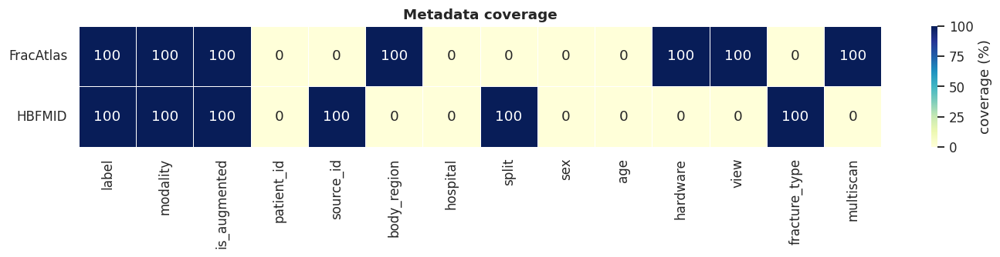

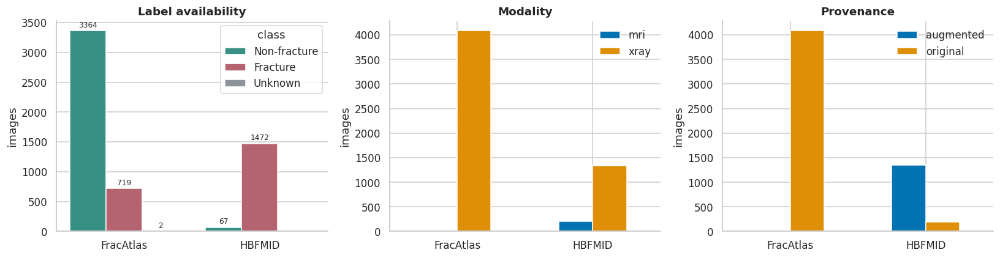

,dataset,labeled,positive,negative,prevalence,wilson_low,wilson_high,majority_class_accuracy
0,FracAtlas,4083,719,3364,0.1761,0.1647,0.1881,0.8239
1,HBFMID,1539,1472,67,0.9565,0.9451,0.9656,0.9565


[INFO] FracAtlas: prevalence 17.6%; use class weights / balanced sampling (a majority guess already scores 82.4%).


In [5]:
cov = df.groupby('dataset')[META].agg(lambda x: 100 * x.notna().mean()).apply(pd.to_numeric).astype('float64').round(1)
display(cov)
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(cov, annot=True, fmt='.0f', cmap='YlGnBu', vmin=0, vmax=100, linewidths=.4, linecolor='white',
            cbar_kws={'label': 'coverage (%)'}, ax=ax)
ax.set(title='Metadata coverage', ylabel=''); ax.tick_params(axis='y', rotation=0); finish(fig, '01_metadata_coverage')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cls = good.groupby(['dataset', 'class']).size().rename('n').reset_index()
sns.barplot(data=cls, x='dataset', y='n', hue='class', hue_order=['Non-fracture', 'Fracture', 'Unknown'],
            palette=COLORS, ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c, fmt='%.0f', fontsize=8, padding=2)
axes[0].set(title='Label availability', xlabel='', ylabel='images')
for ax, c in zip(axes[1:], ['modality', 'is_augmented']):
    vals = good[c].astype('string').fillna('unknown')
    if c == 'is_augmented': vals = vals.replace({'0': 'original', '1': 'augmented'})
    tab = pd.crosstab(good.dataset, vals)
    tab.plot.bar(ax=ax, rot=0, color=sns.color_palette('colorblind', len(tab.columns)))
    ax.set(title={'modality': 'Modality', 'is_augmented': 'Provenance'}[c], xlabel='', ylabel='images'); ax.legend(frameon=False)
finish(fig, '02_labels_modality_provenance')

bal = []
for name, g in good.groupby('dataset'):
    y = g.label.dropna().astype(int); n, k = len(y), int(y.sum())
    if n:
        z = 1.96; ctr = (k / n + z * z / (2 * n)) / (1 + z * z / n)
        half = z * np.sqrt(k / n * (1 - k / n) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        bal.append(dict(dataset=name, labeled=n, positive=k, negative=n - k, prevalence=round(k / n, 4),
                        wilson_low=round(ctr - half, 4), wilson_high=round(ctr + half, 4),
                        majority_class_accuracy=round(max(k, n - k) / n, 4)))
bal = pd.DataFrame(bal); export(bal, 'class_balance'); display(bal)
for r in bal.itertuples():
    if r.positive in (0, r.labeled):
        note('warn', f'{r.dataset}: all labeled images are one class -> AUROC/specificity are not estimable; report sensitivity only.')
    elif r.prevalence < .3:
        note('info', f'{r.dataset}: prevalence {r.prevalence:.1%}; use class weights / balanced sampling (a majority guess already scores {r.majority_class_accuracy:.1%}).')

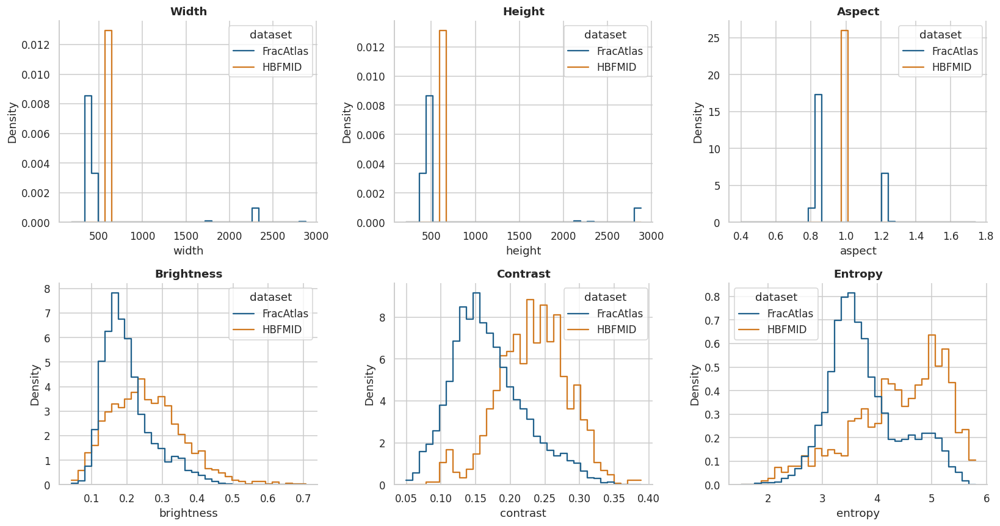

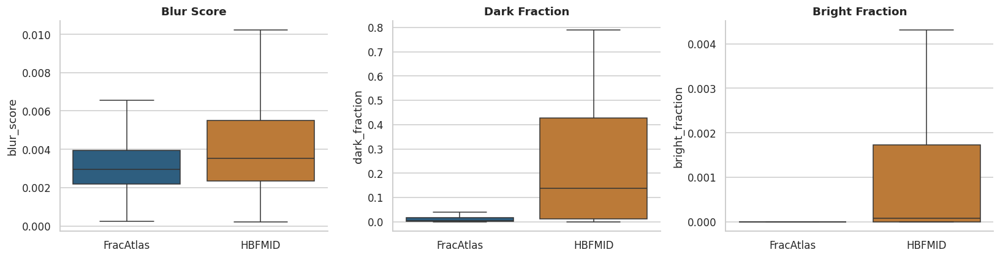

Flags are for review only; subtle fractures can look "blurry". Nothing is deleted automatically.


,small_image,near_constant,needs_decode_review,low_sharpness_1pct
dataset,,,,
FracAtlas,0,0,0,41
HBFMID,0,0,0,16


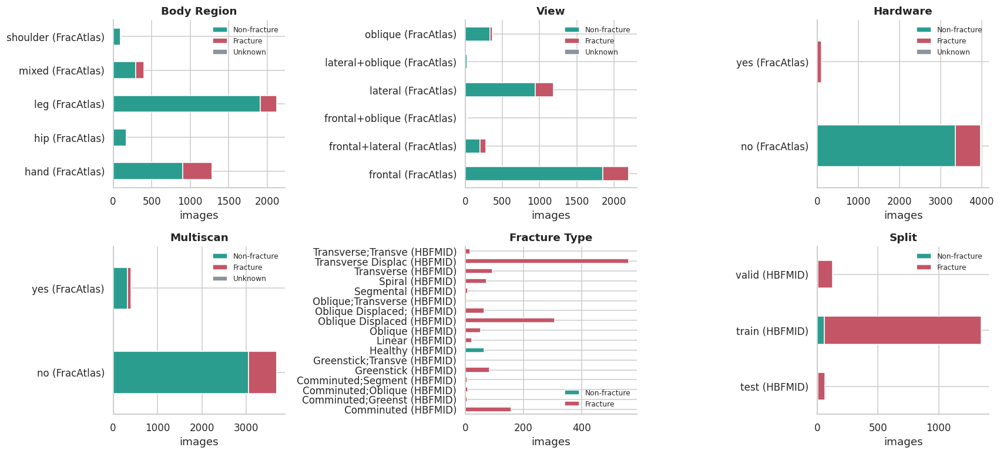

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), ['width', 'height', 'aspect', 'brightness', 'contrast', 'entropy']):
    sns.histplot(data=good, x=c, hue='dataset', palette=COLORS, element='step', fill=False, stat='density',
                 common_norm=False, bins=35, ax=ax); ax.set_title(c.title())
finish(fig, '03_resolution_intensity')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['blur_score', 'dark_fraction', 'bright_fraction']):
    sns.boxplot(data=good, x='dataset', y=c, hue='dataset', palette=COLORS, showfliers=False, ax=ax, legend=False)
    ax.set_title(c.replace('_', ' ').title()); ax.set_xlabel('')
finish(fig, '04_quality_distributions')

q = good[['dataset', 'path', 'width', 'height', 'frames', 'high_bit_depth', 'contrast', 'blur_score']].copy()
q['small_image'] = (q.width < 128) | (q.height < 128)
q['near_constant'] = q.contrast < .01
q['needs_decode_review'] = q.high_bit_depth | (q.frames > 1)
q['low_sharpness_1pct'] = q.blur_score < q.groupby('dataset').blur_score.transform(lambda x: x.quantile(.01))
export(q, 'quality_flags')
print('Flags are for review only; subtle fractures can look "blurry". Nothing is deleted automatically.')
display(q.groupby('dataset')[['small_image', 'near_constant', 'needs_decode_review', 'low_sharpness_1pct']].sum())

cols = [c for c in ['body_region', 'view', 'hardware', 'multiscan', 'fracture_type', 'split'] if good[c].notna().any()]
if cols:
    nc = 3; nr = int(np.ceil(len(cols) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(5.2 * nc, 3.6 * nr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, c in zip(axes.ravel(), cols):
        ax.axis('on'); sub = good[good[c].notna()]
        tab = pd.crosstab(sub[c].astype(str).str[:18] + ' (' + sub.dataset + ')', sub['class'])
        tab = tab[[x for x in ['Non-fracture', 'Fracture', 'Unknown'] if x in tab.columns]]
        tab.plot.barh(stacked=True, ax=ax, color=[COLORS[x] for x in tab.columns])
        ax.set(title=c.replace('_', ' ').title(), ylabel='', xlabel='images'); ax.legend(frameon=False, fontsize=8)
    finish(fig, '05_metadata_by_class')

## 3.4 · Label sanity check against bounding boxes (FracAtlas COCO, if present)

COCO file: COCO_fracture_masks.json | boxes 924 (invalid 0)


has_box,0,1
label,,
0,3364,0
1,0,719


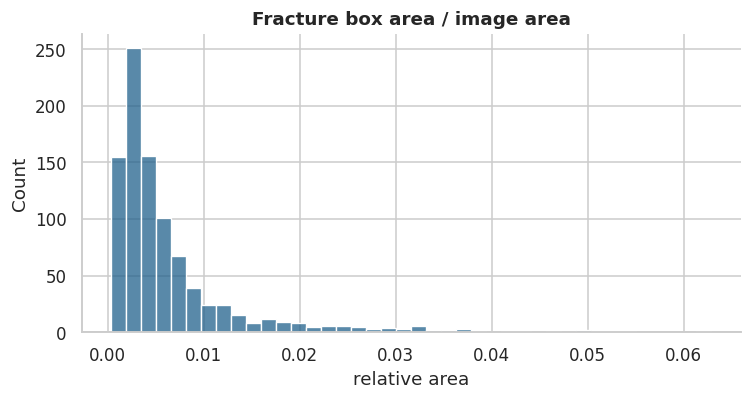

In [7]:
def find_coco(root):
    for p in sorted(root.rglob('*.json')):
        if p.stat().st_size > 300e6: continue
        try: obj = json.loads(p.read_text())
        except Exception: continue
        if isinstance(obj, dict) and {'images', 'annotations'} <= obj.keys(): return p, obj
    return None, None

coco_path, coco = find_coco(ROOTS['FracAtlas'])
good['has_box'] = pd.NA
if coco is None:
    print('No COCO annotation JSON found under the FracAtlas root; box check skipped (not verified).')
else:
    imgs = {i['id']: i for i in coco['images']}; boxes = []
    for a in coco['annotations']:
        r = imgs.get(a.get('image_id')); b = a.get('bbox') or []
        if r is None or len(b) != 4: continue
        W, H = r.get('width'), r.get('height')
        ok = bool(np.isfinite(b).all() and b[2] > 0 and b[3] > 0 and b[0] >= 0 and b[1] >= 0 and W and H
                  and b[0] + b[2] <= W + 1 and b[1] + b[3] <= H + 1)
        boxes.append(dict(file=Path(r['file_name']).name, valid=ok, rel_area=b[2] * b[3] / (W * H) if ok else np.nan))
    boxes = pd.DataFrame(boxes)
    with_box = set(boxes.loc[boxes.valid, 'file'])
    fa = good.dataset.eq('FracAtlas')
    good.loc[fa, 'has_box'] = good.loc[fa, 'filename'].isin(with_box).astype(int)
    chk = good.loc[fa & good.label.notna()].copy(); chk['has_box'] = chk.has_box.astype(int)
    print(f'COCO file: {coco_path.name} | boxes {len(boxes):,} (invalid {int((~boxes.valid).sum())})')
    display(pd.crosstab(chk.label.rename('label'), chk.has_box.rename('has_box')))
    dis = chk[chk.label != chk.has_box]
    export(dis[['relative_path', 'label', 'has_box']], 'label_vs_box_disagreements')
    if len(dis): note('warn', f'{len(dis)} FracAtlas images where label and box presence disagree (see label_vs_box_disagreements.csv).')
    if boxes.valid.any():
        fig, ax = plt.subplots(figsize=(7, 3.8)); sns.histplot(boxes.loc[boxes.valid, 'rel_area'], bins=40, color=COLORS['FracAtlas'], ax=ax)
        ax.set(title='Fracture box area / image area', xlabel='relative area'); finish(fig, '06_box_scale')

## 3.5 · Exact and near duplicates → leakage-safe families

In [8]:
# ---- exact duplicates
ex = []
for col in ['sha256', 'pixel_sha256']:
    d = good[good.duplicated(col, keep=False)]
    if len(d): ex.append(d[['dataset', 'relative_path', 'label', 'split', col]].rename(columns={col: 'hash'}).assign(type=col))
exact = pd.concat(ex, ignore_index=True) if ex else pd.DataFrame(columns=['dataset', 'relative_path', 'label', 'split', 'hash', 'type'])
export(exact, 'exact_duplicates')
redundant = len(good) - good.pixel_sha256.nunique()
conf_ids = good.groupby('pixel_sha256').label.nunique().loc[lambda s: s > 1].index
conflicts = good[good.pixel_sha256.isin(conf_ids)]
export(conflicts[['dataset', 'relative_path', 'label', 'pixel_sha256']], 'exact_label_conflicts')
print(f'Exact: {len(exact)} duplicate records, {redundant} redundant copies | label-conflict records: {len(conflicts)}')
by_ds = good.groupby('dataset').pixel_sha256.agg(lambda s: len(s) - s.nunique())
note('info', f'redundant exact copies per dataset: { {k: int(v) for k, v in by_ds.items()} }')
if len(conflicts): note('warn', f'{len(conflicts)} images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.')

# ---- near duplicates: BK-tree on dHash, verified by thumbnail correlation
class BKTree:
    def __init__(self): self.root = None
    def add(self, v, i):
        if self.root is None: self.root = [v, [i], {}]; return
        node = self.root
        while True:
            d = popcount(v ^ node[0])
            if d == 0: node[1].append(i); return
            if d not in node[2]: node[2][d] = [v, [i], {}]; return
            node = node[2][d]
    def query(self, v, r):
        stack = [self.root] if self.root else []
        while stack:
            nv, ids, ch = stack.pop(); d = popcount(v ^ nv)
            if d <= r:
                for i in ids: yield i, d
            stack.extend(c for e, c in ch.items() if d - r <= e <= d + r)

H = [int(h, 16) for h in good.dhash]; px = good.pixel_sha256.values
tree, pr, truncated = BKTree(), [], False
for i in tqdm(range(len(good)), desc='Near-duplicate search'):
    for j, d in tree.query(H[i], NEAR_RADIUS):
        if px[j] != px[i]: pr.append((j, i, d))
    if len(pr) >= MAX_NEAR_PAIRS: truncated = True; break
    tree.add(H[i], i)
P = np.array(pr, dtype=int).reshape(-1, 3)

X = np.stack([tiny_map[p] for p in good.path]); X = X - X.mean(1, keepdims=True)
nrm = np.linalg.norm(X, axis=1, keepdims=True); Z = np.divide(X, nrm, out=np.zeros_like(X), where=nrm > 0)
corr = np.concatenate([(Z[P[k:k + 20000, 0]] * Z[P[k:k + 20000, 1]]).sum(1) for k in range(0, len(P), 20000)]) if len(P) else np.array([])
near = pd.DataFrame({'path_a': good.path.values[P[:, 0]], 'path_b': good.path.values[P[:, 1]],
                     'dataset_a': good.dataset.values[P[:, 0]], 'dataset_b': good.dataset.values[P[:, 1]],
                     'dhash_dist': P[:, 2], 'corr': corr.round(4)})
near['tier'] = np.select([(near.dhash_dist <= AUTO_GROUP_DIST) & (near['corr'] >= AUTO_GROUP_CORR), near['corr'] >= REVIEW_MIN_CORR],
                         ['auto_group', 'review'], 'distinct_auto')
near['decision'] = ''
if NEAR_REVIEW_CSV:
    dec = pd.read_csv(NEAR_REVIEW_CSV).fillna('')
    near = near.drop(columns='decision').merge(dec[['path_a', 'path_b', 'decision']], on=['path_a', 'path_b'], how='left').fillna({'decision': ''})
    assert near.decision.isin(['', 'same_source', 'distinct']).all(), 'decision must be same_source / distinct / blank'
near['link'] = ((near.decision == 'same_source') | ((near.decision == '') & (near.tier == 'auto_group'))
                | ((near.decision == '') & (near.tier == 'review') & GROUP_UNREVIEWED))
export(near.loc[near.tier != 'distinct_auto'].sort_values(['tier', 'corr'], ascending=[True, False]).drop(columns='link'), 'near_duplicate_review')
print(f'Near candidates {len(near):,} (search truncated: {truncated})')
display(pd.crosstab(near.tier, (near.dataset_a != near.dataset_b).map({True: 'cross-dataset', False: 'within dataset'})))
if truncated: note('error', 'near-duplicate search hit MAX_NEAR_PAIRS; raise it and rerun before splitting.')

# ---- families (union-find)
parent = list(range(len(good)))
def find(i):
    while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b): parent[find(b)] = find(a)
for key, scope in [('sha256', None), ('pixel_sha256', None), ('patient_id', 'dataset'), ('source_id', 'dataset')]:
    sub = good.dropna(subset=[key])
    for ids in (sub.groupby(key) if scope is None else sub.groupby([scope, key])).groups.values():
        ids = list(ids)
        for j in ids[1:]: union(ids[0], j)
pos = dict(zip(good.path, good.index))
for r in near.loc[near.link].itertuples(): union(pos[r.path_a], pos[r.path_b])
good['group_id'] = [f'g{find(i):06d}' for i in good.index]
gs = good.groupby('group_id').size()
print(f'Families: {len(gs):,} | multi-image families: {(gs > 1).sum():,} | largest family: {gs.max()} images ({gs.max() / len(good):.1%})')
if gs.max() / len(good) > .05: note('warn', 'one family holds >5% of all images: loosen GROUP_UNREVIEWED or AUTO_GROUP_CORR, or review near_duplicate_review.csv.')
ov = good.groupby('group_id').agg(datasets=('dataset', 'nunique'), splits=('split', 'nunique'), images=('path', 'size'))
export(ov.loc[(ov.datasets > 1) | (ov.splits > 1)].reset_index(), 'families_spanning_datasets_or_splits')
n_x = int((ov.datasets > 1).sum()); n_s = int((ov.splits > 1).sum())
if n_x: note('warn', f'{n_x} families contain images from BOTH datasets (external-set overlap; removed from the external set later).')
if n_s: note('warn', f'{n_s} families span more than one published split (publisher splits leak; this notebook re-splits).')
summary.update(exact_redundant=int(redundant), label_conflict_records=len(conflicts), near_candidates=len(near),
               near_auto_group=int((near.tier == 'auto_group').sum()), near_review=int((near.tier == 'review').sum()),
               near_truncated=bool(truncated), families=int(len(gs)), largest_family=int(gs.max()))
export(good, 'grouped_image_audit')

Exact: 198 duplicate records, 86 redundant copies | label-conflict records: 7
[INFO] redundant exact copies per dataset: {'FracAtlas': 86, 'HBFMID': 0}
[WARN] 7 images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.


Near-duplicate search:   0%|          | 0/5624 [00:00<?, ?it/s]

Near candidates 941 (search truncated: False)


col_0,cross-dataset,within dataset
tier,,
auto_group,0,195
distinct_auto,0,122
review,16,608


Families: 4,029 | multi-image families: 440 | largest family: 52 images (0.9%)
[WARN] 3 families contain images from BOTH datasets (external-set overlap; removed from the external set later).
[WARN] 20 families span more than one published split (publisher splits leak; this notebook re-splits).


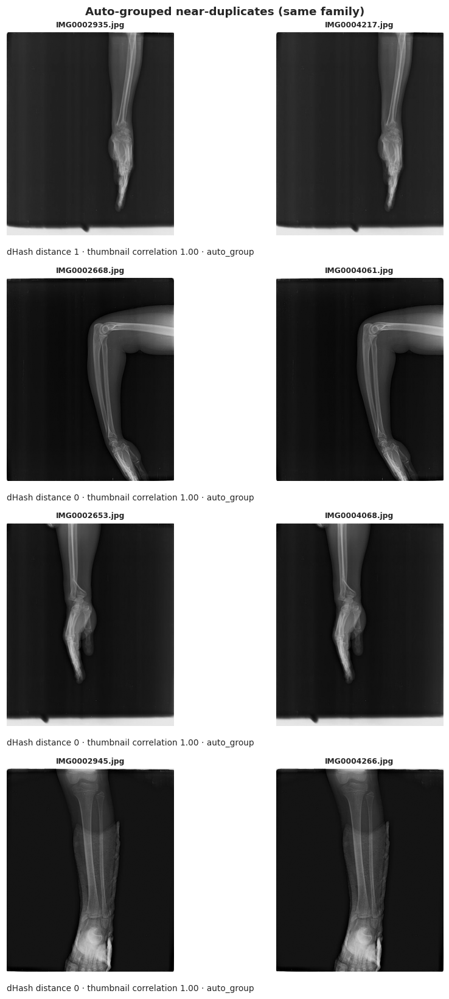

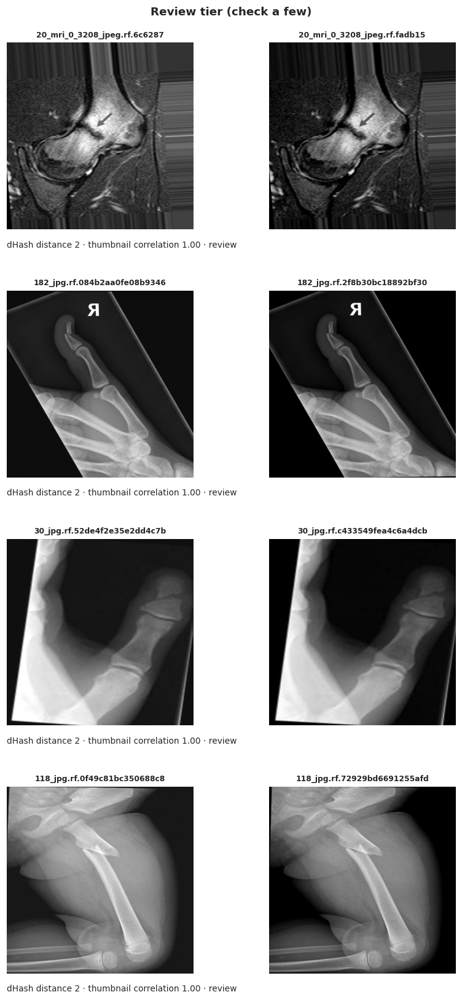

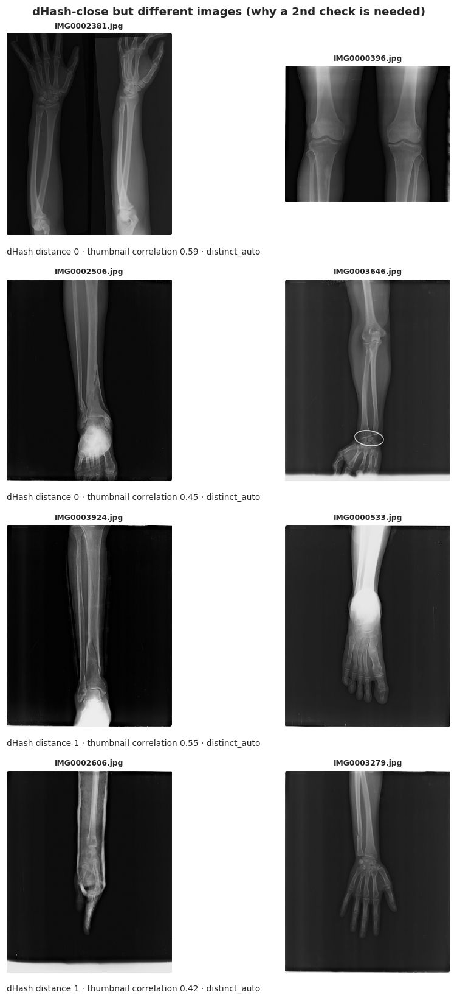

In [9]:
def pair_gallery(pairs, title, name, n=4):
    pairs = pairs.head(n)
    if pairs.empty: return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3.8 * len(pairs)), squeeze=False)
    for row, (_, r) in zip(axes, pairs.iterrows()):
        for ax, p in zip(row, [r.path_a, r.path_b]):
            with Image.open(p) as im: g = safe_rgb(im).convert('L'); g.thumbnail((480, 480))
            ax.imshow(g, cmap='gray', vmin=0, vmax=255); ax.axis('off')
        row[0].set_title(Path(r.path_a).name[:28], fontsize=8); row[1].set_title(Path(r.path_b).name[:28], fontsize=8)
        row[0].text(0.0, -0.06, f'dHash distance {r.dhash_dist} · thumbnail correlation {r["corr"]:.2f} · {r.tier}',
                    transform=row[0].transAxes, fontsize=9, va='top')
    fig.suptitle(title, fontsize=12, fontweight='bold'); finish(fig, name, svg=False)

if DISPLAY_GALLERIES:
    pair_gallery(near[near.tier == 'auto_group'].sort_values('corr', ascending=False), 'Auto-grouped near-duplicates (same family)', '07_pairs_auto')
    pair_gallery(near[near.tier == 'review'].sort_values('corr', ascending=False), 'Review tier (check a few)', '07_pairs_review')
    pair_gallery(near[near.tier == 'distinct_auto'].sort_values('dhash_dist'), 'dHash-close but different images (why a 2nd check is needed)', '07_pairs_rejected')

## 3.6 · Galleries and dataset shift

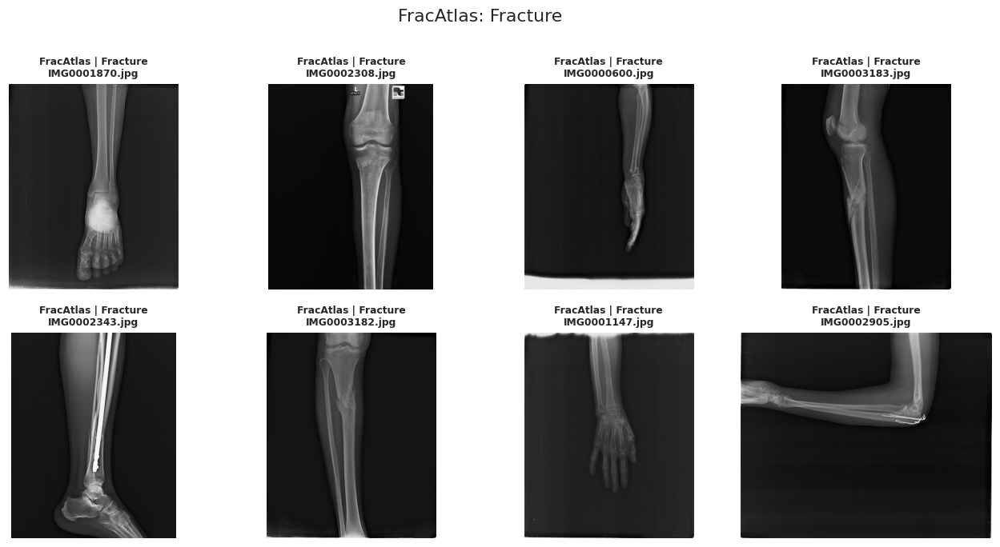

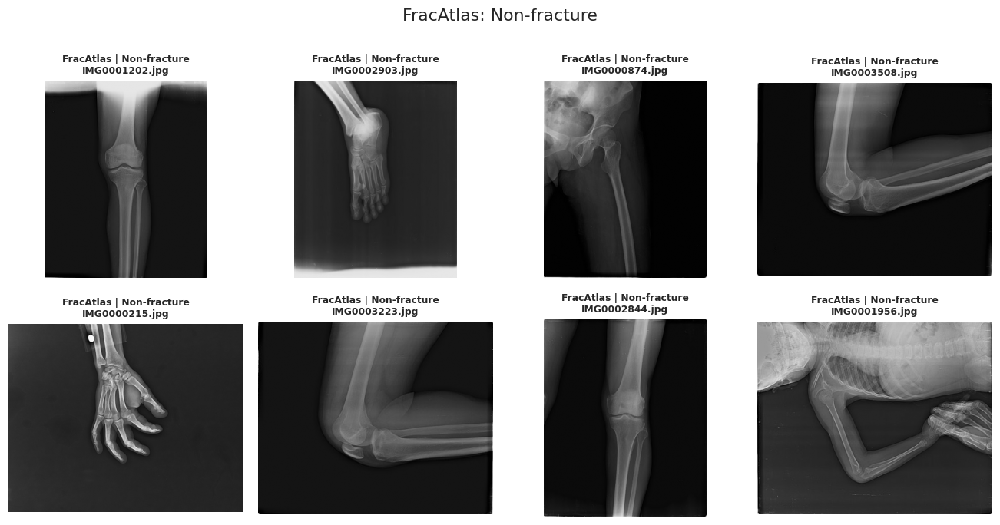

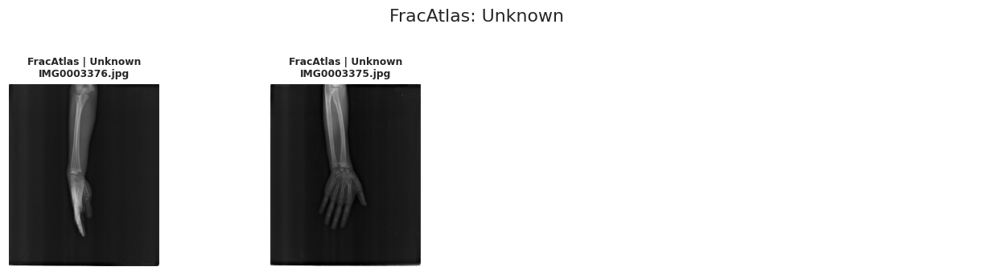

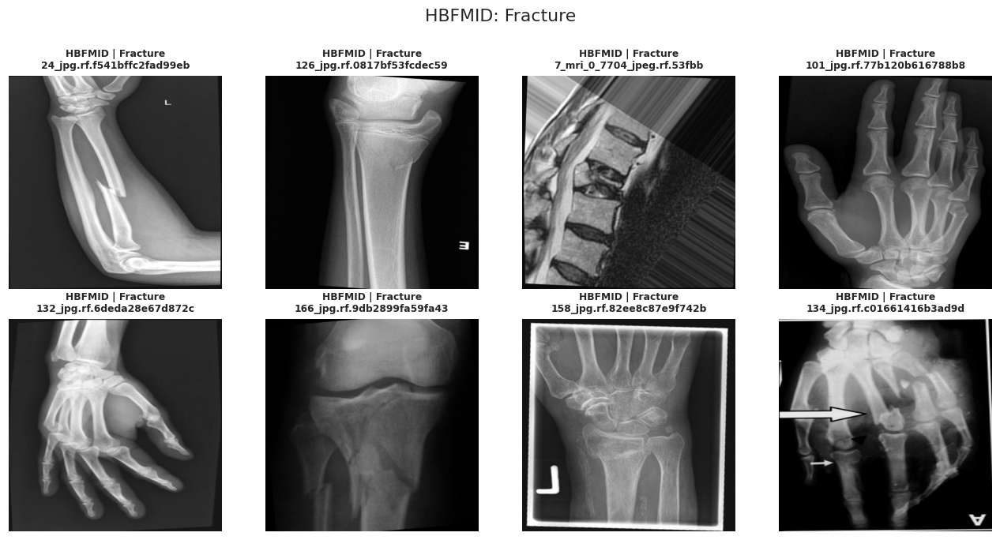

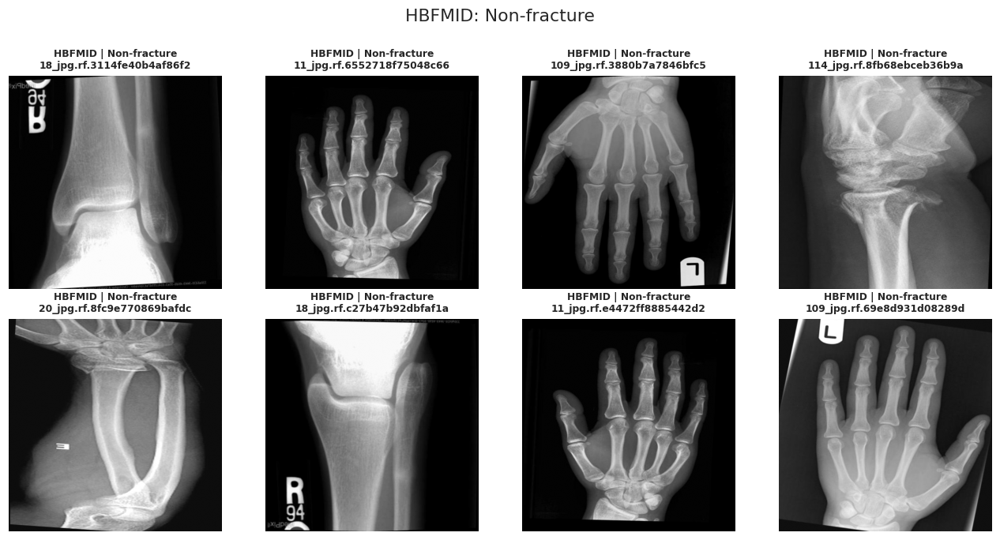

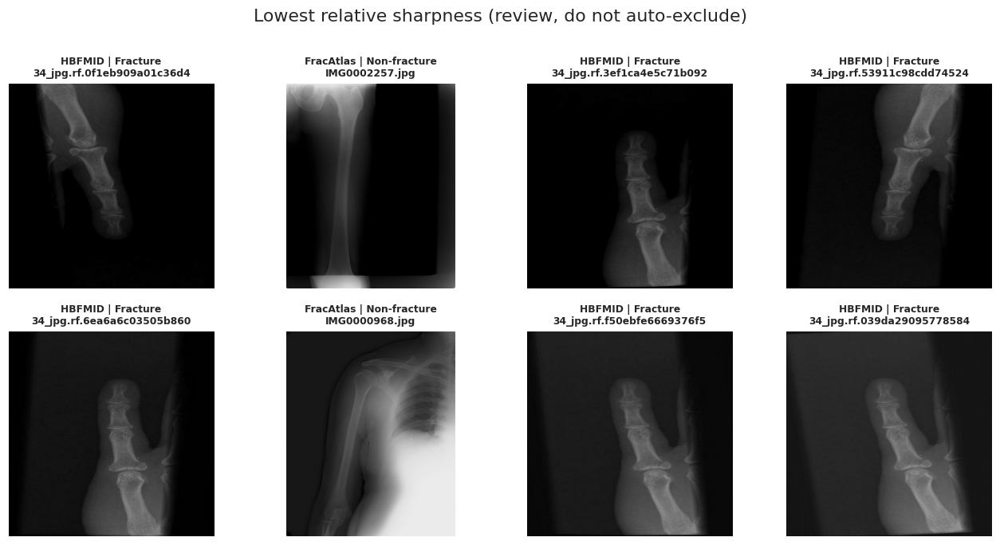

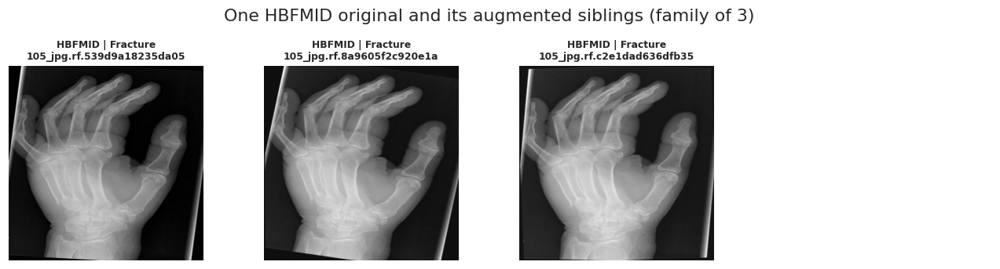

,aspect,brightness,contrast,entropy,blur_score,dark_fraction,bright_fraction,border_mean
dataset,,,,,,,,
FracAtlas,0.822,0.186,0.160,3.645,0.003,0.004,0.0,0.307
HBFMID,1.000,0.247,0.236,4.531,0.004,0.137,0.0,0.081


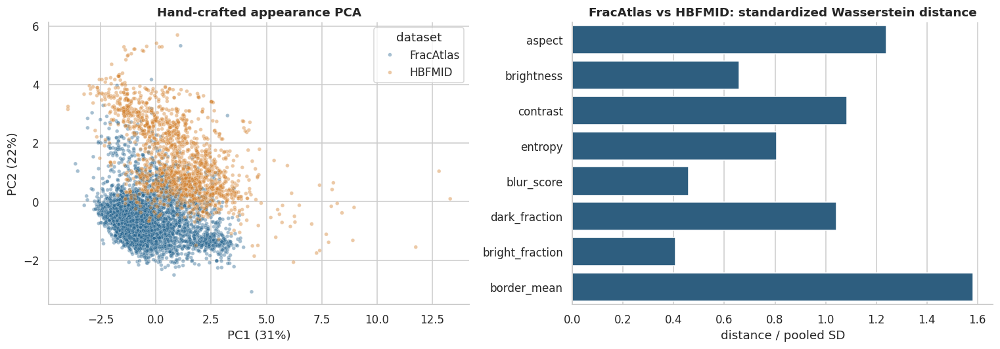

In [10]:
def gallery(rows, title, name, cols=4):
    rows = rows.head(12)
    if rows.empty: return
    nr = int(np.ceil(len(rows) / cols))
    fig, axes = plt.subplots(nr, cols, figsize=(cols * 3, 3.1 * nr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        with Image.open(r.path) as im: g = safe_rgb(im).convert('L'); g.thumbnail((512, 512))
        ax.imshow(g, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{r.dataset} | {r["class"]}\n{Path(r.path).name[:26]}', fontsize=8)
    fig.suptitle(title, y=1.0); finish(fig, name, svg=False)

if DISPLAY_GALLERIES:
    for (ds, cl), sub in good.groupby(['dataset', 'class']):
        gallery(sub.sample(min(8, len(sub)), random_state=SEED), f'{ds}: {cl}', f'08_gallery_{ds}_{cl}')
    gallery(good.nsmallest(8, 'blur_score'), 'Lowest relative sharpness (review, do not auto-exclude)', '09_low_sharpness')
    fam = good[(good.dataset == 'HBFMID') & good.source_id.notna()]
    sizes = fam.groupby('source_id').size(); pick = sizes[sizes == 3].index
    if len(pick): gallery(fam[fam.source_id == pick[0]], 'One HBFMID original and its augmented siblings (family of 3)', '10_hbfmid_family')

FEATURES = ['aspect', 'brightness', 'contrast', 'entropy', 'blur_score', 'dark_fraction', 'bright_fraction', 'border_mean']
display(good.groupby('dataset')[FEATURES].median().round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(good) >= 3 and good.dataset.nunique() > 1:
    zc = PCA(2, random_state=SEED).fit(StandardScaler().fit_transform(good[FEATURES].fillna(0)))
    emb = zc.transform(StandardScaler().fit_transform(good[FEATURES].fillna(0)))
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=good.dataset, palette=COLORS, alpha=.4, s=14, ax=axes[0])
    axes[0].set(title='Hand-crafted appearance PCA', xlabel=f'PC1 ({zc.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({zc.explained_variance_ratio_[1]:.0%})')
    a_n, b_n = good.dataset.unique()[:2]; sh = []
    for c in FEATURES:
        a = good.loc[good.dataset == a_n, c].dropna(); b = good.loc[good.dataset == b_n, c].dropna(); sd = good[c].std()
        sh.append({'feature': c, 'shift': wasserstein_distance(a, b) / sd if sd > 0 else np.nan})
    sh = pd.DataFrame(sh); export(sh, 'appearance_shift')
    sns.barplot(data=sh, x='shift', y='feature', color=COLORS['FracAtlas'], ax=axes[1])
    axes[1].set(title=f'{a_n} vs {b_n}: standardized Wasserstein distance', xlabel='distance / pooled SD', ylabel='')
finish(fig, '11_dataset_shift')

## 3.7 · Eligibility waterfall

In [11]:
def waterfall(frame, steps):
    cur = frame; rows = [('readable', len(cur), int(cur.label.fillna(0).sum()))]
    for text, fn in steps:
        cur = cur.loc[fn(cur).fillna(False).astype(bool)]
        rows.append((text, len(cur), int(cur.label.fillna(0).sum())))
    return cur, pd.DataFrame(rows, columns=['step', 'images', 'fractured'])

common = [('single-frame, not high-bit-depth', lambda d: (d.frames == 1) & ~d.high_bit_depth),
          ('not a label-conflict copy', lambda d: ~d.pixel_sha256.isin(conf_ids)),
          ('label agrees with COCO boxes (if available)', lambda d: pd.to_numeric(d.has_box, errors='coerce').isna()
                                                                   | (pd.to_numeric(d.has_box, errors='coerce') == d.label.astype('float')))]
prim_pool, wf_p = waterfall(good[good.dataset == 'FracAtlas'].sort_values('relative_path'),
    [('label known', lambda d: d.label.notna()), ('X-ray', lambda d: d.modality.eq('xray')),
     ('original (not augmented)', lambda d: d.is_augmented.eq(0))] + common)
primary = prim_pool.drop_duplicates('pixel_sha256').copy()
wf_p.loc[len(wf_p)] = ['exact duplicates removed', len(primary), int(primary.label.sum())]
ext_pool, wf_e = waterfall(good[good.dataset == 'HBFMID'],
    [('label known', lambda d: d.label.notna()), ('X-ray', lambda d: d.modality.eq('xray')),
     ('original (valid/test, not augmented)', lambda d: d.is_augmented.eq(0))] + common)
external = ext_pool.drop_duplicates('pixel_sha256').copy()
overlap = external.group_id.isin(primary.group_id)
export(external[overlap], 'external_overlap_exclusions')
external = external[~overlap].copy()
wf_e.loc[len(wf_e)] = ['no overlap with FracAtlas families', len(external), int(external.label.sum())]
display(wf_p.assign(set='FracAtlas (primary)')); display(wf_e.assign(set='HBFMID (external)'))
export(pd.concat([wf_p.assign(set='primary'), wf_e.assign(set='external')]), 'eligibility_waterfall')
export(good[~good.path.isin(set(primary.path) | set(external.path))][['dataset', 'relative_path', 'label', 'modality', 'is_augmented', 'group_id']], 'excluded_or_unresolved')
n_neg_ext = int((external.label == 0).sum()) if len(external) else 0
if len(external) and n_neg_ext < 30:
    note('warn', f'External set has only {n_neg_ext} negatives (HBFMID "Healthy", mostly augmented copies of few originals): '
                 'specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.')
if primary.empty: note('error', 'No eligible FracAtlas images; fix labels/metadata (sections 2-3) before continuing.')
if external.empty:
    why = 'HBFMID has no labels' if good[good.dataset == 'HBFMID'].label.isna().all() else 'no labeled X-ray originals remain'
    note('warn', f'External set is empty: {why}. HBFMID stays pending until labels/originals are confirmed.')
elif external.label.nunique() < 2:
    note('warn', f'External set is single-class (all label={int(external.label.iloc[0])}): report sensitivity only; no AUROC/specificity.')
summary.update(primary_images=len(primary), primary_positive=int(primary.label.sum()) if len(primary) else 0,
               external_images=len(external), external_single_class=bool(len(external) and external.label.nunique() < 2))

,step,images,fractured,set
0,readable,4085,719,FracAtlas (primary)
1,label known,4083,719,FracAtlas (primary)
2,X-ray,4083,719,FracAtlas (primary)
3,original (not augmented),4083,719,FracAtlas (primary)
4,"single-frame, not high-bit-depth",4083,719,FracAtlas (primary)
5,not a label-conflict copy,4076,716,FracAtlas (primary)
6,label agrees with COCO boxes (if available),4076,716,FracAtlas (primary)
7,exact duplicates removed,3996,701,FracAtlas (primary)


,step,images,fractured,set
0,readable,1539,1472,HBFMID (external)
1,label known,1539,1472,HBFMID (external)
2,X-ray,1337,1270,HBFMID (external)
3,"original (valid/test, not augmented)",164,154,HBFMID (external)
4,"single-frame, not high-bit-depth",164,154,HBFMID (external)
5,not a label-conflict copy,164,154,HBFMID (external)
6,label agrees with COCO boxes (if available),164,154,HBFMID (external)
7,no overlap with FracAtlas families,161,151,HBFMID (external)


[WARN] External set has only 10 negatives (HBFMID "Healthy", mostly augmented copies of few originals): specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.


## 3.8 · Grouped split, label budgets and training statistics

,images,fractured,families,prevalence,image_share
proposed_split,,,,,
test,771,122,711,0.158,0.193
train,2821,507,2603,0.18,0.706
validation,404,72,374,0.178,0.101


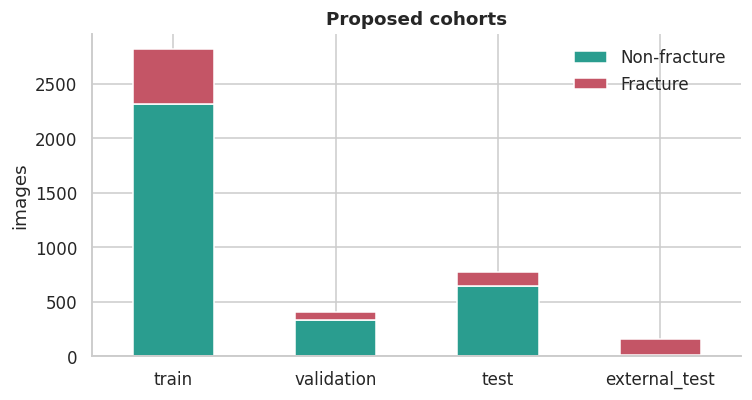

[INFO] label budgets [0.01] contain <10 fractured images: results at those sizes are very unstable.


,seed,fraction,families,images,image_share,fractured,non_fractured
0,42,0.01,27,29,0.010,5,24
1,42,0.05,131,135,0.048,24,111
2,42,0.10,261,268,0.095,49,219
3,42,0.25,652,728,0.258,135,593
4,42,1.00,2603,2821,1.000,507,2314


{
  "train_images": 2821,
  "class_weights": {
    "non_fracture": 0.6096,
    "fracture": 2.7821,
    "pos_weight_for_BCEWithLogits": 4.5641
  },
  "grayscale_mean": 0.2031,
  "grayscale_std": 0.1909,
  "note": "thumbnail estimate; recompute at final input size"
}


In [12]:
READY = False
if not MAKE_SPLITS: print('MAKE_SPLITS is False; skipped.')
elif primary.empty or truncated: note('error', 'Split skipped (no eligible images or incomplete near-duplicate search).')
elif primary.patient_id.isna().any() and not ALLOW_IMAGE_LEVEL_SPLIT: note('error', 'Patient IDs missing and ALLOW_IMAGE_LEVEL_SPLIT=False.')
elif primary.label.nunique() < 2 or primary.groupby('label').group_id.nunique().min() < 10:
    note('error', 'Need both classes with >=10 families each for the 10-fold design.')
else:
    primary = primary.reset_index(drop=True)
    folds = np.full(len(primary), -1)
    cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
    for k, (_, idx) in enumerate(cv.split(primary, primary.label.astype(int), primary.group_id)): folds[idx] = k
    primary['proposed_split'] = np.where(folds < 2, 'test', np.where(folds == 2, 'validation', 'train'))
    # hard guarantees
    assert primary.groupby('group_id').proposed_split.nunique().max() == 1, 'a family straddles splits'
    assert primary.groupby('pixel_sha256').proposed_split.nunique().max() == 1, 'identical pixels in two splits'
    for s, g in primary.groupby('proposed_split'): assert g.label.nunique() == 2, f'{s} has one class'
    primary['patient_level'] = primary.patient_id.notna()
    external['proposed_split'] = 'external_test'
    manifest = pd.concat([primary, external], ignore_index=True)
    export(manifest.drop(columns=['tiny'], errors='ignore'), 'split_manifest')
    tab = primary.groupby('proposed_split').agg(images=('path', 'size'), fractured=('label', 'sum'), families=('group_id', 'nunique'))
    tab['prevalence'] = (tab.fractured / tab.images).round(3); tab['image_share'] = (tab.images / len(primary)).round(3)
    display(tab); export(tab.reset_index(), 'split_summary')
    fig, ax = plt.subplots(figsize=(7, 3.8))
    (pd.crosstab(manifest.proposed_split, manifest.label).rename(columns={0: 'Non-fracture', 1: 'Fracture'})
       .reindex(['train', 'validation', 'test', 'external_test']).dropna(how='all')
       .plot.bar(stacked=True, ax=ax, color=[COLORS['Non-fracture'], COLORS['Fracture']], rot=0))
    ax.set(title='Proposed cohorts', xlabel='', ylabel='images'); ax.legend(frameon=False); finish(fig, '12_split_counts')

    train = primary[primary.proposed_split == 'train']
    export(train[['path', 'group_id']], 'ssl_train_pool')
    gt = train.groupby('group_id').label.max()       # mixed-label family counts as positive
    bud, rows, tiny_budget = [], [], set()
    for seed in BUDGET_SEEDS:
        rng = np.random.default_rng(seed)
        order = {int(l): rng.permutation(gg.index.to_numpy()) for l, gg in gt.groupby(gt)}
        prev = set()
        for f in BUDGET_FRACTIONS:
            sel = set()
            for l, ids in order.items(): sel.update(ids[:max(1, int(np.ceil(len(ids) * f)))])
            assert prev <= sel; prev = sel
            sub = train[train.group_id.isin(sel)]
            if sub.label.nunique() < 2: note('warn', f'budget {f:.0%} seed {seed} has one class')
            if sub.label.sum() < 10: tiny_budget.add(f)
            rows.append(sub[['path', 'group_id', 'label']].assign(seed=seed, fraction=f))
            bud.append(dict(seed=seed, fraction=f, families=len(sel), images=len(sub), image_share=round(len(sub) / len(train), 3),
                            fractured=int(sub.label.sum()), non_fractured=int((sub.label == 0).sum())))
    if tiny_budget: note('info', f'label budgets {sorted(tiny_budget)} contain <10 fractured images: results at those sizes are very unstable.')
    export(pd.concat(rows), 'label_budgets'); bud = pd.DataFrame(bud); export(bud, 'label_budget_summary')
    display(bud[bud.seed == BUDGET_SEEDS[0]])

    n1, n0 = int(train.label.sum()), int((train.label == 0).sum())
    class_weights = {'non_fracture': round(len(train) / (2 * n0), 4), 'fracture': round(len(train) / (2 * n1), 4),
                     'pos_weight_for_BCEWithLogits': round(n0 / n1, 4)}
    npx = train.thumbnail_pixels.sum(); mean = train.intensity_sum.sum() / npx
    std = float(np.sqrt(max(0., train.intensity_sq_sum.sum() / npx - mean ** 2)))
    stats = {'train_images': len(train), 'class_weights': class_weights, 'grayscale_mean': round(float(mean), 4),
             'grayscale_std': round(std, 4), 'note': 'thumbnail estimate; recompute at final input size'}
    (OUT / 'train_statistics.json').write_text(json.dumps(stats, indent=2)); print(json.dumps(stats, indent=2))
    summary.update(splits_generated=True, patient_level_split=bool(primary.patient_id.notna().all()), train_stats=stats)
    READY = True
_ = summary.setdefault('splits_generated', False)

## 3.9 · Summary, findings and exports (data part)

,dataset,readable,labeled,xray,originals,augmented,unique_pixels,eligible
0,FracAtlas,4085,4083,4085,4085,0,3999,3996
1,HBFMID,1539,1539,1337,192,1347,1539,161


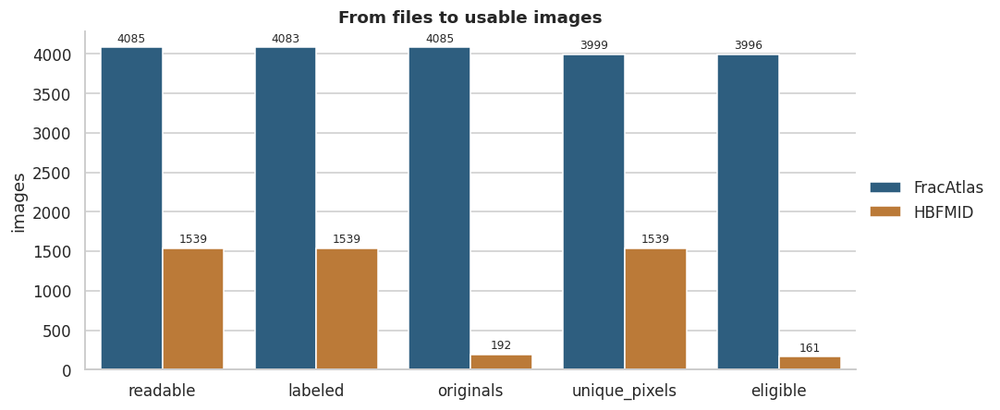


===== FINDINGS =====
[WARN ] FracAtlas: 4 files share a filename across folders (duplicate_filenames.csv). Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.
[WARN ] FracAtlas: 2 images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.
[WARN ] 7 images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.
[WARN ] 3 families contain images from BOTH datasets (external-set overlap; removed from the external set later).
[WARN ] 20 families span more than one published split (publisher splits leak; this notebook re-splits).
[WARN ] External set has only 10 negatives (HBFMID "Healthy", mostly augmented copies of few originals): specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.
[INFO ] HBFMID: 1,539/1,539 images matched to a YOLO label file.
[INFO ] FracAtlas: prevalence 17.6%; use class weights / bal

In [13]:
dash = good.groupby('dataset').agg(readable=('path', 'size'), labeled=('label', 'count'),
        xray=('modality', lambda s: int(s.eq('xray').sum())), originals=('is_augmented', lambda s: int(s.eq(0).sum())),
        augmented=('is_augmented', lambda s: int(s.eq(1).sum())), unique_pixels=('pixel_sha256', 'nunique')).reset_index()
dash['eligible'] = dash.dataset.map({'FracAtlas': len(primary), 'HBFMID': len(external)})
export(dash, 'executive_summary'); display(dash)
long = dash.melt(id_vars='dataset', value_vars=['readable', 'labeled', 'originals', 'unique_pixels', 'eligible'], var_name='stage', value_name='images')
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=long, x='stage', y='images', hue='dataset', palette=COLORS, ax=ax)
for c in ax.containers: ax.bar_label(c, fmt='%.0f', fontsize=8, padding=2)
ax.set(title='From files to usable images', xlabel='', ylabel='images'); sns.move_legend(ax, 'center left', bbox_to_anchor=(1, .5), frameon=False, title=''); finish(fig, '15_executive_summary')

known_aug = int(good.is_augmented.notna().sum())
summary['augmentation_decision'] = ('FracAtlas: mild on-the-fly training-only augmentation + class weights; '
                                    'HBFMID: already augmented, add none, evaluate on originals only.')
(OUT / 'audit_summary.json').write_text(json.dumps(summary, indent=2, default=str))

print('\n===== FINDINGS =====')
order = {'error': 0, 'warn': 1, 'info': 2}
for lvl, msg in sorted(FINDINGS, key=lambda t: order[t[0]]): print(f'[{lvl.upper():5}] {msg}')
pd.DataFrame(FINDINGS, columns=['level', 'message']).to_csv(OUT / 'findings.csv', index=False)
print('\nData-part outputs so far:', OUT)

# Section 4: Data Preprocessing & Augmentation

## 4.1 · Augmentation policy (training only)
**Decision:** yes for FracAtlas training images, applied *on the fly after the split*; never to validation/test; never saved as extra files. **No** extra augmentation for HBFMID: its training folder is already augmented (rotation wedges and edge-fill streaks are visible in the family gallery).

Class imbalance (about 18 % fractures) is handled by metric choice (AUPRC, sensitivity/specificity) and by the threshold chosen on validation; the models use plain BCE with this mild augmentation on **both** classes. The preview below uses a mild, anatomy-preserving policy whose fill value is the image-border median, so it does not create the black wedges that HBFMID's pre-augmentation contains.

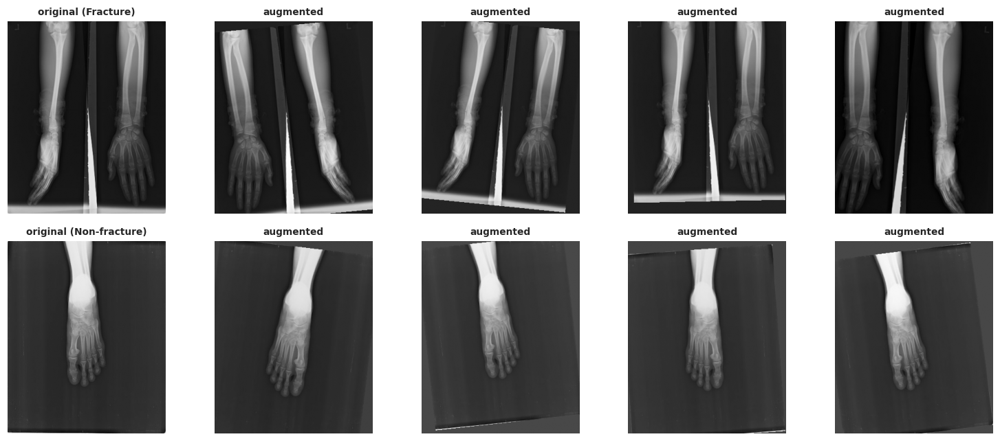

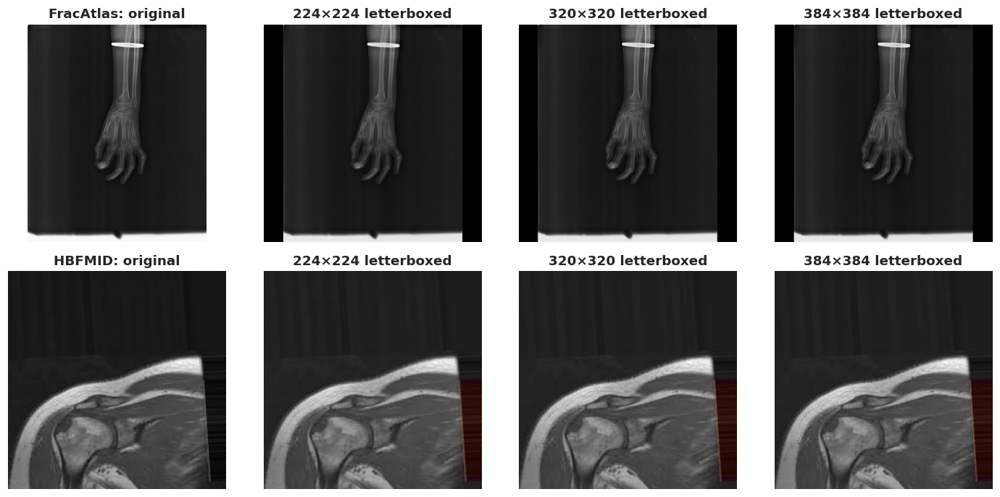

In [14]:
POLICY = {'apply_to': 'train split only, on the fly', 'rotation_deg': 10, 'scale': [0.92, 1.08], 'translate_frac': 0.05,
          'hflip_p': 0.5, 'brightness_shift': 0.05, 'contrast_range': [0.9, 1.1],
          'never': ['vertical flip', 'strong crop / random-erasing over the bone', 'elastic warps', 'any change to val/test'],
          'fill': 'border median (no black wedges)'}
(OUT / 'augmentation_policy.json').write_text(json.dumps(POLICY, indent=2))

def mild_aug(g, rng):
    w, h = g.size; cx, cy = w / 2, h / 2
    th = np.deg2rad(rng.uniform(-POLICY['rotation_deg'], POLICY['rotation_deg'])); sc = rng.uniform(*POLICY['scale'])
    tx, ty = rng.uniform(-1, 1, 2) * POLICY['translate_frac'] * np.array([w, h]); c, s = np.cos(th), np.sin(th)
    arr = np.asarray(g); border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    out = g.transform((w, h), Image.AFFINE, (c / sc, s / sc, cx - (c * cx + s * cy) / sc - tx,
                                              -s / sc, c / sc, cy - (-s * cx + c * cy) / sc - ty),
                      resample=Image.Resampling.BILINEAR, fillcolor=int(np.median(border)))
    if rng.random() < POLICY['hflip_p']: out = ImageOps.mirror(out)
    a = np.asarray(out, dtype=np.float32); m = a.mean()
    a = (a - m) * rng.uniform(*POLICY['contrast_range']) + m + rng.uniform(-1, 1) * POLICY['brightness_shift'] * 255
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

pool = train if READY else good[good.dataset == 'FracAtlas']
if DISPLAY_GALLERIES and len(pool):
    rng = np.random.default_rng(SEED)
    picks = [pool[pool.label == 1].sample(1, random_state=SEED).iloc[0]] if (pool.label == 1).any() else []
    picks += [pool[pool.label == 0].sample(1, random_state=SEED).iloc[0]] if (pool.label == 0).any() else []
    fig, axes = plt.subplots(len(picks), 5, figsize=(14, 3 * len(picks)), squeeze=False)
    for row, r in zip(axes, picks):
        with Image.open(r.path) as im: g = safe_rgb(im).convert('L'); g.thumbnail((384, 384))
        row[0].imshow(g, cmap='gray', vmin=0, vmax=255); row[0].set_title(f'original ({r["class"]})', fontsize=9)
        for ax in row[1:]: ax.imshow(mild_aug(g, rng), cmap='gray', vmin=0, vmax=255); ax.set_title('augmented', fontsize=9)
        for ax in row: ax.axis('off')
    finish(fig, '13_augmentation_preview', svg=False)

def letterbox(im, size):
    im = safe_rgb(im); r = ImageOps.contain(im, (size, size), Image.Resampling.LANCZOS)
    c = Image.new('RGB', (size, size)); c.paste(r, ((size - r.width) // 2, (size - r.height) // 2)); return c
if DISPLAY_GALLERIES:
    ex = good.groupby('dataset', group_keys=False).sample(1, random_state=SEED)
    fig, axes = plt.subplots(len(ex), 4, figsize=(13, 3.2 * len(ex)), squeeze=False)
    for row, (_, r) in zip(axes, ex.iterrows()):
        with Image.open(r.path) as im:
            row[0].imshow(safe_rgb(im).convert('L'), cmap='gray'); row[0].set_title(f'{r.dataset}: original')
            for ax, s in zip(row[1:], [224, 320, 384]): ax.imshow(letterbox(im, s)); ax.set_title(f'{s}×{s} letterboxed')
        for ax in row: ax.axis('off')
    finish(fig, '14_input_resolution_preview', svg=False)

## 4.2 · Load the frozen split, check for leakage, cache the model inputs
Images are decoded once, letterboxed (aspect ratio preserved) to a square, and kept in memory as 8-bit grayscale; the grayscale image is repeated to 3 channels for the ImageNet backbones. Normalisation statistics come from the **training** images only.

In [15]:
if not READY: raise RuntimeError('The split was not created (see FINDINGS above). Fix Section 3 first.')
man = manifest.copy()
need = {'path', 'label', 'proposed_split', 'group_id', 'dataset'}
if not need <= set(man.columns): raise ValueError(f'manifest is missing columns: {need - set(man.columns)}')
man = man.dropna(subset=['label']).copy(); man['label'] = man.label.astype(int)
parts = {s: man[man.proposed_split == s].reset_index(drop=True) for s in ['train', 'validation', 'test']}
ext = man[man.proposed_split == 'external_test'].reset_index(drop=True)
for a_, b_ in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert not (set(parts[a_].group_id) & set(parts[b_].group_id)), f'family leakage between {a_} and {b_}'
    assert not (set(parts[a_].path) & set(parts[b_].path)), f'file overlap between {a_} and {b_}'
for s, d_ in parts.items(): assert d_.label.nunique() == 2, f'{s} needs both classes'
split_tab = pd.DataFrame({s: dict(images=len(d_), fractured=int(d_.label.sum()), healthy=int((d_.label == 0).sum()),
                                  prevalence=round(d_.label.mean(), 3), families=d_.group_id.nunique())
                          for s, d_ in {**parts, 'external (HBFMID)': ext}.items() if len(d_)}).T
split_tab.to_csv(OUT / 'table_split_summary.csv'); display(split_tab)

def load_square(path, size):
    with Image.open(path) as im:
        g = safe_rgb(im).convert('L')
    g = ImageOps.contain(g, (size, size), Image.Resampling.LANCZOS)
    canvas = Image.new('L', (size, size), 0); canvas.paste(g, ((size - g.width) // 2, (size - g.height) // 2))
    return torch.from_numpy(np.asarray(canvas).copy())

paths = sorted(set(man.path))
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    IMGS = dict(zip(paths, tqdm(pool.map(lambda p: load_square(p, IMG_SIZE), paths), total=len(paths), desc='Caching images')))
_tr = torch.stack([IMGS[p] for p in parts['train'].path]).float() / 255.
MEAN, STD = float(_tr.mean()), float(_tr.std()); del _tr
n_pos, n_neg = int(parts['train'].label.sum()), int((parts['train'].label == 0).sum())
yv, yt, ytr = parts['validation'].label.values, parts['test'].label.values, parts['train'].label.values
gt = parts['test'].group_id.values; ye = ext.label.values if len(ext) else np.array([])
print(f'train mean/std at {IMG_SIZE}px: {MEAN:.4f}/{STD:.4f} | train positives {n_pos}, negatives {n_neg}, prevalence {n_pos / (n_pos + n_neg):.3f}')
print(f'Majority-class baseline on test: accuracy {1 - yt.mean():.3f}, sensitivity 0.000, AUROC 0.500 -> accuracy alone is not informative here.')

,images,fractured,healthy,prevalence,families
train,2821.0,507.0,2314.0,0.180,2603.0
validation,404.0,72.0,332.0,0.178,374.0
test,771.0,122.0,649.0,0.158,711.0
external (HBFMID),161.0,151.0,10.0,0.938,118.0


Caching images:   0%|          | 0/4157 [00:00<?, ?it/s]

train mean/std at 224px: 0.1665/0.1895 | train positives 507, negatives 2314, prevalence 0.180
Majority-class baseline on test: accuracy 0.842, sensitivity 0.000, AUROC 0.500 -> accuracy alone is not informative here.


# Section 5: Training Infrastructure

**Recipe.** Every model starts from torchvision ImageNet weights with a single-logit head. Loss = binary cross-entropy; mild augmentation on both classes; AdamW with a cosine schedule; early stopping on validation AUPRC; best epoch restored. Thresholds are picked on validation only. Training, validation and test results are shown for each model right after it is trained.

## 5.1 · Augmentation, dataset and model builder

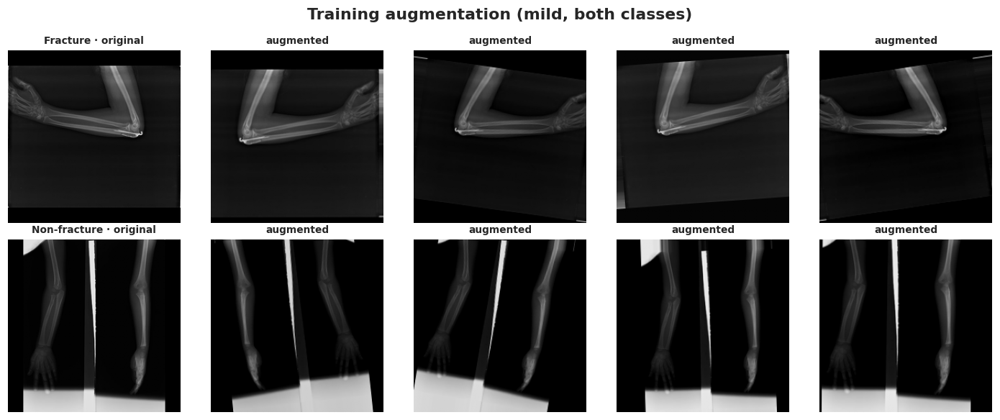

In [16]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  5.1  Augmentation · dataset · model builder                     ║
# ╚══════════════════════════════════════════════════════════════════╝
def augment(x, strength=1.0):
    # x: float [1,S,S] in 0..1 -> mild random affine + flip + intensity jitter, border-replicated
    u = lambda: float(torch.rand(1)) * 2 - 1
    ang = math.radians(10) * strength * u(); sc = 1 + 0.08 * strength * u()
    tx, ty = 0.10 * strength * u(), 0.10 * strength * u()          # 0.10 grid units = 5 % of the image
    c, s = math.cos(ang) / sc, math.sin(ang) / sc
    flip = -1.0 if torch.rand(1) < 0.5 else 1.0
    theta = torch.tensor([[c * flip, -s, tx], [s * flip, c, ty]], dtype=torch.float32)[None]
    grid = F.affine_grid(theta, (1, 1) + tuple(x.shape[-2:]), align_corners=False)
    out = F.grid_sample(x[None], grid, mode='bilinear', padding_mode='border', align_corners=False)[0]
    m = out.mean(); out = (out - m) * (1 + 0.10 * strength * u()) + m + 0.05 * strength * u()
    return out.clamp(0, 1)

class XrayDS(Dataset):
    def __init__(self, df, train=False):
        self.p, self.y, self.train = df.path.values, df.label.values, train
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        x = IMGS[self.p[i]].float().unsqueeze(0) / 255.; y = int(self.y[i])
        if self.train and AUG == 'all': x = augment(x)
        return ((x - MEAN) / STD).expand(3, -1, -1).contiguous(), torch.tensor(float(y))

class Wrap(nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return s.m(x).squeeze(1)

PRETRAINED_OK = {}
def build_model(name, pretrained=None):
    pretrained = PRETRAINED if pretrained is None else pretrained
    ctor = getattr(tvm, name); ok = bool(pretrained)
    try:
        m = ctor(weights='DEFAULT') if pretrained else ctor(weights=None)
    except Exception as e:
        print(f'WARNING [{name}]: pretrained weights unavailable ({type(e).__name__}); using random initialisation.'); m = ctor(weights=None); ok = False
    if name.startswith('resnet'): m.fc = nn.Linear(m.fc.in_features, 1)
    elif name.startswith('densenet'): m.classifier = nn.Linear(m.classifier.in_features, 1)
    else: m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 1)      # efficientnet / mobilenet_v3
    if pretrained: PRETRAINED_OK[name] = ok            # record only real (pretrained) builds
    return Wrap(m).to(DEVICE), ok

def cam_target(model, name):                                 # last convolutional stage, used for Grad-CAM
    m = model.m
    if name.startswith('resnet'): return m.layer4[-1]
    if name.startswith('densenet'): return m.features.denseblock4
    return m.features[-1]

def forward_probs(model, x_u8, bs=128):
    # x_u8: uint8 tensor [N,S,S] -> probabilities [N]; same normalisation as training
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(x_u8), bs):
            x = (x_u8[i:i + bs].float().unsqueeze(1) / 255. - MEAN) / STD
            out.append(torch.sigmoid(model(x.expand(-1, 3, -1, -1).to(DEVICE))).float().cpu())
    return torch.cat(out).numpy()

def predict(model, df):                                      # clean (un-augmented) predictions for a dataframe
    return forward_probs(model, torch.stack([IMGS[p] for p in df.path]))

_r = np.random.default_rng(0); _i = [int(_r.choice(parts['train'].index[parts['train'].label == 1])), int(_r.choice(parts['train'].index[parts['train'].label == 0]))]
torch.manual_seed(0); fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for row, i in zip(axes, _i):
    r = parts['train'].loc[i]; base = IMGS[r.path].float().unsqueeze(0) / 255.
    row[0].imshow(base[0], cmap='gray', vmin=0, vmax=1); row[0].set_title(('Fracture' if r.label else 'Non-fracture') + ' · original', fontsize=9)
    for ax in row[1:]: ax.imshow(augment(base)[0], cmap='gray', vmin=0, vmax=1); ax.set_title('augmented', fontsize=9)
    for ax in row: ax.axis('off')
fig.suptitle('Training augmentation (mild, both classes)', fontweight='bold'); finish(fig, 'S04_augmentation_examples', svg=False)

## 5.2 · Metrics, thresholds and confidence intervals

In [17]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  5.2  Metrics · thresholds · confidence intervals                ║
# ╚══════════════════════════════════════════════════════════════════╝
safe_auc = lambda y, p: roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
safe_ap  = lambda y, p: average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan
bce_np   = lambda y, p: float(-np.mean(y * np.log(np.clip(p, 1e-7, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-7, 1))))

def choose_threshold(y, p, rule=None):
    rule = rule or THRESHOLD_RULE; fpr, tpr, thr = roc_curve(y, p)
    if rule == 'youden': return float(thr[np.argmax(tpr - fpr)])
    if rule == 'spec90':
        ok = np.where((1 - fpr) >= SPEC_TARGET)[0]; return float(thr[ok[np.argmax(tpr[ok])]]) if len(ok) else float(thr[0])
    if rule == 'sens90':
        ok = np.where(tpr >= SENS_TARGET)[0]; return float(thr[ok[0]]) if len(ok) else float(thr[-1])
    raise ValueError(rule)

def confusion(y, p, t):
    pred = p >= t; y1 = y == 1
    return int((pred & y1).sum()), int((pred & ~y1).sum()), int((~pred & y1).sum()), int((~pred & ~y1).sum())   # tp fp fn tn
def ece_score(y, p, bins=10):
    idx = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1]); e = 0.0
    for b_ in range(bins):
        mk = idx == b_
        if mk.any(): e += mk.mean() * abs(y[mk].mean() - p[mk].mean())
    return float(e)
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k / n; c = (ph + z * z / (2 * n)) / (1 + z * z / n); h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / (1 + z * z / n); return max(0.0, c - h), min(1.0, c + h)

def full_metrics(y, p, t):
    tp, fp, fn, tn = confusion(y, p, t); n = len(y)
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1); ppv, npv = tp / max(tp + fp, 1), tn / max(tn + fn, 1)
    f1 = 2 * ppv * sens / max(ppv + sens, 1e-12)
    den = math.sqrt(max((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), 0)); mcc = (tp * tn - fp * fn) / den if den > 0 else 0.0
    po = (tp + tn) / n; pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n ** 2
    return dict(auroc=safe_auc(y, p), auprc=safe_ap(y, p), accuracy=po, balanced_acc=(sens + spec) / 2, sensitivity=sens, specificity=spec,
                ppv=ppv, npv=npv, f1=f1, mcc=mcc, kappa=(po - pe) / (1 - pe) if pe < 1 else 0.0, brier=brier_score_loss(y, p),
                loss=bce_np(y, p), ece=ece_score(y, p), tp=tp, fp=fp, fn=fn, tn=tn)

BOOT_METRICS = ['auroc', 'auprc', 'accuracy', 'sensitivity', 'specificity', 'ppv', 'f1', 'mcc']
def quick_metrics(y, p, t):
    pred = p >= t; y1 = y == 1; tp = (pred & y1).sum(); fp = (pred & ~y1).sum(); fn = (~pred & y1).sum(); tn = (~pred & ~y1).sum()
    sens, spec, ppv = tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
    den = math.sqrt(max(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)), 0))
    return dict(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p), accuracy=(tp + tn) / len(y), sensitivity=sens, specificity=spec,
                ppv=ppv, f1=2 * ppv * sens / max(ppv + sens, 1e-12), mcc=(tp * tn - fp * fn) / den if den > 0 else 0.0)

def cluster_bootstrap(y, P, groups, T, n_boot, seed=0):
    # resample whole image FAMILIES (not images); same resample for every model -> paired comparisons
    rng = np.random.default_rng(seed); ug = pd.unique(groups); gi = {g: np.where(groups == g)[0] for g in ug}
    out = {k: {m: [] for m in BOOT_METRICS} for k in P}
    for _ in tqdm(range(n_boot), desc='Cluster bootstrap', leave=False):
        ii = np.concatenate([gi[ug[s]] for s in rng.integers(0, len(ug), len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        for k, p in P.items():
            for m, v in quick_metrics(y[ii], p[ii], T[k]).items(): out[k][m].append(v)
    return {k: {m: np.array(v) for m, v in d.items()} for k, d in out.items()}
ci95 = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
def errbars(v, lo, hi):                    # error-bar widths, clipped at 0 (a point estimate can sit exactly on its interval edge)
    v, lo, hi = (np.nan_to_num(np.asarray(a, float)) for a in (v, lo, hi)); return [np.clip(v - lo, 0, None), np.clip(hi - v, 0, None)]

## 5.3 · Training loop, history plot and per-model report

In [18]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  5.3  Training loop · history plot · per-model report            ║
# ╚══════════════════════════════════════════════════════════════════╝
MODEL_RUNS, RESULTS = {}, {}
(OUT / 'runs').mkdir(exist_ok=True); (OUT / 'tables').mkdir(exist_ok=True)
nice = lambda k: DISPLAY.get(k, k)
MODEL_PAL = {a: MODEL_COLORS[i % len(MODEL_COLORS)] for i, a in enumerate(ARCHS)}; MODEL_PAL['ensemble_all'] = '#333333'

def run_paths(name, seed): return OUT / 'runs' / f'{name}_s{seed}.npz', OUT / 'runs' / f'{name}_s{seed}.json'

def train_model(name, seed):
    seed_all(seed); model, ok = build_model(name)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / n_pos, device=DEVICE) if LOSS == 'wbce' else None)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    use_amp = DEVICE.type == 'cuda'; scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    tr, va, te = parts['train'], parts['validation'], parts['test']
    loader = DataLoader(XrayDS(tr, train=True), batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS,
                        generator=torch.Generator().manual_seed(seed), drop_last=len(tr) >= 2 * BATCH)
    best, best_state, hist, bad = -1.0, None, [], 0; t_start = time.perf_counter()
    if use_amp: torch.cuda.reset_peak_memory_stats()
    params = sum(p.numel() for p in model.parameters())
    print(f'\n{"=" * 100}\n  {nice(name)} | seed {seed} | {params / 1e6:.2f}M parameters | ImageNet weights: {ok}\n{"=" * 100}')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0 = time.perf_counter(); tl = ta = n = 0.0; lr_now = opt.param_groups[0]['lr']
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp): logits = model(x)
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += float(loss.detach()) * len(y); ta += float(((logits.detach() > 0).float() == y).sum()); n += len(y)
        sched.step(); pv = predict(model, va)
        ap, auc = safe_ap(yv, pv), safe_auc(yv, pv); pred = pv >= 0.5
        sens = float((pred & (yv == 1)).sum() / max((yv == 1).sum(), 1)); spec = float((~pred & (yv == 0)).sum() / max((yv == 0).sum(), 1))
        row = dict(model=name, seed=seed, epoch=ep, lr=lr_now, train_loss=tl / n, train_acc=ta / n, val_loss=bce_np(yv, pv), val_auroc=auc,
                   val_auprc=ap, val_acc=float((pred == yv).mean()), val_sens_at_0p5=sens, val_spec_at_0p5=spec, epoch_time_s=time.perf_counter() - t0)
        hist.append(row); is_best = ap > best
        mem = f' | mem {torch.cuda.max_memory_allocated() / 2**30:.1f} GB' if use_amp else ''
        print(f'epoch {ep:02d}/{EPOCHS} | lr {lr_now:.1e} | train loss {row["train_loss"]:.4f} acc {row["train_acc"]:.3f} | '
              f'val loss {row["val_loss"]:.4f} AUROC {auc:.4f} AUPRC {ap:.4f} sens@.5 {sens:.3f} spec@.5 {spec:.3f} | {row["epoch_time_s"]:.1f}s{mem}{"  <- best" if is_best else ""}')
        if is_best: best, best_state, bad = ap, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: print(f'early stopping at epoch {ep} (no validation-AUPRC gain for {PATIENCE} epochs)'); break
    train_time = time.perf_counter() - t_start; model.load_state_dict(best_state)
    ckpt = CKPT_DIR / f'{name}_s{seed}.pt'; torch.save(best_state, ckpt)
    P = {'train': predict(model, tr), 'val': predict(model, va), 'test': predict(model, te), 'ext': predict(model, ext) if len(ext) else np.array([])}
    best_ep = int(np.argmax([h['val_auprc'] for h in hist]) + 1); thr_ = choose_threshold(yv, P['val'])
    meta = dict(model=name, seed=seed, best_epoch=best_ep, epochs_run=len(hist), train_time_s=train_time, thr=thr_, ckpt=str(ckpt), params=params,
                pretrained_ok=ok, peak_gpu_gb=(torch.cuda.max_memory_allocated() / 2**30 if use_amp else None), hist=hist)
    npz, js = run_paths(name, seed); np.savez(npz, **{f'p_{k}': v for k, v in P.items()}); js.write_text(json.dumps(meta))
    print(f'-> best epoch {best_ep} | val AUROC {safe_auc(yv, P["val"]):.4f} AUPRC {safe_ap(yv, P["val"]):.4f} | threshold {thr_:.3f} | train time {train_time / 60:.1f} min')
    del model, opt
    if use_amp: torch.cuda.empty_cache()
    return {**meta, **{f'p_{k}': v for k, v in P.items()}}

def load_run(name, seed):
    npz, js = run_paths(name, seed); z = np.load(npz); meta = json.loads(js.read_text())
    PRETRAINED_OK[name] = meta.get('pretrained_ok', False)
    print(f'(reused finished run) {nice(name)} seed {seed}: best epoch {meta["best_epoch"]}, {meta["epochs_run"]} epochs')
    return {**meta, **{f'p_{k}': z[f'p_{k}'] for k in ['train', 'val', 'test', 'ext']}}

def run_model_training(name):
    runs = []
    for seed in SEEDS:
        npz, js = run_paths(name, seed)
        runs.append(load_run(name, seed) if (RESUME and npz.exists() and js.exists()) else train_model(name, seed))
    MODEL_RUNS[name] = runs
    return runs

def plot_history(name):
    h = pd.concat([pd.DataFrame(r['hist']) for r in MODEL_RUNS[name]]); fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for seed, g in h.groupby('seed'):
        axes[0].plot(g.epoch, g.train_loss, color='#2E86AB', alpha=.75); axes[0].plot(g.epoch, g.val_loss, color='#F18F01', ls='--', alpha=.85)
        axes[1].plot(g.epoch, g.val_auroc, marker='o', ms=3, label=f'seed {seed}'); axes[2].plot(g.epoch, g.val_auprc, marker='o', ms=3, label=f'seed {seed}')
        be = int(g.loc[g.val_auprc.idxmax(), 'epoch']); axes[2].plot(be, g.val_auprc.max(), '*', color='k', ms=11)
    axes[0].set(title='Loss: training (blue) · validation (orange, dashed)', xlabel='epoch', ylabel='BCE'); axes[1].set(title='Validation AUROC', xlabel='epoch')
    axes[2].set(title='Validation AUPRC (★ = selected epoch)', xlabel='epoch'); axes[2].legend(frameon=False, fontsize=8)
    fig.suptitle(f'Training history · {nice(name)}', fontweight='bold'); finish(fig, f'M_{name}_training_history')

SPLIT_KEYS = [('Train', 'train', ytr), ('Validation', 'val', yv), ('Test', 'test', yt)]
SHOW = [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('accuracy', 'Acc'), ('balanced_acc', 'BalAcc'), ('sensitivity', 'Sens'), ('specificity', 'Spec'),
        ('ppv', 'PPV'), ('npv', 'NPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('brier', 'Brier'), ('loss', 'BCE loss')]

def ensemble_of(name, key): return np.mean([r[f'p_{key}'] for r in MODEL_RUNS[name]], axis=0)

def report_model(name):
    runs = MODEL_RUNS[name]; rows, seed_rows = [], []
    ens_t = choose_threshold(yv, ensemble_of(name, 'val'))
    for label, key, y in SPLIT_KEYS:
        per = pd.DataFrame([full_metrics(y, r[f'p_{key}'], r['thr']) for r in runs])
        for r, (_, m) in zip(runs, per.iterrows()): seed_rows.append(dict(split=label, seed=r['seed'], threshold=r['thr'], **{k: m[k] for k, _ in SHOW}, tp=int(m.tp), fp=int(m.fp), fn=int(m.fn), tn=int(m.tn)))
        base = dict(split=label, n=len(y), fractured=int(y.sum()))
        if len(runs) > 1: rows.append({**base, 'row': f'mean ± SD over {len(runs)} seeds', **{lab: f'{per[k].mean():.3f} ± {per[k].std():.3f}' for k, lab in SHOW}})
        m = full_metrics(y, ensemble_of(name, key), ens_t); rows.append({**base, 'row': 'seed-ensemble' if len(runs) > 1 else f'seed {runs[0]["seed"]}', **{lab: f'{m[k]:.3f}' for k, lab in SHOW}})
    tab = pd.DataFrame(rows).set_index(['split', 'row']); seed_tab = pd.DataFrame(seed_rows)
    print('=' * 112); print(f'  {nice(name).upper()} · TRAIN / VALIDATION / TEST RESULTS · threshold from validation ({THRESHOLD_RULE}) = {ens_t:.3f} (ensemble)'); print('=' * 112)
    display(tab); print('Per-seed results (each seed uses its own validation threshold):'); display(seed_tab.round(3))
    tab.to_csv(OUT / 'tables' / f'model_{name}_train_val_test.csv'); seed_tab.round(4).to_csv(OUT / 'tables' / f'model_{name}_per_seed.csv', index=False)
    gap = seed_tab[seed_tab.split == 'Train'].auroc.mean() - seed_tab[seed_tab.split == 'Validation'].auroc.mean()
    print(f'Train − validation AUROC gap: {gap:+.3f} (large positive = overfitting) | best epoch(s): {[r["best_epoch"] for r in runs]} | train time per run: {np.mean([r["train_time_s"] for r in runs]) / 60:.1f} min')
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
    for ax, (label, key, y) in zip(axes[:3], SPLIT_KEYS):
        tp, fp, fn, tn = confusion(y, ensemble_of(name, key), ens_t); cm = np.array([[tn, fp], [fn, tp]]); rp = cm / cm.sum(1, keepdims=True)
        sns.heatmap(rp, annot=np.array([[f'{cm[i, j]}\n({100 * rp[i, j]:.1f}%)' for j in range(2)] for i in range(2)]), fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
                    xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=ax); ax.set(title=f'{label} · confusion', xlabel='Predicted fracture', ylabel='Actual fracture')
    for label, key, y in SPLIT_KEYS:
        p = ensemble_of(name, key); fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
        axes[3].plot(fpr, tpr, label=f'{label} (AUC {roc_auc_score(y, p):.3f})'); axes[4].plot(rc, pr, label=f'{label} (AP {average_precision_score(y, p):.3f})')
    axes[3].plot([0, 1], [0, 1], 'k--', lw=1); axes[3].set(title='ROC', xlabel='False positive rate', ylabel='Sensitivity'); axes[3].legend(frameon=False, fontsize=8)
    axes[4].set(title='Precision–recall', xlabel='Recall', ylabel='Precision', ylim=(0, 1.02)); axes[4].legend(frameon=False, fontsize=8)
    fig.suptitle(f'{nice(name)}: results on train, validation and test (seed-ensemble)', fontweight='bold'); finish(fig, f'M_{name}_train_val_test_results')
    RESULTS[name] = dict(runs=runs, thr=ens_t, table=tab, seed_table=seed_tab, params=runs[0]['params'])
    return tab

# Section 6: CNN Learning Models

## Model 1: ResNet-18
**Residual (skip) connections · 18 layers · basic blocks.** A compact residual network: identity shortcuts let gradients flow, which makes fine-tuning stable even on small medical datasets.

Section 6.1a trains the model (epoch-by-epoch log, learning curves); 6.1b shows its **train, validation and test** results.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 157MB/s]



  ResNet-18 | seed 42 | 11.18M parameters | ImageNet weights: True
epoch 01/15 | lr 3.0e-04 | train loss 0.4041 acc 0.831 | val loss 0.3731 AUROC 0.8121 AUPRC 0.5994 sens@.5 0.333 spec@.5 0.982 | 9.7s | mem 1.1 GB  <- best
epoch 02/15 | lr 3.0e-04 | train loss 0.3182 acc 0.876 | val loss 0.3736 AUROC 0.8535 AUPRC 0.6180 sens@.5 0.500 spec@.5 0.934 | 5.7s | mem 1.1 GB  <- best
epoch 03/15 | lr 2.9e-04 | train loss 0.2995 acc 0.882 | val loss 0.4953 AUROC 0.8502 AUPRC 0.6691 sens@.5 0.667 spec@.5 0.807 | 5.8s | mem 1.1 GB  <- best
epoch 04/15 | lr 2.7e-04 | train loss 0.2709 acc 0.899 | val loss 0.3152 AUROC 0.8805 AUPRC 0.6908 sens@.5 0.569 spec@.5 0.934 | 5.8s | mem 1.1 GB  <- best
epoch 05/15 | lr 2.5e-04 | train loss 0.2584 acc 0.896 | val loss 0.3081 AUROC 0.8946 AUPRC 0.7209 sens@.5 0.528 spec@.5 0.973 | 5.9s | mem 1.1 GB  <- best
epoch 06/15 | lr 2.3e-04 | train loss 0.2332 acc 0.913 | val loss 0.3130 AUROC 0.9011 AUPRC 0.7495 sens@.5 0.500 spec@.5 0.973 | 5.8s | mem 1.1 GB  <- b

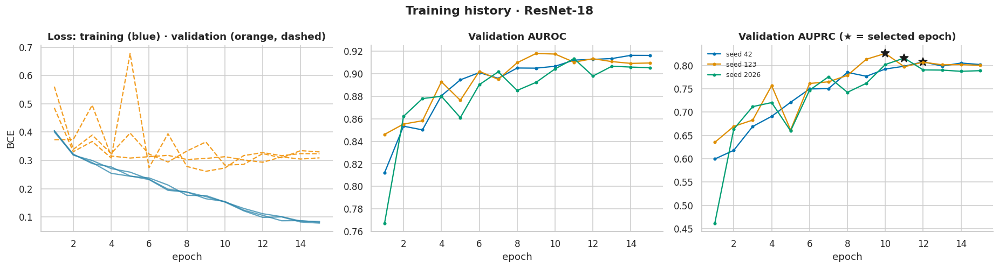

In [19]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 1: ResNet-18                                            ║
# ║  Residual (skip) connections · 18 layers · basic blocks        ║
# ║  Same data, recipe and seeds as every other model              ║
# ╚══════════════════════════════════════════════════════════════════╝
runs = run_model_training('resnet18')
plot_history('resnet18')


### 6.1b · ResNet-18: train / validation / test results

  RESNET-18 · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.223 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.990 ± 0.003   
           seed-ensemble           2821        507          0.994   
Validation mean ± SD over 3 seeds   404         72  0.915 ± 0.003   
           seed-ensemble            404         72          0.916   
Test       mean ± SD over 3 seeds   771        122  0.895 ± 0.008   
           seed-ensemble            771        122          0.900   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.971 ± 0.009  0.952 ± 0.010   
           seed-ensemble                   0.981          0.972   
Validation mean ± SD over 3 seeds  0.816 ± 0.009  0.899 ± 0.007   
           seed-ensemble                   0.833          0.911   
Test       mean ± SD over 3 seeds  0.753 ± 0.017  0.878 ± 0.002   
           seed-ensemble                   0.772          0.896   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.951 ± 0.011  0.950 ± 0.015   
           seed-ensemble                   0.963          0.949   
Validation mean ± SD over 3 seeds  0.871 ± 0.005  0.829 ± 0.016   
           seed-ensemble                   0.881          0.833   
Test       mean ± SD over 3 seeds  0.818 ± 0.011  0.730 ± 0.025   
           seed-ensemble                   0.829          0.730   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.953 ± 0.009  0.816 ± 0.030   
           seed-ensemble                   0.977          0.901   
Validation mean ± SD over 3 seeds  0.914 ± 0.011  0.676 ± 0.024   
           seed-ensemble                   0.928          0.714   
Test       mean ± SD over 3 seeds  0.906 ± 0.003  0.593 ± 0.004   
           seed-ensemble                   0.928          0.654   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.989 ± 0.003  0.878 ± 0.023   
           seed-ensemble                   0.989          0.924   
Validation mean ± SD over 3 seeds  0.961 ± 0.003  0.744 ± 0.010   
           seed-ensemble                   0.963          0.769   
Test       mean ± SD over 3 seeds  0.947 ± 0.004  0.654 ± 0.011   
           seed-ensemble                   0.948          0.690   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.852 ± 0.028  0.024 ± 0.002  0.087 ± 0.009  
           seed-ensemble                   0.907          0.020          0.076  
Validation mean ± SD over 3 seeds  0.688 ± 0.012  0.067 ± 0.001  0.284 ± 0.010  
           seed-ensemble                   0.718          0.061          0.252  
Test       mean ± SD over 3 seeds  0.586 ± 0.014  0.077 ± 0.005  0.309 ± 0.027  
           seed-ensemble                   0.629          0.070          0.266

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.088,0.994,0.982,0.963,0.964,0.966,0.962,0.849,0.992,0.904,0.884,0.021,0.077,490,87,17,2227
1,Train,123,0.129,0.990,0.967,0.945,0.945,0.945,0.945,0.790,0.987,0.861,0.832,0.026,0.090,479,127,28,2187
2,Train,2026,0.183,0.987,0.965,0.949,0.945,0.939,0.951,0.808,0.986,0.869,0.841,0.025,0.094,476,113,31,2201
3,Validation,42,0.088,0.913,0.808,0.896,0.866,0.819,0.913,0.670,0.959,0.737,0.679,0.068,0.293,59,29,13,303
4,Validation,123,0.129,0.918,0.826,0.894,0.875,0.847,0.904,0.656,0.965,0.739,0.683,0.067,0.273,61,32,11,300
5,Validation,2026,0.183,0.913,0.816,0.906,0.872,0.819,0.925,0.702,0.959,0.756,0.702,0.065,0.286,59,25,13,307
6,Test,42,0.088,0.889,0.736,0.875,0.806,0.705,0.908,0.589,0.942,0.642,0.571,0.081,0.337,86,60,36,589
7,Test,123,0.129,0.904,0.770,0.879,0.829,0.754,0.903,0.594,0.951,0.664,0.598,0.071,0.282,92,63,30,586
8,Test,2026,0.183,0.893,0.752,0.879,0.819,0.730,0.908,0.597,0.947,0.657,0.589,0.078,0.309,89,60,33,589


Train − validation AUROC gap: +0.076 (large positive = overfitting) | best epoch(s): [12, 10, 11] | train time per run: 1.5 min


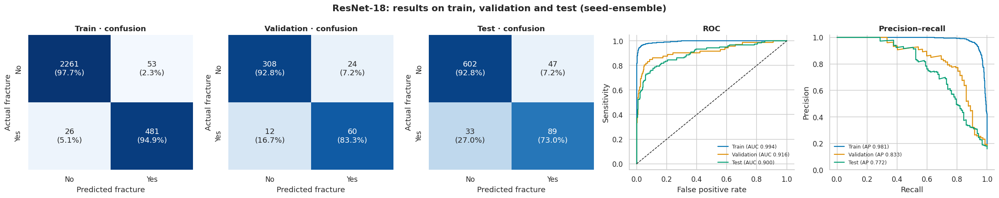

In [20]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 1: ResNet-18 — results                                  ║
# ║  Train · Validation · Test (threshold chosen on validation only)║
# ╚══════════════════════════════════════════════════════════════════╝
_ = report_model('resnet18')


## Model 2: DenseNet-121
**Dense connectivity · every layer sees all earlier features · feature reuse.** Each layer receives the concatenated feature maps of all preceding layers, giving strong feature reuse with few parameters; it is popular in radiograph studies.

Section 6.2a trains the model (epoch-by-epoch log, learning curves); 6.2b shows its **train, validation and test** results.

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 149MB/s]


  DenseNet-121 | seed 42 | 6.95M parameters | ImageNet weights: True


epoch 01/15 | lr 3.0e-04 | train loss 0.3621 acc 0.859 | val loss 0.3740 AUROC 0.7951 AUPRC 0.5447 sens@.5 0.222 spec@.5 0.979 | 17.1s | mem 2.1 GB  <- best
epoch 02/15 | lr 3.0e-04 | train loss 0.3107 acc 0.881 | val loss 0.3973 AUROC 0.8602 AUPRC 0.6046 sens@.5 0.653 spec@.5 0.877 | 16.5s | mem 2.1 GB  <- best
epoch 03/15 | lr 2.9e-04 | train loss 0.2782 acc 0.893 | val loss 0.7067 AUROC 0.8593 AUPRC 0.6356 sens@.5 0.819 spec@.5 0.750 | 16.5s | mem 2.1 GB  <- best
epoch 04/15 | lr 2.7e-04 | train loss 0.2510 acc 0.912 | val loss 0.2935 AUROC 0.8997 AUPRC 0.7424 sens@.5 0.597 spec@.5 0.964 | 16.4s | mem 2.1 GB  <- best
epoch 05/15 | lr 2.5e-04 | train loss 0.2371 acc 0.909 | val loss 0.2712 AUROC 0.9119 AUPRC 0.7785 sens@.5 0.597 spec@.5 0.976 | 16.5s | mem 2.1 GB  <- best
epoch 06/15 | lr 2.3e-04 | train loss 0.2163 acc 0.920 | val loss 0.2698 AUROC 0.9141 AUPRC 0.8042 sens@.5 0.569 spec@.5 0.976 | 16.4s | mem 2.1 GB  <- best
epoch 07/15 | lr 2.0e-04 | train loss 0.1860 acc 0.931 | v

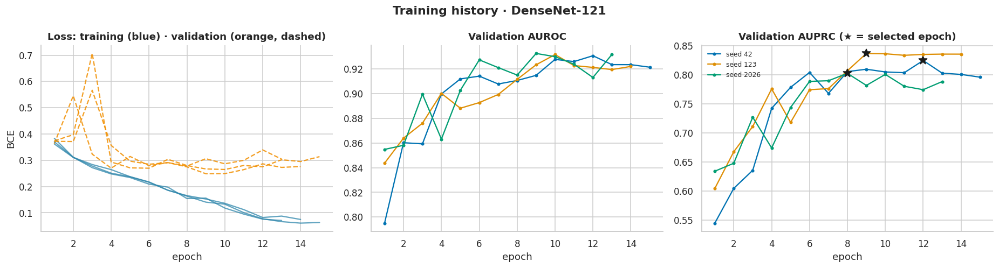

In [21]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 2: DenseNet-121                                         ║
# ║  Dense connectivity · every layer sees all earlier features · feature reuse║
# ║  Same data, recipe and seeds as every other model              ║
# ╚══════════════════════════════════════════════════════════════════╝
runs = run_model_training('densenet121')
plot_history('densenet121')


### 6.2b · DenseNet-121: train / validation / test results

  DENSENET-121 · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.160 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.990 ± 0.006   
           seed-ensemble           2821        507          0.994   
Validation mean ± SD over 3 seeds   404         72  0.923 ± 0.008   
           seed-ensemble            404         72          0.932   
Test       mean ± SD over 3 seeds   771        122  0.897 ± 0.005   
           seed-ensemble            771        122          0.903   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.971 ± 0.015  0.971 ± 0.009   
           seed-ensemble                   0.983          0.975   
Validation mean ± SD over 3 seeds  0.821 ± 0.017  0.917 ± 0.007   
           seed-ensemble                   0.848          0.926   
Test       mean ± SD over 3 seeds  0.765 ± 0.012  0.904 ± 0.001   
           seed-ensemble                   0.785          0.894   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.947 ± 0.021  0.909 ± 0.039   
           seed-ensemble                   0.965          0.949   
Validation mean ± SD over 3 seeds  0.862 ± 0.023  0.778 ± 0.050   
           seed-ensemble                   0.890          0.833   
Test       mean ± SD over 3 seeds  0.813 ± 0.004  0.680 ± 0.008   
           seed-ensemble                   0.820          0.713   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.985 ± 0.003  0.930 ± 0.017   
           seed-ensemble                   0.981          0.914   
Validation mean ± SD over 3 seeds  0.947 ± 0.008  0.761 ± 0.022   
           seed-ensemble                   0.946          0.769   
Test       mean ± SD over 3 seeds  0.947 ± 0.001  0.705 ± 0.004   
           seed-ensemble                   0.928          0.649   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.980 ± 0.008  0.919 ± 0.026   
           seed-ensemble                   0.989          0.931   
Validation mean ± SD over 3 seeds  0.952 ± 0.010  0.768 ± 0.025   
           seed-ensemble                   0.963          0.800   
Test       mean ± SD over 3 seeds  0.940 ± 0.001  0.693 ± 0.006   
           seed-ensemble                   0.945          0.680   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.902 ± 0.032  0.026 ± 0.012  0.094 ± 0.038  
           seed-ensemble                   0.916          0.021          0.079  
Validation mean ± SD over 3 seeds  0.718 ± 0.029  0.067 ± 0.009  0.267 ± 0.016  
           seed-ensemble                   0.755          0.058          0.218  
Test       mean ± SD over 3 seeds  0.636 ± 0.006  0.074 ± 0.001  0.294 ± 0.011  
           seed-ensemble                   0.617          0.066          0.254

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.127,0.996,0.988,0.981,0.971,0.955,0.987,0.942,0.990,0.948,0.937,0.015,0.056,484,30,23,2284
1,Train,123,0.350,0.988,0.965,0.970,0.938,0.890,0.987,0.938,0.976,0.913,0.895,0.025,0.092,451,30,56,2284
2,Train,2026,0.133,0.986,0.961,0.963,0.932,0.884,0.981,0.911,0.975,0.897,0.875,0.039,0.133,448,44,59,2270
3,Validation,42,0.127,0.931,0.825,0.921,0.887,0.833,0.940,0.750,0.963,0.789,0.742,0.058,0.275,60,20,12,312
4,Validation,123,0.350,0.923,0.837,0.921,0.859,0.764,0.955,0.786,0.949,0.775,0.727,0.065,0.249,55,15,17,317
5,Validation,2026,0.133,0.915,0.803,0.908,0.841,0.736,0.946,0.746,0.943,0.741,0.686,0.077,0.278,53,18,19,314
6,Test,42,0.127,0.902,0.779,0.905,0.817,0.689,0.946,0.706,0.942,0.697,0.641,0.072,0.306,84,35,38,614
7,Test,123,0.350,0.894,0.756,0.905,0.814,0.680,0.948,0.709,0.940,0.695,0.639,0.075,0.294,83,34,39,615
8,Test,2026,0.133,0.895,0.760,0.903,0.809,0.672,0.946,0.701,0.939,0.686,0.629,0.075,0.284,82,35,40,614


Train − validation AUROC gap: +0.067 (large positive = overfitting) | best epoch(s): [12, 9, 8] | train time per run: 3.9 min


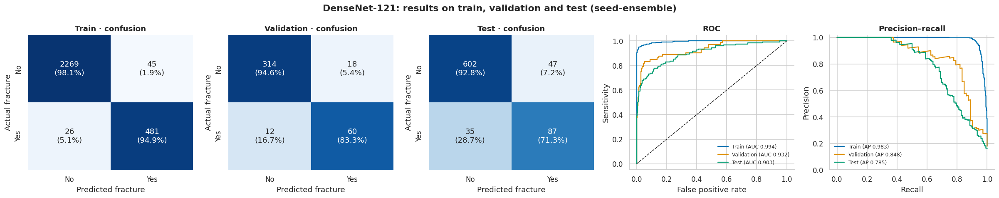

In [22]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 2: DenseNet-121 — results                               ║
# ║  Train · Validation · Test (threshold chosen on validation only)║
# ╚══════════════════════════════════════════════════════════════════╝
_ = report_model('densenet121')


## Model 3: EfficientNet-B0
**Compound scaling · MBConv blocks · squeeze-and-excitation.** Balances depth, width and resolution; inverted-residual (MBConv) blocks with channel attention give high accuracy per parameter.

Section 6.3a trains the model (epoch-by-epoch log, learning curves); 6.3b shows its **train, validation and test** results.

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s] 



  EfficientNet-B0 | seed 42 | 4.01M parameters | ImageNet weights: True
epoch 01/15 | lr 3.0e-04 | train loss 0.3782 acc 0.847 | val loss 0.3613 AUROC 0.8340 AUPRC 0.6545 sens@.5 0.417 spec@.5 0.976 | 14.3s | mem 1.4 GB  <- best
epoch 02/15 | lr 3.0e-04 | train loss 0.2925 acc 0.888 | val loss 0.3265 AUROC 0.8845 AUPRC 0.6629 sens@.5 0.681 spec@.5 0.873 | 9.5s | mem 1.4 GB  <- best
epoch 03/15 | lr 2.9e-04 | train loss 0.2684 acc 0.891 | val loss 0.2906 AUROC 0.8973 AUPRC 0.7450 sens@.5 0.667 spec@.5 0.919 | 9.7s | mem 1.4 GB  <- best
epoch 04/15 | lr 2.7e-04 | train loss 0.2278 acc 0.915 | val loss 0.3269 AUROC 0.8951 AUPRC 0.7081 sens@.5 0.653 spec@.5 0.931 | 9.6s | mem 1.4 GB
epoch 05/15 | lr 2.5e-04 | train loss 0.1901 acc 0.928 | val loss 0.2897 AUROC 0.9103 AUPRC 0.7954 sens@.5 0.556 spec@.5 0.976 | 9.4s | mem 1.4 GB  <- best
epoch 06/15 | lr 2.3e-04 | train loss 0.1526 acc 0.945 | val loss 0.3563 AUROC 0.8796 AUPRC 0.7472 sens@.5 0.597 spec@.5 0.964 | 9.5s | mem 1.4 GB
epoch 07

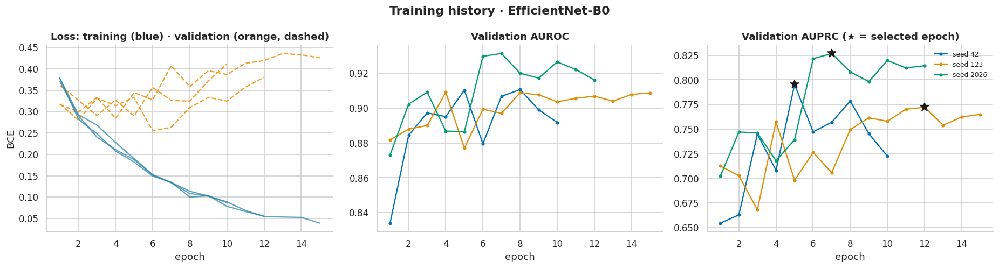

In [23]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 3: EfficientNet-B0                                      ║
# ║  Compound scaling · MBConv blocks · squeeze-and-excitation     ║
# ║  Same data, recipe and seeds as every other model              ║
# ╚══════════════════════════════════════════════════════════════════╝
runs = run_model_training('efficientnet_b0')
plot_history('efficientnet_b0')


### 6.3b · EfficientNet-B0: train / validation / test results

  EFFICIENTNET-B0 · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.138 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.992 ± 0.007   
           seed-ensemble           2821        507          0.998   
Validation mean ± SD over 3 seeds   404         72  0.916 ± 0.013   
           seed-ensemble            404         72          0.932   
Test       mean ± SD over 3 seeds   771        122  0.871 ± 0.013   
           seed-ensemble            771        122          0.892   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.974 ± 0.023  0.959 ± 0.020   
           seed-ensemble                   0.991          0.966   
Validation mean ± SD over 3 seeds  0.798 ± 0.027  0.894 ± 0.011   
           seed-ensemble                   0.824          0.896   
Test       mean ± SD over 3 seeds  0.710 ± 0.011  0.872 ± 0.013   
           seed-ensemble                   0.738          0.866   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.959 ± 0.024  0.959 ± 0.031   
           seed-ensemble                   0.972          0.982   
Validation mean ± SD over 3 seeds  0.861 ± 0.008  0.810 ± 0.021   
           seed-ensemble                   0.882          0.861   
Test       mean ± SD over 3 seeds  0.791 ± 0.021  0.672 ± 0.036   
           seed-ensemble                   0.814          0.738   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.959 ± 0.018  0.838 ± 0.065   
           seed-ensemble                   0.962          0.851   
Validation mean ± SD over 3 seeds  0.912 ± 0.017  0.667 ± 0.038   
           seed-ensemble                   0.904          0.660   
Test       mean ± SD over 3 seeds  0.909 ± 0.011  0.582 ± 0.038   
           seed-ensemble                   0.891          0.559   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.991 ± 0.007  0.894 ± 0.050   
           seed-ensemble                   0.996          0.912   
Validation mean ± SD over 3 seeds  0.957 ± 0.004  0.731 ± 0.019   
           seed-ensemble                   0.968          0.747   
Test       mean ± SD over 3 seeds  0.937 ± 0.007  0.624 ± 0.035   
           seed-ensemble                   0.948          0.636   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.872 ± 0.061  0.022 ± 0.015  0.079 ± 0.048  
           seed-ensemble                   0.895          0.016          0.063  
Validation mean ± SD over 3 seeds  0.671 ± 0.023  0.076 ± 0.006  0.324 ± 0.083  
           seed-ensemble                   0.693          0.065          0.239  
Test       mean ± SD over 3 seeds  0.549 ± 0.042  0.086 ± 0.003  0.392 ± 0.080  
           seed-ensemble                   0.564          0.076          0.298

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.134,0.983,0.948,0.939,0.934,0.927,0.941,0.776,0.983,0.845,0.812,0.038,0.130,470,136,37,2178
1,Train,123,0.105,0.998,0.994,0.979,0.983,0.988,0.978,0.906,0.997,0.945,0.934,0.009,0.033,501,52,6,2262
2,Train,2026,0.162,0.994,0.979,0.959,0.960,0.963,0.958,0.833,0.991,0.893,0.871,0.021,0.074,488,98,19,2216
3,Validation,42,0.134,0.910,0.795,0.891,0.852,0.792,0.913,0.663,0.953,0.722,0.658,0.075,0.290,57,29,15,303
4,Validation,123,0.105,0.907,0.772,0.906,0.867,0.806,0.928,0.707,0.957,0.753,0.698,0.082,0.419,58,24,14,308
5,Validation,2026,0.162,0.931,0.827,0.884,0.864,0.833,0.895,0.632,0.961,0.719,0.657,0.070,0.263,60,35,12,297
6,Test,42,0.134,0.874,0.700,0.859,0.766,0.631,0.901,0.546,0.929,0.586,0.503,0.083,0.329,77,64,45,585
7,Test,123,0.105,0.856,0.708,0.885,0.805,0.689,0.921,0.622,0.940,0.654,0.586,0.089,0.482,84,51,38,598
8,Test,2026,0.162,0.882,0.721,0.872,0.801,0.697,0.904,0.578,0.941,0.632,0.559,0.086,0.364,85,62,37,587


Train − validation AUROC gap: +0.075 (large positive = overfitting) | best epoch(s): [5, 12, 7] | train time per run: 2.0 min


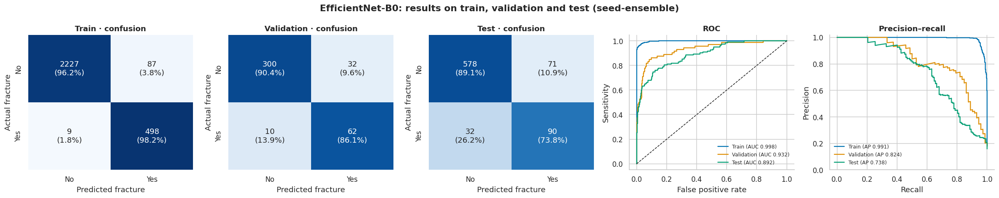

In [24]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 3: EfficientNet-B0 — results                            ║
# ║  Train · Validation · Test (threshold chosen on validation only)║
# ╚══════════════════════════════════════════════════════════════════╝
_ = report_model('efficientnet_b0')


## Model 4: MobileNetV3-Large
**Inverted residuals · SE attention · hard-swish · NAS-designed.** A lightweight network built for fast inference; it shows how much accuracy a small, deployable model can retain.

Section 6.4a trains the model (epoch-by-epoch log, learning curves); 6.4b shows its **train, validation and test** results.

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 148MB/s] 


  MobileNetV3-Large | seed 42 | 4.20M parameters | ImageNet weights: True


epoch 01/15 | lr 3.0e-04 | train loss 0.3706 acc 0.854 | val loss 0.4189 AUROC 0.8146 AUPRC 0.6168 sens@.5 0.306 spec@.5 0.997 | 7.9s | mem 1.0 GB  <- best
epoch 02/15 | lr 3.0e-04 | train loss 0.2887 acc 0.892 | val loss 0.3049 AUROC 0.8975 AUPRC 0.6676 sens@.5 0.500 spec@.5 0.958 | 6.7s | mem 1.0 GB  <- best
epoch 03/15 | lr 2.9e-04 | train loss 0.2493 acc 0.903 | val loss 0.2997 AUROC 0.8945 AUPRC 0.6945 sens@.5 0.486 spec@.5 0.958 | 6.5s | mem 1.0 GB  <- best
epoch 04/15 | lr 2.7e-04 | train loss 0.2044 acc 0.922 | val loss 0.4233 AUROC 0.9014 AUPRC 0.6930 sens@.5 0.736 spec@.5 0.880 | 6.4s | mem 1.0 GB
epoch 05/15 | lr 2.5e-04 | train loss 0.1732 acc 0.933 | val loss 0.3410 AUROC 0.9029 AUPRC 0.7470 sens@.5 0.667 spec@.5 0.940 | 6.4s | mem 1.0 GB  <- best
epoch 06/15 | lr 2.3e-04 | train loss 0.1535 acc 0.946 | val loss 0.3754 AUROC 0.8863 AUPRC 0.7080 sens@.5 0.514 spec@.5 0.970 | 6.4s | mem 1.0 GB
epoch 07/15 | lr 2.0e-04 | train loss 0.1197 acc 0.957 | val loss 0.3705 AUROC 0.8

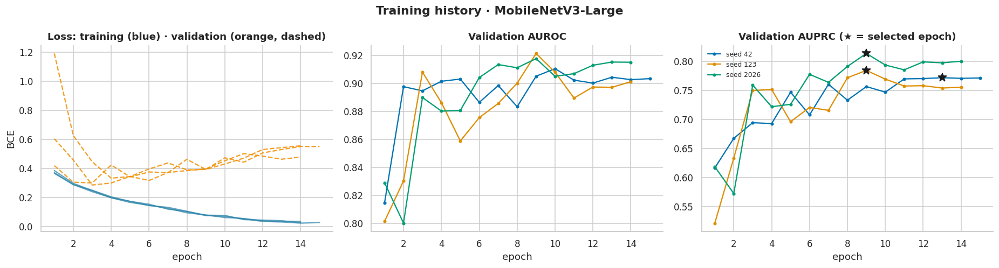

In [25]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 4: MobileNetV3-Large                                    ║
# ║  Inverted residuals · SE attention · hard-swish · NAS-designed ║
# ║  Same data, recipe and seeds as every other model              ║
# ╚══════════════════════════════════════════════════════════════════╝
runs = run_model_training('mobilenet_v3_large')
plot_history('mobilenet_v3_large')


### 6.4b · MobileNetV3-Large: train / validation / test results

  MOBILENETV3-LARGE · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.244 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.997 ± 0.002   
           seed-ensemble           2821        507          0.999   
Validation mean ± SD over 3 seeds   404         72  0.914 ± 0.009   
           seed-ensemble            404         72          0.930   
Test       mean ± SD over 3 seeds   771        122  0.884 ± 0.009   
           seed-ensemble            771        122          0.903   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.989 ± 0.007  0.943 ± 0.037   
           seed-ensemble                   0.997          0.990   
Validation mean ± SD over 3 seeds  0.790 ± 0.021  0.847 ± 0.032   
           seed-ensemble                   0.818          0.903   
Test       mean ± SD over 3 seeds  0.744 ± 0.007  0.847 ± 0.037   
           seed-ensemble                   0.769          0.901   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.961 ± 0.022  0.989 ± 0.003   
           seed-ensemble                   0.985          0.978   
Validation mean ± SD over 3 seeds  0.853 ± 0.008  0.861 ± 0.061   
           seed-ensemble                   0.865          0.806   
Test       mean ± SD over 3 seeds  0.808 ± 0.004  0.751 ± 0.045   
           seed-ensemble                   0.815          0.689   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.933 ± 0.045  0.777 ± 0.131   
           seed-ensemble                   0.993          0.967   
Validation mean ± SD over 3 seeds  0.844 ± 0.052  0.555 ± 0.072   
           seed-ensemble                   0.925          0.699   
Test       mean ± SD over 3 seeds  0.864 ± 0.052  0.523 ± 0.090   
           seed-ensemble                   0.941          0.689   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.998 ± 0.001  0.866 ± 0.080   
           seed-ensemble                   0.995          0.973   
Validation mean ± SD over 3 seeds  0.966 ± 0.012  0.670 ± 0.033   
           seed-ensemble                   0.956          0.748   
Test       mean ± SD over 3 seeds  0.949 ± 0.006  0.612 ± 0.045   
           seed-ensemble                   0.941          0.689   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.844 ± 0.092  0.014 ± 0.007  0.055 ± 0.027  
           seed-ensemble                   0.967          0.009          0.036  
Validation mean ± SD over 3 seeds  0.605 ± 0.032  0.081 ± 0.003  0.440 ± 0.078  
           seed-ensemble                   0.692          0.067          0.312  
Test       mean ± SD over 3 seeds  0.538 ± 0.051  0.081 ± 0.002  0.487 ± 0.036  
           seed-ensemble                   0.630          0.071          0.354

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.041,0.999,0.998,0.984,0.986,0.990,0.983,0.926,0.998,0.957,0.948,0.006,0.025,502,40,5,2274
1,Train,123,0.010,0.996,0.986,0.930,0.952,0.986,0.917,0.724,0.997,0.835,0.807,0.021,0.075,500,191,7,2123
2,Train,2026,0.008,0.995,0.984,0.915,0.945,0.992,0.898,0.680,0.998,0.807,0.777,0.017,0.064,503,237,4,2077
3,Validation,42,0.041,0.904,0.772,0.881,0.846,0.792,0.901,0.633,0.952,0.704,0.637,0.083,0.530,57,33,15,299
4,Validation,123,0.010,0.921,0.785,0.844,0.862,0.889,0.834,0.538,0.972,0.670,0.607,0.083,0.393,64,55,8,277
5,Validation,2026,0.008,0.918,0.814,0.817,0.850,0.903,0.798,0.492,0.974,0.637,0.572,0.078,0.396,65,67,7,265
6,Test,42,0.041,0.890,0.752,0.886,0.812,0.705,0.920,0.623,0.943,0.662,0.595,0.079,0.514,86,52,36,597
7,Test,123,0.010,0.888,0.742,0.840,0.805,0.754,0.857,0.497,0.949,0.599,0.522,0.081,0.447,92,93,30,556
8,Test,2026,0.008,0.873,0.739,0.813,0.806,0.795,0.817,0.449,0.955,0.574,0.497,0.084,0.501,97,119,25,530


Train − validation AUROC gap: +0.082 (large positive = overfitting) | best epoch(s): [13, 9, 9] | train time per run: 1.6 min


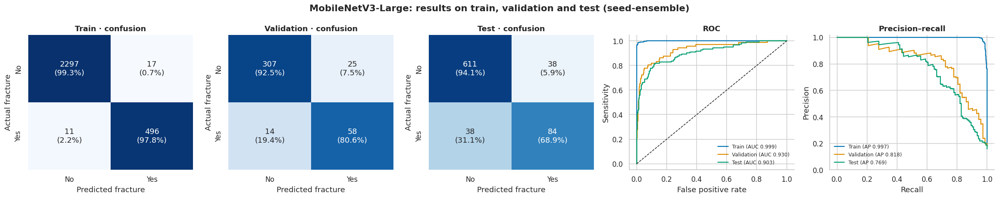

In [26]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  Model 4: MobileNetV3-Large — results                          ║
# ║  Train · Validation · Test (threshold chosen on validation only)║
# ╚══════════════════════════════════════════════════════════════════╝
_ = report_model('mobilenet_v3_large')


# Section 7: Robustness Analysis

**Four independent questions, each answered on data the models have never trained on.**

| Check | Question | Protocol |
|---|---|---|
| 7.1–7.4 Image corruptions | Does performance survive realistic image degradation? | 8 corruption types × 4 severities applied to the **test** images; each model's threshold stays **locked** at its clean-validation value |
| 7.5 Seed stability | Is the result repeatable, or luck of one initialisation? | spread over training seeds |
| 7.6 External dataset | Does it transfer to a different hospital / source? | HBFMID originals, sensitivity only (10 healthy images) |

Corruptions are applied to the already-letterboxed 8-bit test images with fixed random seeds, so every model sees *exactly* the same corrupted pixels. Rotation up to ±10° is inside the training augmentation range; larger angles, strong blur, heavy JPEG compression and occlusion are outside it.

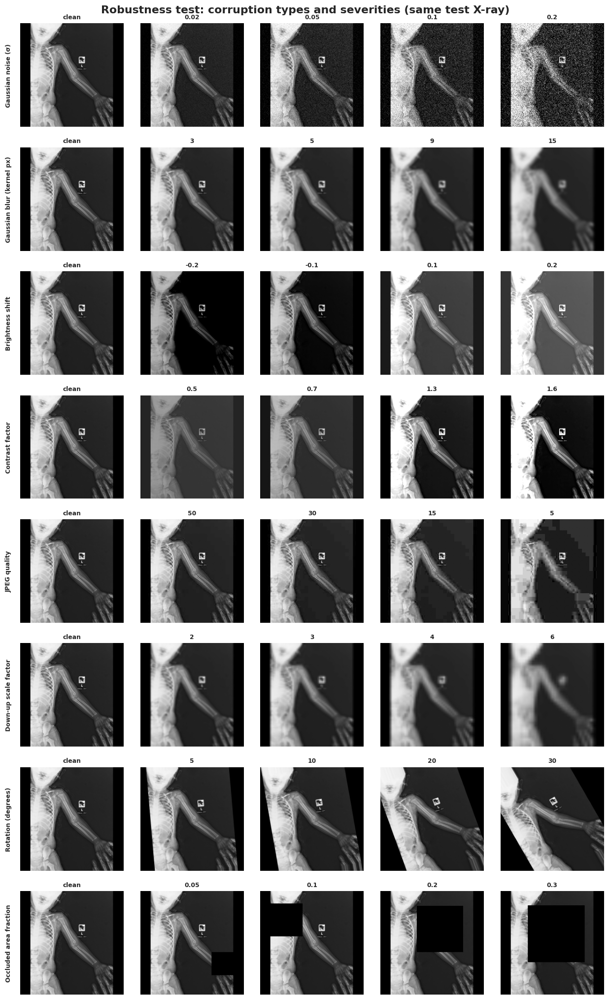

In [27]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  7.1  Corruption functions and visual examples                 ║
# ║  8 corruption types · fixed seeds · identical pixels for every model║
# ╚══════════════════════════════════════════════════════════════════╝

import io
def _gauss_kernel(k):
    sigma = max(0.3 * ((k - 1) * 0.5 - 1) + 0.8, 0.5); ax = torch.arange(k).float() - (k - 1) / 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2)); return g / g.sum()

def corrupt(u8, kind, level, seed=0):
    # u8: uint8 [N,S,S] (CPU) -> corrupted uint8 [N,S,S]; deterministic for a given (kind, level, seed)
    x = u8.float().unsqueeze(1) / 255.; g = torch.Generator().manual_seed(1000 + seed); N, _, S, _ = x.shape
    if kind == 'gaussian_noise': x = x + level * torch.randn(x.shape, generator=g)
    elif kind == 'gaussian_blur' and level > 1:
        k, pad = int(level), int(level) // 2; k1 = _gauss_kernel(k)
        x = F.conv2d(F.pad(x, (pad, pad, 0, 0), mode='reflect'), k1.view(1, 1, 1, -1)); x = F.conv2d(F.pad(x, (0, 0, pad, pad), mode='reflect'), k1.view(1, 1, -1, 1))
    elif kind == 'brightness': x = x + level
    elif kind == 'contrast': m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * level + m
    elif kind == 'jpeg':
        out = []
        for i in range(N):
            buf = io.BytesIO(); Image.fromarray(u8[i].numpy()).save(buf, format='JPEG', quality=int(level)); buf.seek(0)
            out.append(torch.from_numpy(np.asarray(Image.open(buf).convert('L')).copy()))
        return torch.stack(out)
    elif kind == 'low_resolution' and level > 1:
        small = F.interpolate(x, size=(max(S // int(level), 4),) * 2, mode='bilinear', antialias=True, align_corners=False)
        x = F.interpolate(small, size=(S, S), mode='bilinear', align_corners=False)
    elif kind == 'rotation':
        sign = (torch.arange(N) % 2 == 0).float() * 2 - 1; ang = torch.deg2rad(torch.tensor(float(level))) * sign
        c, s, z = torch.cos(ang), torch.sin(ang), torch.zeros(N)
        theta = torch.stack([torch.stack([c, -s, z], 1), torch.stack([s, c, z], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), mode='bilinear', padding_mode='border', align_corners=False)
    elif kind == 'occlusion' and level > 0:
        side = max(1, int(round(S * math.sqrt(level))))
        for i in range(N):
            ty, tx = int(torch.randint(0, S - side + 1, (1,), generator=g)), int(torch.randint(0, S - side + 1, (1,), generator=g)); x[i, :, ty:ty + side, tx:tx + side] = 0
    return (x.clamp(0, 1) * 255).round().to(torch.uint8)[:, 0]

test_u8 = torch.stack([IMGS[p] for p in parts['test'].path])
ex_i = int(np.flatnonzero(yt == 1)[0]); ex_img = test_u8[ex_i:ex_i + 1]
ncol = 1 + max(len(c['levels']) for c in CORRUPTIONS.values())
fig, axes = plt.subplots(len(CORRUPTIONS), ncol, figsize=(2.3 * ncol, 2.35 * len(CORRUPTIONS)), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for r_, (kind, cfg) in enumerate(CORRUPTIONS.items()):
    axes[r_, 0].imshow(ex_img[0], cmap='gray', vmin=0, vmax=255); axes[r_, 0].set_title('clean', fontsize=8)
    axes[r_, 0].text(-0.08, 0.5, cfg['label'], transform=axes[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=8, fontweight='bold')
    for c_, lv in enumerate(cfg['levels'], start=1):
        axes[r_, c_].imshow(corrupt(ex_img, kind, lv)[0], cmap='gray', vmin=0, vmax=255); axes[r_, c_].set_title(f'{lv}', fontsize=8)
fig.suptitle('Robustness test: corruption types and severities (same test X-ray)', fontweight='bold'); finish(fig, 'R01_corruption_examples', svg=False)

## 7.2 · Evaluate every trained model on every corrupted test set
Each of the trained checkpoints (models × seeds) is loaded once and run on all corruption conditions. For each model the decision threshold is the one fixed on the **clean validation** set, so sensitivity and specificity changes reflect the corruption, not re-tuning.

In [28]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  7.2  Corrupted-test evaluation                                ║
# ║  Locked clean-validation threshold · seeds averaged per model  ║
# ╚══════════════════════════════════════════════════════════════════╝

conds = [('clean', 0)] + [(k, lv) for k, c in CORRUPTIONS.items() for lv in c['levels']]
CORR_TEST = {c: (test_u8 if c[0] == 'clean' else corrupt(test_u8, *c)) for c in tqdm(conds, desc='Building corrupted test sets')}
ROB_P = {n: {c: [] for c in conds} for n in ARCHS}
for name in ARCHS:
    for r in tqdm(MODEL_RUNS[name], desc=f'{nice(name)} (seeds)', leave=False):
        if not Path(r['ckpt']).exists(): raise FileNotFoundError(f'{r["ckpt"]} missing: re-run Section 6 for {name}')
        m_, _ = build_model(name, pretrained=False); m_.load_state_dict(torch.load(r['ckpt'], map_location=DEVICE))
        for c in conds: ROB_P[name][c].append(forward_probs(m_, CORR_TEST[c]))
        del m_
    chk = np.abs(np.mean(ROB_P[name][('clean', 0)], 0) - np.mean([r['p_test'] for r in MODEL_RUNS[name]], 0)).max()
    assert chk < 1e-2, f'clean robustness predictions disagree with stored test predictions for {name} ({chk:.4f})'

rows = []
for name in ARCHS:
    thr_lock = RESULTS[name]['thr']
    for kind, cfg in CORRUPTIONS.items():
        for lv in [cfg['clean']] + cfg['levels']:
            c = ('clean', 0) if lv == cfg['clean'] else (kind, lv); P_ = ROB_P[name][c]; pe = np.mean(P_, 0); mt = full_metrics(yt, pe, thr_lock)
            aur = [safe_auc(yt, p) for p in P_]; apr = [safe_ap(yt, p) for p in P_]
            rows.append(dict(model=name, kind=kind, level=lv, is_clean=(lv == cfg['clean']), auroc=float(np.mean(aur)), auroc_sd=float(np.std(aur, ddof=1)) if len(aur) > 1 else 0.0,
                             auprc=float(np.mean(apr)), auprc_sd=float(np.std(apr, ddof=1)) if len(apr) > 1 else 0.0,
                             sensitivity=mt['sensitivity'], specificity=mt['specificity'], accuracy=mt['accuracy'], f1=mt['f1'], mean_prob=float(pe.mean())))
rob = pd.DataFrame(rows); rob.round(4).to_csv(OUT / 'tables' / 'robustness_all_conditions.csv', index=False)
BEST = pd.DataFrame([dict(model=n, v=np.mean([safe_ap(yv, r['p_val']) for r in MODEL_RUNS[n]])) for n in ARCHS]).set_index('model').v.idxmax()
print(f'Best model by mean validation AUPRC (selection rule, used again in Sections 8-9): {nice(BEST)}')
display(rob[rob.model == BEST].round(3).head(12))

Building corrupted test sets:   0%|          | 0/33 [00:00<?, ?it/s]

ResNet-18 (seeds):   0%|          | 0/3 [00:00<?, ?it/s]

DenseNet-121 (seeds):   0%|          | 0/3 [00:00<?, ?it/s]

EfficientNet-B0 (seeds):   0%|          | 0/3 [00:00<?, ?it/s]

MobileNetV3-Large (seeds):   0%|          | 0/3 [00:00<?, ?it/s]

Best model by mean validation AUPRC (selection rule, used again in Sections 8-9): DenseNet-121


,model,kind,level,is_clean,auroc,auroc_sd,auprc,auprc_sd,sensitivity,specificity,accuracy,f1,mean_prob
40,densenet121,gaussian_noise,0.00,True,0.897,0.005,0.765,0.012,0.713,0.928,0.894,0.680,0.129
41,densenet121,gaussian_noise,0.02,False,0.822,0.018,0.618,0.026,0.951,0.291,0.396,0.332,0.454
42,densenet121,gaussian_noise,0.05,False,0.692,0.033,0.411,0.017,1.000,0.003,0.161,0.274,0.657
43,densenet121,gaussian_noise,0.10,False,0.663,0.014,0.338,0.036,1.000,0.000,0.158,0.273,0.468
44,densenet121,gaussian_noise,0.20,False,0.614,0.037,0.286,0.051,1.000,0.000,0.158,0.273,0.465
45,densenet121,gaussian_blur,1.00,True,0.897,0.005,0.765,0.012,0.713,0.928,0.894,0.680,0.129
46,densenet121,gaussian_blur,3.00,False,0.891,0.007,0.749,0.018,0.713,0.900,0.870,0.635,0.142
47,densenet121,gaussian_blur,5.00,False,0.871,0.002,0.720,0.009,0.738,0.864,0.844,0.600,0.155
48,densenet121,gaussian_blur,9.00,False,0.813,0.010,0.631,0.017,0.713,0.812,0.796,0.526,0.168
49,densenet121,gaussian_blur,15.00,False,0.713,0.042,0.451,0.051,0.623,0.778,0.754,0.444,0.151


## 7.3 · Degradation curves and robustness summary
Lines show mean AUROC over seeds (shaded = ±1 SD). The second figure shows how sensitivity and specificity move at the locked threshold: a corruption that raises the predicted fracture probability for everything inflates sensitivity and destroys specificity, which AUROC alone can hide.

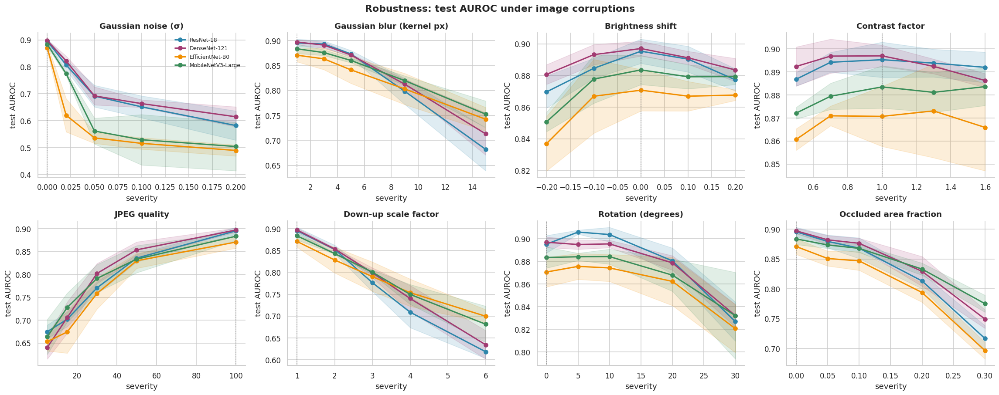

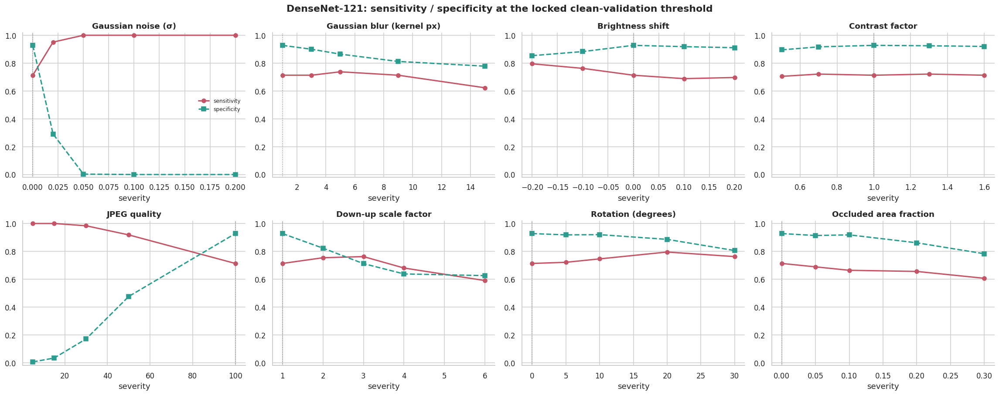

  ROBUSTNESS SUMMARY · test AUROC · drop from clean at the hardest severity (lower = more robust)


,clean AUROC,gaussian_noise,gaussian_blur,brightness,contrast,jpeg,low_resolution,rotation,occlusion,mean,mean AUROC retained %
model,,,,,,,,,,,
ResNet-18,0.895,0.314,0.213,0.026,0.008,0.220,0.277,0.068,0.179,0.163,90.050
DenseNet-121,0.897,0.283,0.184,0.016,0.011,0.257,0.263,0.065,0.148,0.153,90.796
EfficientNet-B0,0.871,0.382,0.128,0.034,0.010,0.218,0.171,0.050,0.174,0.146,89.467
MobileNetV3-Large,0.884,0.380,0.131,0.033,0.011,0.220,0.202,0.051,0.108,0.142,90.504


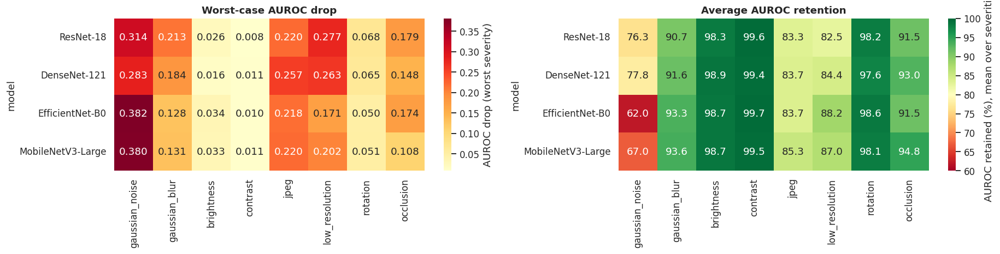

Most robust on average (mean AUROC retention): DenseNet-121 (90.8%). Read this together with the clean AUROC: a weak model can retain a low score trivially, so robustness only matters for models that perform well when clean.


In [29]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  7.3  Robustness plots and summary table                       ║
# ╚══════════════════════════════════════════════════════════════════╝

fig, axes = plt.subplots(2, 4, figsize=(21, 8.4))
for ax, (kind, cfg) in zip(axes.ravel(), CORRUPTIONS.items()):
    for name in ARCHS:
        g = rob[(rob.model == name) & (rob.kind == kind)].sort_values('level')
        ax.plot(g.level, g.auroc, marker='o', lw=2, color=MODEL_PAL[name], label=nice(name)); ax.fill_between(g.level, g.auroc - g.auroc_sd, g.auroc + g.auroc_sd, color=MODEL_PAL[name], alpha=.15)
    ax.axvline(cfg['clean'], color='gray', ls=':', lw=1); ax.set(title=cfg['label'], xlabel='severity', ylabel='test AUROC')
axes[0, 0].legend(frameon=False, fontsize=8); fig.suptitle('Robustness: test AUROC under image corruptions', fontweight='bold'); finish(fig, 'R02_robustness_auroc')

fig, axes = plt.subplots(2, 4, figsize=(21, 8.4))
for ax, (kind, cfg) in zip(axes.ravel(), CORRUPTIONS.items()):
    g = rob[(rob.model == BEST) & (rob.kind == kind)].sort_values('level')
    ax.plot(g.level, g.sensitivity, 'o-', color='#C45566', lw=2, label='sensitivity'); ax.plot(g.level, g.specificity, 's--', color='#2A9D8F', lw=2, label='specificity')
    ax.axvline(cfg['clean'], color='gray', ls=':', lw=1); ax.set(title=cfg['label'], xlabel='severity', ylim=(-.02, 1.02))
axes[0, 0].legend(frameon=False, fontsize=8); fig.suptitle(f'{nice(BEST)}: sensitivity / specificity at the locked clean-validation threshold', fontweight='bold'); finish(fig, 'R03_best_model_sens_spec_under_corruption')

summ = []
for name in ARCHS:
    cl = rob[(rob.model == name) & rob.is_clean].auroc.iloc[0]; row = dict(model=nice(name), clean_auroc=cl)
    for kind in CORRUPTIONS:
        g = rob[(rob.model == name) & (rob.kind == kind) & ~rob.is_clean]; row[f'{kind}_worst_drop'] = float(cl - g.auroc.min()); row[f'{kind}_mean_retention_pct'] = float(100 * g.auroc.mean() / cl)
    row['mean_retention_pct'] = float(np.mean([row[f'{k}_mean_retention_pct'] for k in CORRUPTIONS])); row['mean_worst_drop'] = float(np.mean([row[f'{k}_worst_drop'] for k in CORRUPTIONS])); summ.append(row)
summ = pd.DataFrame(summ).set_index('model'); summ.round(4).to_csv(OUT / 'tables' / 'robustness_summary.csv')
print('=' * 104); print('  ROBUSTNESS SUMMARY · test AUROC · drop from clean at the hardest severity (lower = more robust)'); print('=' * 104)
show = summ[[f'{k}_worst_drop' for k in CORRUPTIONS] + ['mean_worst_drop', 'mean_retention_pct']].copy(); show.columns = [c.replace('_worst_drop', '').replace('mean_retention_pct', 'mean AUROC retained %') for c in show.columns]; show.insert(0, 'clean AUROC', summ.clean_auroc)
display(show.round(3))
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4))
sns.heatmap(summ[[f'{k}_worst_drop' for k in CORRUPTIONS]].rename(columns=lambda c: c.replace('_worst_drop', '')), annot=True, fmt='.3f', cmap='YlOrRd', ax=axes[0], cbar_kws={'label': 'AUROC drop (worst severity)'})
sns.heatmap(summ[[f'{k}_mean_retention_pct' for k in CORRUPTIONS]].rename(columns=lambda c: c.replace('_mean_retention_pct', '')), annot=True, fmt='.1f', cmap='RdYlGn', vmin=60, vmax=100, ax=axes[1], cbar_kws={'label': 'AUROC retained (%), mean over severities'})
axes[0].set_title('Worst-case AUROC drop'); axes[1].set_title('Average AUROC retention'); finish(fig, 'R04_robustness_summary_heatmaps')
most = summ.mean_retention_pct.idxmax(); print(f'Most robust on average (mean AUROC retention): {most} ({summ.mean_retention_pct.max():.1f}%). Read this together with the clean AUROC: a weak model can retain a low score trivially, so robustness only matters for models that perform well when clean.')

## 7.4 · Seed stability
If a model's score depends on the random initialisation, one training run can mislead. Points are individual seeds; the black bar is mean ± SD.

auroc         auprc        sensitivity        specificity  \
                     mean    std   mean    std        mean    std        mean   
model                                                                           
resnet18            0.895  0.008  0.753  0.017       0.730  0.025       0.906   
densenet121         0.897  0.005  0.765  0.012       0.680  0.008       0.947   
efficientnet_b0     0.871  0.013  0.710  0.011       0.672  0.036       0.909   
mobilenet_v3_large  0.884  0.009  0.744  0.007       0.751  0.045       0.864   

                              f1         
                      std   mean    std  
model                                    
resnet18            0.003  0.654  0.011  
densenet121         0.001  0.693  0.006  
efficientnet_b0     0.011  0.624  0.035  
mobilenet_v3_large  0.052  0.612  0.045

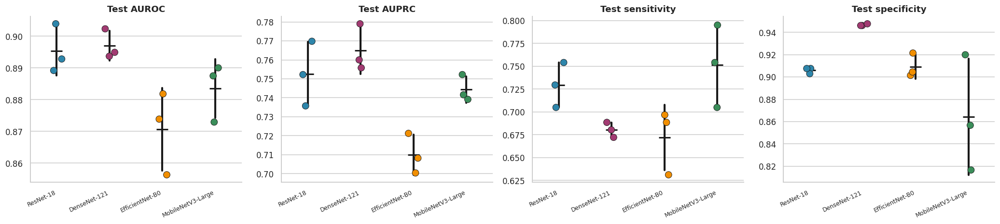

In [30]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  7.4  Seed stability                                           ║
# ╚══════════════════════════════════════════════════════════════════╝

rows = []
for name in ARCHS:
    for r in MODEL_RUNS[name]:
        m = full_metrics(yt, r['p_test'], r['thr']); rows.append(dict(model=name, seed=r['seed'], auroc=m['auroc'], auprc=m['auprc'], sensitivity=m['sensitivity'], specificity=m['specificity'], f1=m['f1']))
seed_df = pd.DataFrame(rows)
stab = seed_df.groupby('model')[['auroc', 'auprc', 'sensitivity', 'specificity', 'f1']].agg(['mean', 'std']).reindex(ARCHS); stab.round(4).to_csv(OUT / 'tables' / 'seed_stability.csv'); display(stab.round(3))
if len(SEEDS) > 1:
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
    for ax, (m, lab) in zip(axes, [('auroc', 'Test AUROC'), ('auprc', 'Test AUPRC'), ('sensitivity', 'Test sensitivity'), ('specificity', 'Test specificity')]):
        sns.stripplot(data=seed_df, x='model', y=m, order=ARCHS, hue='model', palette=MODEL_PAL, size=9, edgecolor='k', linewidth=.6, legend=False, ax=ax)
        sns.pointplot(data=seed_df, x='model', y=m, order=ARCHS, color='k', linestyle='none', errorbar='sd', markers='_', markersize=16, ax=ax)
        ax.set(title=lab, xlabel='', ylabel=''); ax.set_xticks(range(len(ARCHS))); ax.set_xticklabels([nice(x) for x in ARCHS], rotation=25, ha='right', fontsize=8)
    finish(fig, 'R05_seed_stability')
else:
    print('Only one seed was trained: seed stability cannot be assessed (set SEEDS = [42, 123, 2026]).')

## 7.5 · External dataset shift (HBFMID originals)
HBFMID was never used for training, thresholds or model choice. Images come from a different source (square 640 × 640 export, black borders, different contrast). Thresholds are the FracAtlas-validation thresholds. Because only 10 healthy images remain, report **sensitivity with its Wilson interval** and ignore specificity/AUROC here. The gallery lets you confirm by eye that the set really contains X-rays (modality was inferred from filenames).

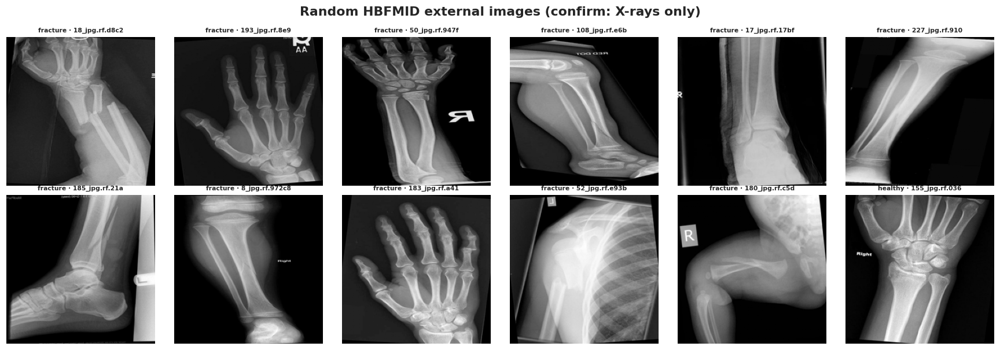

,model,n,fractured,healthy,sensitivity_main_threshold,sens_lo_main_threshold,sens_hi_main_threshold,healthy_flagged_main_threshold,sensitivity_sens90_threshold,sens_lo_sens90_threshold,sens_hi_sens90_threshold,healthy_flagged_sens90_threshold,internal_test_sensitivity
0,ResNet-18,161,151,10,0.616,0.536,0.690,4,0.927,0.874,0.959,5,0.730
1,DenseNet-121,161,151,10,0.556,0.477,0.633,1,0.834,0.767,0.885,5,0.713
2,EfficientNet-B0,161,151,10,0.940,0.891,0.968,7,0.974,0.934,0.990,7,0.738
3,MobileNetV3-Large,161,151,10,0.748,0.674,0.811,4,0.947,0.899,0.973,7,0.689


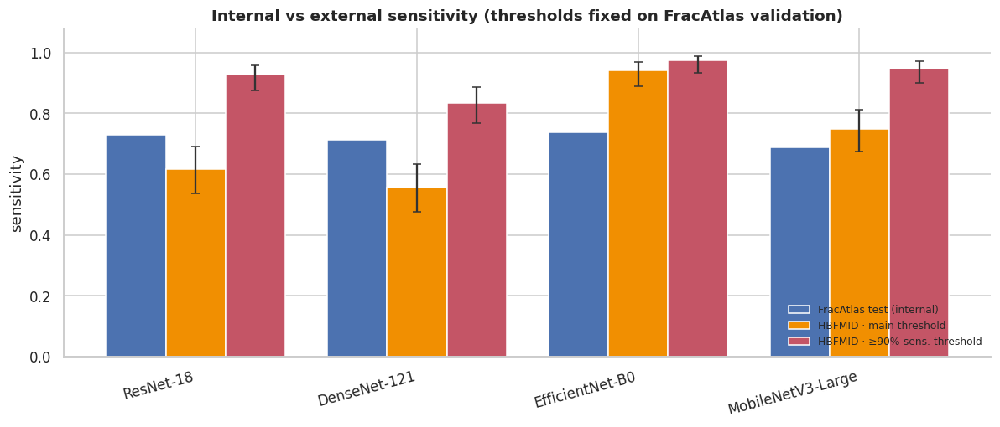

External set: 151 fractured, 10 healthy -> only sensitivity is meaningful.


In [31]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  7.5  External HBFMID evaluation                               ║
# ║  Sensitivity only · thresholds fixed on FracAtlas validation   ║
# ╚══════════════════════════════════════════════════════════════════╝

ENS_EXT_OK = len(ext) > 0 and all(len(r['p_ext']) for n in ARCHS for r in MODEL_RUNS[n])
if not ENS_EXT_OK:
    print('No external predictions available (HBFMID labels or eligible X-ray originals missing); skipped.')
else:
    if DISPLAY_GALLERIES:
        sm = ext.sample(min(12, len(ext)), random_state=SEED); fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
        for ax in axes.ravel(): ax.axis('off')
        for ax, (_, r) in zip(axes.ravel(), sm.iterrows()):
            ax.imshow(IMGS[r.path].numpy(), cmap='gray'); ax.set_title(('fracture' if r.label else 'healthy') + f' · {Path(r.path).name[:14]}', fontsize=7)
        fig.suptitle('Random HBFMID external images (confirm: X-rays only)', fontweight='bold'); finish(fig, 'R06_external_samples', svg=False)
    rows = []
    for name in ARCHS:
        pe = np.mean([r['p_ext'] for r in MODEL_RUNS[name]], 0); tv = RESULTS[name]['thr']; ts = choose_threshold(yv, ensemble_of(name, 'val'), 'sens90')
        rr = dict(model=nice(name), n=len(ye), fractured=int(ye.sum()), healthy=int((ye == 0).sum()))
        for tag, t in [('main_threshold', tv), ('sens90_threshold', ts)]:
            hit = int((pe[ye == 1] >= t).sum()); lo, hi = wilson(hit, int((ye == 1).sum()))
            rr.update({f'sensitivity_{tag}': hit / max(int((ye == 1).sum()), 1), f'sens_lo_{tag}': lo, f'sens_hi_{tag}': hi, f'healthy_flagged_{tag}': int((pe[ye == 0] >= t).sum())})
        rr['internal_test_sensitivity'] = full_metrics(yt, ensemble_of(name, 'test'), tv)['sensitivity']; rows.append(rr)
    ext_df = pd.DataFrame(rows); ext_df.round(4).to_csv(OUT / 'tables' / 'external_hbfmid.csv', index=False); display(ext_df.round(3))
    fig, ax = plt.subplots(figsize=(11, 4.8)); w = .27; xx = np.arange(len(ARCHS))
    ax.bar(xx - w, ext_df.internal_test_sensitivity, w, label='FracAtlas test (internal)', color='#4C72B0')
    for j, (tag, col, lab) in enumerate([('main_threshold', '#F18F01', 'HBFMID · main threshold'), ('sens90_threshold', '#C45566', f'HBFMID · ≥{SENS_TARGET:.0%}-sens. threshold')]):
        v = ext_df[f'sensitivity_{tag}'].values; ax.bar(xx + j * w, v, w, label=lab, color=col, yerr=errbars(v, ext_df[f'sens_lo_{tag}'].values, ext_df[f'sens_hi_{tag}'].values), capsize=3, ecolor='#333')
    ax.set_xticks(xx); ax.set_xticklabels([nice(k) for k in ARCHS], rotation=15, ha='right'); ax.set(ylabel='sensitivity', ylim=(0, 1.08), title='Internal vs external sensitivity (thresholds fixed on FracAtlas validation)'); ax.legend(frameon=False, fontsize=8, loc='lower right')
    finish(fig, 'R07_internal_vs_external_sensitivity'); print(f'External set: {int(ye.sum())} fractured, {int((ye == 0).sum())} healthy -> only sensitivity is meaningful.')

# Section 8: Evaluation & Comparison

All numbers below come from the models trained in Section 6. The **test set is read only for reporting**: best epoch, thresholds and the "best model" were fixed on validation. *Seed-ensemble* = mean of a model's seeds' probabilities; **Ensemble (all models)** averages the model ensembles. Confidence intervals resample **image families** (not images).

In [32]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  8.1  Unified comparison table                                 ║
# ╚══════════════════════════════════════════════════════════════════╝

KEYS = ARCHS + (['ensemble_all'] if len(ARCHS) > 1 else [])
PAL = {**MODEL_PAL}; ens, thr = {}, {}
for name in ARCHS: ens[name] = {k: ensemble_of(name, k) for k in ['train', 'val', 'test']}; ens[name]['ext'] = ensemble_of(name, 'ext') if ENS_EXT_OK else None
if len(ARCHS) > 1: ens['ensemble_all'] = {k: np.mean([ens[n][k] for n in ARCHS], 0) for k in ['train', 'val', 'test']}; ens['ensemble_all']['ext'] = np.mean([ens[n]['ext'] for n in ARCHS], 0) if ENS_EXT_OK else None
for k in KEYS: thr[k] = {'main': choose_threshold(yv, ens[k]['val']), 'sens90': choose_threshold(yv, ens[k]['val'], 'sens90'), 'spec90': choose_threshold(yv, ens[k]['val'], 'spec90')}

def per_model(name):
    runs = MODEL_RUNS[name]; f = lambda y, key: pd.DataFrame([full_metrics(y, r[f'p_{key}'], r['thr']) for r in runs])
    tr_, va_, te_ = f(ytr, 'train'), f(yv, 'val'), f(yt, 'test')
    return dict(tr_auroc=tr_.auroc.mean(), va_auroc=va_.auroc.mean(), te_auroc=te_.auroc.mean(), te_auprc=te_.auprc.mean(), te_acc=te_.accuracy.mean(), te_sens=te_.sensitivity.mean(), te_spec=te_.specificity.mean(),
                te_f1=te_.f1.mean(), te_mcc=te_.mcc.mean(), va_auprc=va_.auprc.mean(), tr_loss=tr_.loss.mean(), va_loss=va_.loss.mean(), te_loss=te_.loss.mean(), best_epoch=np.mean([r['best_epoch'] for r in runs]),
                epochs=np.mean([r['epochs_run'] for r in runs]), minutes=np.mean([r['train_time_s'] for r in runs]) / 60, params=runs[0]['params'] / 1e6)
PM = pd.DataFrame({n: per_model(n) for n in ARCHS}); PM.round(4).to_csv(OUT / 'tables' / 'unified_comparison.csv')
ROWS = [('Train AUROC', 'tr_auroc', 'neutral'), ('Validation AUROC', 'va_auroc', 'higher'), ('Validation AUPRC (selection metric)', 'va_auprc', 'higher'), ('Test AUROC', 'te_auroc', 'higher'), ('Test AUPRC', 'te_auprc', 'higher'),
        ('Test accuracy', 'te_acc', 'higher'), ('Test sensitivity', 'te_sens', 'higher'), ('Test specificity', 'te_spec', 'higher'), ('Test F1', 'te_f1', 'higher'), ('Test MCC', 'te_mcc', 'higher'),
        ('Train loss (BCE)', 'tr_loss', 'neutral'), ('Validation loss (BCE)', 'va_loss', 'lower'), ('Test loss (BCE)', 'te_loss', 'lower'), ('Selected epoch (mean)', 'best_epoch', 'neutral'),
        ('Epochs run (mean)', 'epochs', 'neutral'), ('Training time per run (min)', 'minutes', 'lower'), ('Parameters (M)', 'params', 'lower')]
W = 24 + 19 * len(ARCHS); print('=' * W); print(f'  UNIFIED MODEL COMPARISON · mean over {len(SEEDS)} seed(s) · per-seed validation threshold ({THRESHOLD_RULE})'); print('=' * W)
print(f'  {"Metric":<38}|' + ''.join(f'{nice(n)[:17]:>19}' for n in ARCHS)); print('-' * W)
for lab, key, d in ROWS:
    v = PM.loc[key, ARCHS].values.astype(float); b = (np.argmax(v) if d == 'higher' else np.argmin(v)) if d != 'neutral' else -1
    print(f'  {lab:<38}|' + ''.join(f'{x:>17.4f}' + (' ◄' if i == b else '  ') for i, x in enumerate(v)))
print('=' * W); print('  ◄ = best of the compared models for that row (test numbers are descriptive, selection used validation only)')
print(f'\nBest model by validation AUPRC: {nice(BEST)}')

  UNIFIED MODEL COMPARISON · mean over 3 seed(s) · per-seed validation threshold (youden)
  Metric                                |          ResNet-18       DenseNet-121    EfficientNet-B0  MobileNetV3-Large
----------------------------------------------------------------------------------------------------
  Train AUROC                           |           0.9903             0.9899             0.9917             0.9967  
  Validation AUROC                      |           0.9146             0.9230 ◄           0.9162             0.9143  
  Validation AUPRC (selection metric)   |           0.8163             0.8214 ◄           0.7981             0.7900  
  Test AUROC                            |           0.8953             0.8970 ◄           0.8707             0.8835  
  Test AUPRC                            |           0.7526             0.7649 ◄           0.7099             0.7443  
  Test accuracy                         |           0.8781             0.9045 ◄           0.8716     

## 8.2 · Test-set metrics with 95 % cluster-bootstrap confidence intervals
Table 1: mean ± SD over seeds. Table 2: seed-ensemble with intervals. Table 3: a second operating point (≥ 90 % validation sensitivity), for screening use.

Cluster bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

TABLE 1 · test set · mean ± SD over 3 seed(s)  (* = selected on validation)


,AUROC,AUPRC,Accuracy,Bal. acc.,Sensitivity,Specificity,PPV,NPV,F1,MCC,Cohen κ,Brier,ECE
ResNet-18,0.895 ± 0.008,0.753 ± 0.017,0.878 ± 0.002,0.818 ± 0.011,0.730 ± 0.025,0.906 ± 0.003,0.593 ± 0.004,0.947 ± 0.004,0.654 ± 0.011,0.586 ± 0.014,0.581 ± 0.013,0.077 ± 0.005,0.057 ± 0.008
DenseNet-121 *,0.897 ± 0.005,0.765 ± 0.012,0.904 ± 0.001,0.813 ± 0.004,0.680 ± 0.008,0.947 ± 0.001,0.705 ± 0.004,0.940 ± 0.001,0.693 ± 0.006,0.636 ± 0.006,0.636 ± 0.007,0.074 ± 0.001,0.055 ± 0.004
EfficientNet-B0,0.871 ± 0.013,0.710 ± 0.011,0.872 ± 0.013,0.791 ± 0.021,0.672 ± 0.036,0.909 ± 0.011,0.582 ± 0.038,0.937 ± 0.007,0.624 ± 0.035,0.549 ± 0.042,0.547 ± 0.042,0.086 ± 0.003,0.070 ± 0.013
MobileNetV3-Large,0.884 ± 0.009,0.744 ± 0.007,0.847 ± 0.037,0.808 ± 0.004,0.751 ± 0.045,0.864 ± 0.052,0.523 ± 0.090,0.949 ± 0.006,0.612 ± 0.045,0.538 ± 0.051,0.521 ± 0.065,0.081 ± 0.002,0.075 ± 0.004


TABLE 2 · test set · seed-ensemble · 95 % cluster-bootstrap CI (1000 resamples, 711 test families)


,AUROC,AUPRC,Sensitivity,Specificity,PPV,F1,MCC,Accuracy
model,,,,,,,,
ResNet-18,0.900 (0.862–0.934),0.772 (0.700–0.836),0.730 (0.646–0.805),0.928 (0.905–0.948),0.654 (0.578–0.732),0.690 (0.622–0.751),0.629 (0.554–0.702),0.896 (0.875–0.917)
DenseNet-121,0.903 (0.867–0.935),0.785 (0.719–0.848),0.713 (0.632–0.790),0.928 (0.907–0.947),0.649 (0.568–0.727),0.680 (0.613–0.744),0.617 (0.541–0.692),0.894 (0.873–0.916)
EfficientNet-B0,0.892 (0.857–0.925),0.738 (0.660–0.811),0.738 (0.650–0.818),0.891 (0.866–0.915),0.559 (0.485–0.640),0.636 (0.565–0.700),0.564 (0.481–0.635),0.866 (0.840–0.890)
MobileNetV3-Large,0.903 (0.868–0.937),0.769 (0.696–0.838),0.689 (0.605–0.773),0.941 (0.923–0.958),0.689 (0.607–0.770),0.689 (0.618–0.757),0.630 (0.550–0.709),0.901 (0.880–0.923)
Ensemble (all models),0.910 (0.877–0.941),0.787 (0.718–0.852),0.631 (0.540–0.722),0.971 (0.957–0.984),0.802 (0.717–0.881),0.706 (0.635–0.778),0.665 (0.589–0.747),0.917 (0.897–0.937)


TABLE 3 · alternative operating points (thresholds from validation)


,model,operating_point,threshold,sensitivity,specificity,ppv,npv,f1,mcc,tp,fp,fn,tn
0,ResNet-18,≥90% sensitivity on validation,0.031,0.844,0.740,0.379,0.962,0.523,0.446,103,169,19,480
1,ResNet-18,≥90% specificity on validation,0.117,0.787,0.880,0.552,0.956,0.649,0.582,96,78,26,571
2,DenseNet-121,≥90% sensitivity on validation,0.021,0.885,0.680,0.342,0.969,0.493,0.419,108,208,14,441
3,DenseNet-121,≥90% specificity on validation,0.111,0.738,0.894,0.566,0.948,0.641,0.570,90,69,32,580
4,EfficientNet-B0,≥90% sensitivity on validation,0.037,0.811,0.772,0.401,0.956,0.537,0.456,99,148,23,501
5,EfficientNet-B0,≥90% specificity on validation,0.138,0.738,0.891,0.559,0.948,0.636,0.564,90,71,32,578
6,MobileNetV3-Large,≥90% sensitivity on validation,0.007,0.828,0.783,0.417,0.960,0.555,0.480,101,141,21,508
7,MobileNetV3-Large,≥90% specificity on validation,0.175,0.697,0.928,0.644,0.942,0.669,0.605,85,47,37,602
8,Ensemble (all models),≥90% sensitivity on validation,0.032,0.852,0.746,0.387,0.964,0.532,0.458,104,165,18,484
9,Ensemble (all models),≥90% specificity on validation,0.181,0.754,0.931,0.672,0.953,0.710,0.654,92,45,30,604


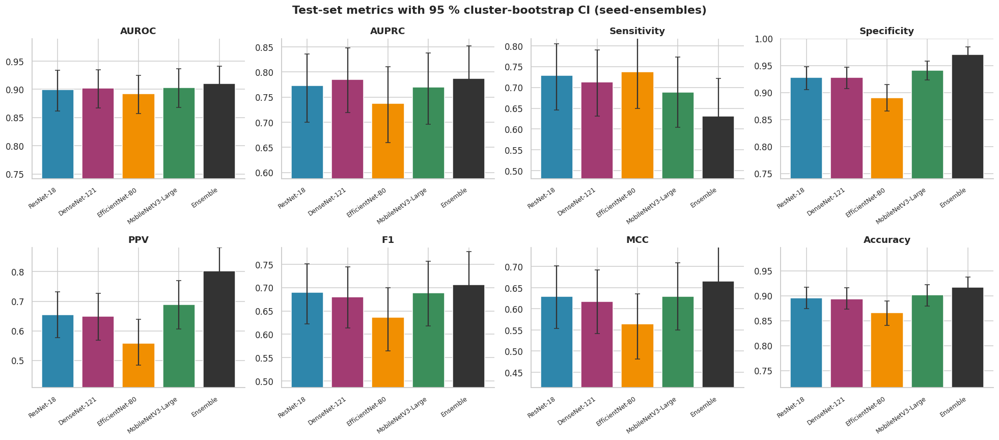

In [33]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  8.2  Tables with confidence intervals                         ║
# ╚══════════════════════════════════════════════════════════════════╝

thr_main = {k: thr[k]['main'] for k in KEYS}
boot = cluster_bootstrap(yt, {k: ens[k]['test'] for k in KEYS}, gt, thr_main, N_BOOT)
rows = []
for k in KEYS:
    full = full_metrics(yt, ens[k]['test'], thr_main[k]); r = dict(model=nice(k), threshold=thr_main[k])
    for m in BOOT_METRICS: lo, hi = ci95(boot[k][m]); r.update({m: full[m], f'{m}_lo': lo, f'{m}_hi': hi})
    r.update({m: full[m] for m in ['balanced_acc', 'npv', 'kappa', 'brier', 'ece', 'tp', 'fp', 'fn', 'tn']}); rows.append(r)
ci_df = pd.DataFrame(rows); ci_df.round(4).to_csv(OUT / 'tables' / 'table2_seed_ensemble_with_95CI.csv', index=False)
fmt = lambda r, m: f'{r[m]:.3f} ({r[m + "_lo"]:.3f}–{r[m + "_hi"]:.3f})'
tab2 = pd.DataFrame({lab: [fmt(r, m) for _, r in ci_df.iterrows()] for m, lab in [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('ppv', 'PPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('accuracy', 'Accuracy')]}, index=ci_df.model)
tab2.to_csv(OUT / 'tables' / 'table2_formatted.csv')
per_seed = pd.DataFrame([dict(model=r['model'], seed=r['seed'], **full_metrics(yt, r['p_test'], r['thr'])) for n in ARCHS for r in MODEL_RUNS[n]])
g_ = per_seed.groupby('model'); cols = [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('accuracy', 'Accuracy'), ('balanced_acc', 'Bal. acc.'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('ppv', 'PPV'), ('npv', 'NPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('kappa', 'Cohen κ'), ('brier', 'Brier'), ('ece', 'ECE')]
mn, sd = g_[[c for c, _ in cols]].mean().reindex(ARCHS), g_[[c for c, _ in cols]].std().reindex(ARCHS)
tab1 = pd.DataFrame({lab: [f'{mn.loc[m, c]:.3f} ± {sd.loc[m, c]:.3f}' if len(SEEDS) > 1 else f'{mn.loc[m, c]:.3f}' for m in ARCHS] for c, lab in cols}, index=[nice(m) + (' *' if m == BEST else '') for m in ARCHS])
tab1.to_csv(OUT / 'tables' / 'table1_mean_sd_over_seeds.csv')
print(f'TABLE 1 · test set · mean ± SD over {len(SEEDS)} seed(s)  (* = selected on validation)'); display(tab1)
print(f'TABLE 2 · test set · seed-ensemble · 95 % cluster-bootstrap CI ({N_BOOT} resamples, {len(np.unique(gt))} test families)'); display(tab2)
rows = []
for k in KEYS:
    for tag in ['sens90', 'spec90']:
        m = full_metrics(yt, ens[k]['test'], thr[k][tag]); rows.append(dict(model=nice(k), operating_point={'sens90': f'≥{SENS_TARGET:.0%} sensitivity on validation', 'spec90': f'≥{SPEC_TARGET:.0%} specificity on validation'}[tag],
            threshold=thr[k][tag], **{c: m[c] for c in ['sensitivity', 'specificity', 'ppv', 'npv', 'f1', 'mcc', 'tp', 'fp', 'fn', 'tn']}))
op_df = pd.DataFrame(rows); op_df.round(4).to_csv(OUT / 'tables' / 'table3_operating_points.csv', index=False); print('TABLE 3 · alternative operating points (thresholds from validation)'); display(op_df.round(3))

pw = []
for a_, b_ in itertools.permutations(KEYS, 2):
    for m in ['auroc', 'auprc']:
        d = boot[a_][m] - boot[b_][m]; lo, hi = ci95(d); pw.append(dict(model_a=nice(a_), model_b=nice(b_), metric=m, diff=float(d.mean()), ci_low=lo, ci_high=hi, excludes_zero=bool(lo > 0 or hi < 0)))
pw_df = pd.DataFrame(pw); pw_df.round(4).to_csv(OUT / 'tables' / 'pairwise_differences.csv', index=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (m, lab) in zip(axes.ravel(), [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('ppv', 'PPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('accuracy', 'Accuracy')]):
    v = ci_df[m].values; ax.bar(range(len(KEYS)), v, color=[PAL[k] for k in KEYS], yerr=errbars(v, ci_df[f'{m}_lo'].values, ci_df[f'{m}_hi'].values), capsize=3, ecolor='#333')
    ax.set_xticks(range(len(KEYS))); ax.set_xticklabels([nice(k).replace('Ensemble (all models)', 'Ensemble') for k in KEYS], rotation=35, ha='right', fontsize=8); ax.set_title(lab); ax.set_ylim(max(0, v.min() - .15), min(1.0, v.max() + .08))
fig.suptitle('Test-set metrics with 95 % cluster-bootstrap CI (seed-ensembles)', fontweight='bold'); finish(fig, 'E01_metrics_with_CI')

## 8.3 · Convergence, ROC, precision–recall and confusion matrices

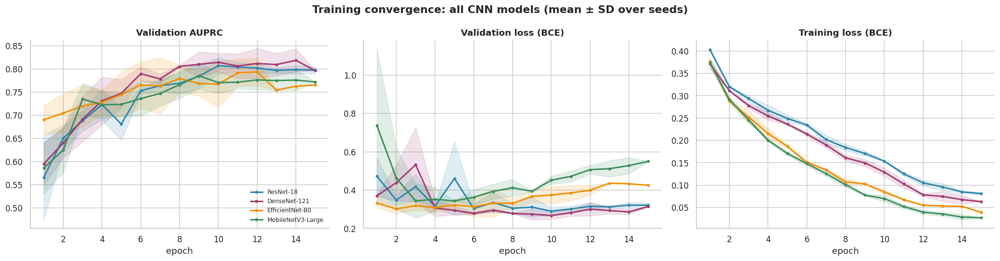

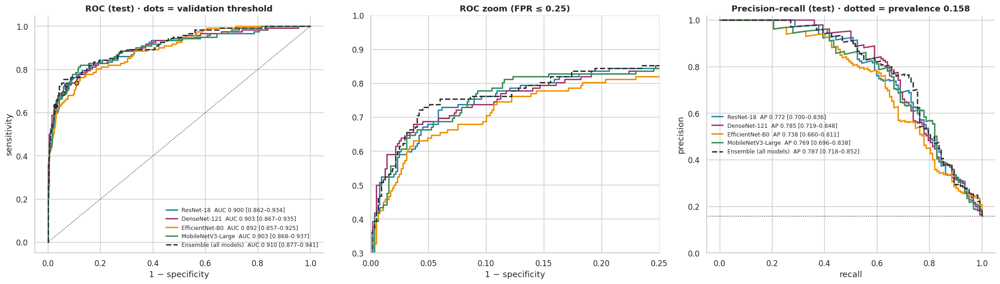

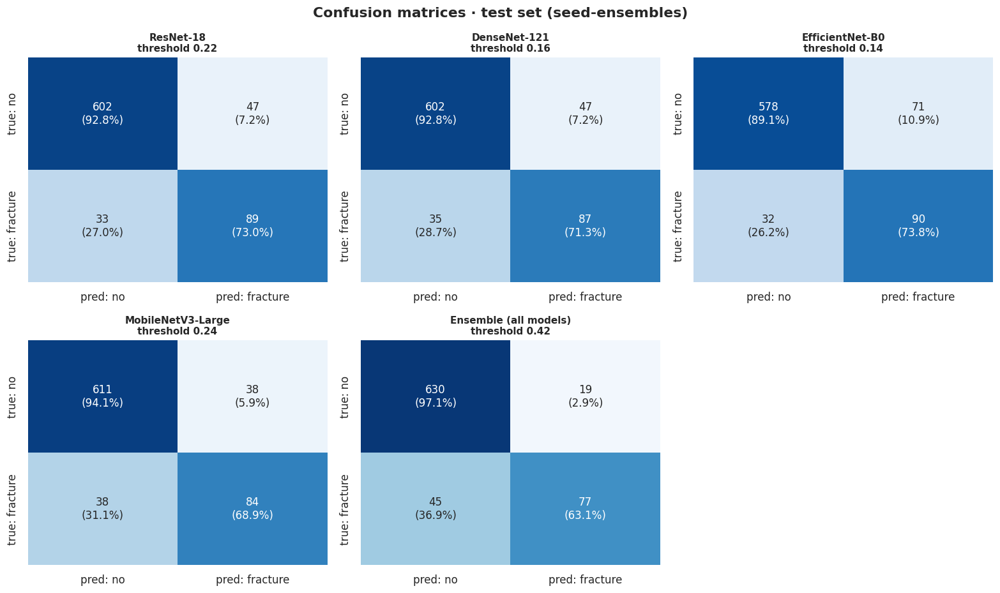

In [34]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  8.3  Convergence · ROC · precision–recall · confusion matrices║
# ╚══════════════════════════════════════════════════════════════════╝

h_all = pd.concat([pd.DataFrame(r['hist']) for n in ARCHS for r in MODEL_RUNS[n]]); h_all.to_csv(OUT / 'tables' / 'training_history_all_epochs.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for name in ARCHS:
    for ax, c, ls in [(axes[0], 'val_auprc', '-'), (axes[1], 'val_loss', '-'), (axes[2], 'train_loss', '-')]:
        g = h_all[h_all.model == name].groupby('epoch')[c].agg(['mean', 'std']).fillna(0); ax.plot(g.index, g['mean'], marker='o', ms=3, lw=2, color=MODEL_PAL[name], label=nice(name)); ax.fill_between(g.index, g['mean'] - g['std'], g['mean'] + g['std'], color=MODEL_PAL[name], alpha=.15)
for ax, t in zip(axes, ['Validation AUPRC', 'Validation loss (BCE)', 'Training loss (BCE)']): ax.set(title=t, xlabel='epoch')
axes[0].legend(frameon=False, fontsize=8); fig.suptitle('Training convergence: all CNN models (mean ± SD over seeds)', fontweight='bold'); finish(fig, 'E02_convergence_all_models')

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
for k in KEYS:
    ls = '--' if k == 'ensemble_all' else '-'; p = ens[k]['test']; fpr, tpr, _ = roc_curve(yt, p); pr, rc, _ = precision_recall_curve(yt, p); lo, hi = ci95(boot[k]['auroc'])
    axes[0].plot(fpr, tpr, color=PAL[k], ls=ls, lw=2, label=f'{nice(k)}  AUC {roc_auc_score(yt, p):.3f} [{lo:.3f}–{hi:.3f}]'); axes[1].plot(fpr, tpr, color=PAL[k], ls=ls, lw=2)
    tp, fp, fn, tn = confusion(yt, p, thr_main[k]); axes[0].plot(fp / (fp + tn), tp / (tp + fn), 'o', color=PAL[k], mec='k', ms=6)
    lo, hi = ci95(boot[k]['auprc']); axes[2].plot(rc, pr, color=PAL[k], ls=ls, lw=2, label=f'{nice(k)}  AP {average_precision_score(yt, p):.3f} [{lo:.3f}–{hi:.3f}]')
axes[0].plot([0, 1], [0, 1], 'k:', lw=1); axes[0].set(title='ROC (test) · dots = validation threshold', xlabel='1 − specificity', ylabel='sensitivity'); axes[0].legend(frameon=False, fontsize=8, loc='lower right')
axes[1].plot([0, 1], [0, 1], 'k:', lw=1); axes[1].set(title='ROC zoom (FPR ≤ 0.25)', xlabel='1 − specificity', xlim=(0, .25), ylim=(.3, 1.0))
axes[2].axhline(yt.mean(), color='k', ls=':', lw=1); axes[2].set(title=f'Precision–recall (test) · dotted = prevalence {yt.mean():.3f}', xlabel='recall', ylabel='precision', ylim=(0, 1.02)); axes[2].legend(frameon=False, fontsize=8)
finish(fig, 'E03_roc_pr_curves')

nc = min(3, len(KEYS)); nr = int(np.ceil(len(KEYS) / nc)); fig, axes = plt.subplots(nr, nc, figsize=(4.8 * nc, 4.3 * nr), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, k in zip(axes.ravel(), KEYS):
    tp, fp, fn, tn = confusion(yt, ens[k]['test'], thr_main[k]); cm = np.array([[tn, fp], [fn, tp]]); rp = cm / cm.sum(1, keepdims=True); ax.axis('on')
    sns.heatmap(rp, annot=np.array([[f'{cm[i, j]}\n({100 * rp[i, j]:.1f}%)' for j in range(2)] for i in range(2)]), fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=['pred: no', 'pred: fracture'], yticklabels=['true: no', 'true: fracture'], ax=ax, annot_kws={'fontsize': 11})
    ax.set_title(f'{nice(k)}\nthreshold {thr_main[k]:.2f}', fontsize=10)
fig.suptitle('Confusion matrices · test set (seed-ensembles)', fontweight='bold'); finish(fig, 'E04_confusion_matrices_test')

## 8.4 · Efficiency: parameters, compute and inference time

Timing: FP32, forward pass only, input on device, 224px | GPU: Tesla T4 | CPU threads: 4


,params_M,size_MB_fp32,GMACs,gpu_b1_ms_mean,gpu_b1_ms_sd,gpu_b1_ms_median,gpu_b1_ms_p95,gpu_throughput_img_s_bs32,gpu_peak_mem_GB_bs32,cpu_b1_ms_mean,cpu_b1_ms_sd,cpu_b1_ms_median,cpu_b1_ms_p95,cpu_throughput_img_s_bs8,train_min,sec_per_epoch
model,,,,,,,,,,,,,,,,
resnet18,11.18,44.71,1.81,3.55,0.93,3.15,5.77,1045.02,0.28,31.72,2.20,31.15,35.21,38.86,1.53,6.14
densenet121,6.95,27.82,2.83,15.30,1.16,15.02,16.83,317.18,0.39,88.35,2.62,87.69,92.31,15.50,3.86,16.52
efficientnet_b0,4.01,16.04,0.38,8.10,0.29,8.03,8.64,830.96,0.36,31.62,1.36,31.38,33.14,49.57,1.98,9.68
mobilenet_v3_large,4.20,16.81,0.22,6.30,0.28,6.25,6.92,1365.53,0.27,23.11,0.94,23.15,24.37,92.18,1.55,6.49


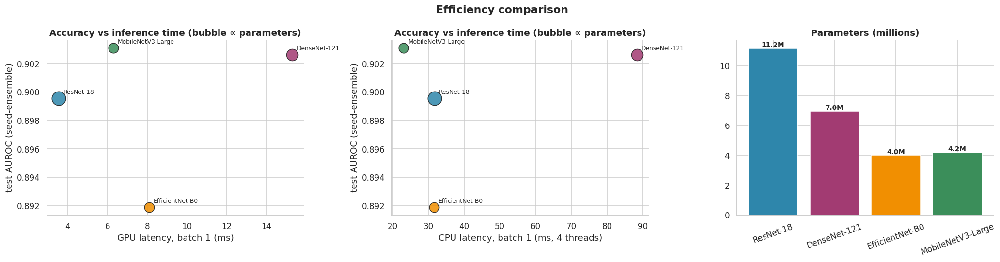

In [35]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  8.4  Efficiency: parameters · GMACs · inference time          ║
# ╚══════════════════════════════════════════════════════════════════╝

from torch.utils.flop_counter import FlopCounterMode
@torch.no_grad()
def lat(fn, repeats, warm, sync):
    for _ in range(warm): fn()
    if sync: torch.cuda.synchronize()
    ts = []
    for _ in range(repeats):
        t = time.perf_counter(); fn()
        if sync: torch.cuda.synchronize()
        ts.append((time.perf_counter() - t) * 1000)
    return np.array(ts)
summ_ = lambda a: dict(mean=a.mean(), sd=a.std(ddof=1) if len(a) > 1 else 0.0, median=float(np.median(a)), p95=float(np.percentile(a, 95)))
EFF = []; torch.set_num_threads(CPU_THREADS)
for name in ARCHS:
    m, _ = build_model(name, pretrained=False); m.eval(); params = sum(p.numel() for p in m.parameters())
    row = dict(model=name, params_M=params / 1e6, size_MB_fp32=params * 4 / 1e6); cpu = copy.deepcopy(m).cpu().eval(); x1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    try:
        with FlopCounterMode(display=False) as fc: cpu(x1)
        row['GMACs'] = fc.get_total_flops() / 2e9
    except Exception as e: row['GMACs'] = np.nan
    if DEVICE.type == 'cuda':
        xg1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE); xgb = torch.randn(32, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
        row.update({f'gpu_b1_ms_{k}': v for k, v in summ_(lat(lambda: m(xg1), TIMING['gpu_b1'], 20, True)).items()})
        torch.cuda.reset_peak_memory_stats(); b = lat(lambda: m(xgb), TIMING['gpu_bs'], 3, True); row['gpu_throughput_img_s_bs32'] = 32 / (b.mean() / 1000); row['gpu_peak_mem_GB_bs32'] = torch.cuda.max_memory_allocated() / 2**30
    row.update({f'cpu_b1_ms_{k}': v for k, v in summ_(lat(lambda: cpu(x1), TIMING['cpu_b1'], 3, False)).items()})
    xc8 = torch.randn(8, 3, IMG_SIZE, IMG_SIZE); row['cpu_throughput_img_s_bs8'] = 8 / (lat(lambda: cpu(xc8), TIMING['cpu_bs'], 1, False).mean() / 1000); EFF.append(row)
    del m, cpu
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
eff_df = pd.DataFrame(EFF).set_index('model')
eff_df = eff_df.join(pd.DataFrame([dict(model=r['model'], train_min=r['train_time_s'] / 60, sec_per_epoch=r['train_time_s'] / r['epochs_run']) for n in ARCHS for r in MODEL_RUNS[n]]).groupby('model').mean())
eff_df.round(3).to_csv(OUT / 'tables' / 'efficiency_and_training_cost.csv'); print(f'Timing: FP32, forward pass only, input on device, {IMG_SIZE}px | GPU: {ENV_GPU} | CPU threads: {CPU_THREADS}'); display(eff_df.round(2))
fig, axes = plt.subplots(1, 3, figsize=(19, 5)); ci_i = ci_df.set_index('model')
xcols = [('gpu_b1_ms_mean', 'GPU latency, batch 1 (ms)'), ('cpu_b1_ms_mean', f'CPU latency, batch 1 (ms, {CPU_THREADS} threads)')]
for ax, (xc, xl) in zip(axes[:2], xcols):
    if xc not in eff_df: ax.axis('off'); ax.set_title('(no GPU in this session)'); continue
    for m_ in ARCHS:
        ax.scatter(eff_df.loc[m_, xc], ci_i.loc[nice(m_), 'auroc'], s=80 + 24 * eff_df.loc[m_, 'params_M'], color=MODEL_PAL[m_], edgecolor='k', alpha=.85); ax.annotate(nice(m_), (eff_df.loc[m_, xc], ci_i.loc[nice(m_), 'auroc']), xytext=(6, 6), textcoords='offset points', fontsize=8)
    ax.set(xlabel=xl, ylabel='test AUROC (seed-ensemble)', title='Accuracy vs inference time (bubble ∝ parameters)')
bars = axes[2].bar([nice(m_) for m_ in ARCHS], eff_df.loc[ARCHS, 'params_M'], color=[MODEL_PAL[m_] for m_ in ARCHS], edgecolor='white')
for b_, v in zip(bars, eff_df.loc[ARCHS, 'params_M']): axes[2].text(b_.get_x() + b_.get_width() / 2, v + .1, f'{v:.1f}M', ha='center', fontsize=9, fontweight='bold')
axes[2].set(title='Parameters (millions)'); axes[2].tick_params(axis='x', rotation=20); fig.suptitle('Efficiency comparison', fontweight='bold'); finish(fig, 'E05_efficiency')

## 8.5 · Pairwise comparison and threshold analysis

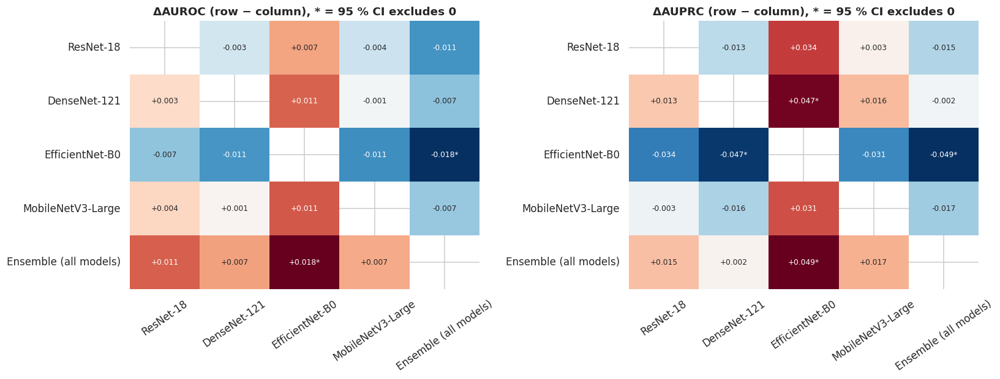

1 of 10 model pairs differ credibly in AUROC (95 % CI excludes 0). With many pairs, a CI that barely excludes 0 should be treated with caution; intervals cover test-case variation, not seed variation.


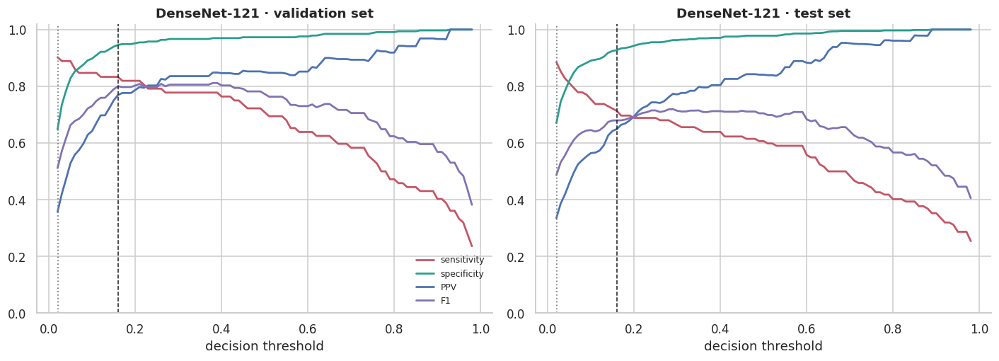

In [36]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  8.5  Pairwise model comparison (paired bootstrap)             ║
# ╚══════════════════════════════════════════════════════════════════╝

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, m in zip(axes, ['auroc', 'auprc']):
    M = np.full((len(KEYS), len(KEYS)), np.nan); A = np.empty((len(KEYS), len(KEYS)), dtype=object); A[:] = ''
    for i, a_ in enumerate(KEYS):
        for j, b_ in enumerate(KEYS):
            if i == j: continue
            r = pw_df[(pw_df.model_a == nice(a_)) & (pw_df.model_b == nice(b_)) & (pw_df.metric == m)].iloc[0]; M[i, j] = r['diff']; A[i, j] = f'{r["diff"]:+.3f}' + ('*' if r.excludes_zero else '')
    sns.heatmap(M, annot=A, fmt='', cmap='RdBu_r', center=0, cbar=False, xticklabels=[nice(k) for k in KEYS], yticklabels=[nice(k) for k in KEYS], ax=ax, annot_kws={'fontsize': 8}); ax.set_title(f'Δ{m.upper()} (row − column), * = 95 % CI excludes 0'); ax.tick_params(axis='x', rotation=35)
finish(fig, 'E06_pairwise_differences')
n_sig = int(pw_df[pw_df.metric == 'auroc'].excludes_zero.sum() // 2); n_pairs = len(KEYS) * (len(KEYS) - 1) // 2
print(f'{n_sig} of {n_pairs} model pairs differ credibly in AUROC (95 % CI excludes 0). With many pairs, a CI that barely excludes 0 should be treated with caution; intervals cover test-case variation, not seed variation.')

# threshold analysis for the best model
pb_v, pb_t = ens[BEST]['val'], ens[BEST]['test']; ts_ = np.linspace(0.02, 0.98, 97); fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (y_, p_, nm) in zip(axes, [(yv, pb_v, 'validation'), (yt, pb_t, 'test')]):
    mt = pd.DataFrame([full_metrics(y_, p_, t) for t in ts_])
    for c, lab, col in [('sensitivity', 'sensitivity', '#C45566'), ('specificity', 'specificity', '#2A9D8F'), ('ppv', 'PPV', '#4C72B0'), ('f1', 'F1', '#8172B3')]: ax.plot(ts_, mt[c], label=lab, color=col, lw=1.8)
    ax.axvline(thr[BEST]['main'], color='k', ls='--', lw=1); ax.axvline(thr[BEST]['sens90'], color='gray', ls=':', lw=1.2); ax.set(title=f'{nice(BEST)} · {nm} set', xlabel='decision threshold', ylim=(0, 1.02))
axes[0].legend(frameon=False, fontsize=8); finish(fig, 'E07_threshold_analysis_best_model')

# Section 9: Error Analysis & Explainability

Where does the best model fail, and is it looking at the right thing? Subgroup tables flag small cells (< 10 fractured or < 10 healthy images) as unreliable. Grad-CAM is an exploratory, qualitative check (bone vs markers, borders or hardware), not proof of reasoning.

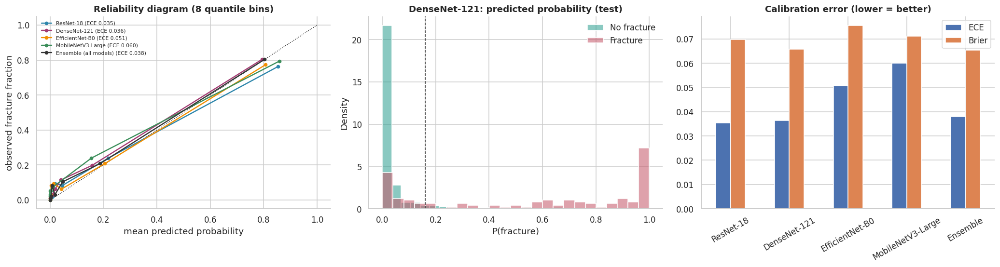

Subgroup performance · DenseNet-121 · test set


,variable,level,n,fractured,healthy,auroc,sensitivity,sens_lo,sens_hi,specificity,spec_lo,spec_hi,reliable
0,body_region,hand,251,61,190,0.865,0.705,0.581,0.804,0.858,0.801,0.900,True
1,body_region,hip,44,2,42,NaN,1.000,0.342,1.000,1.000,0.916,1.000,False
2,body_region,leg,379,37,342,0.868,0.676,0.515,0.804,0.980,0.958,0.990,True
3,body_region,mixed,73,20,53,0.902,0.800,0.584,0.919,0.774,0.645,0.865,True
4,body_region,shoulder,24,2,22,NaN,0.500,0.095,0.905,0.955,0.782,0.992,False
5,view,frontal,435,66,369,0.928,0.727,0.610,0.820,0.949,0.921,0.967,True
6,view,frontal+lateral,48,10,38,0.932,0.900,0.596,0.982,0.789,0.637,0.889,True
7,view,frontal+oblique,3,1,2,NaN,1.000,0.207,1.000,0.500,0.095,0.905,False
8,view,lateral,210,36,174,0.885,0.694,0.531,0.820,0.908,0.856,0.943,True
9,view,lateral+oblique,5,2,3,NaN,1.000,0.342,1.000,1.000,0.438,1.000,False


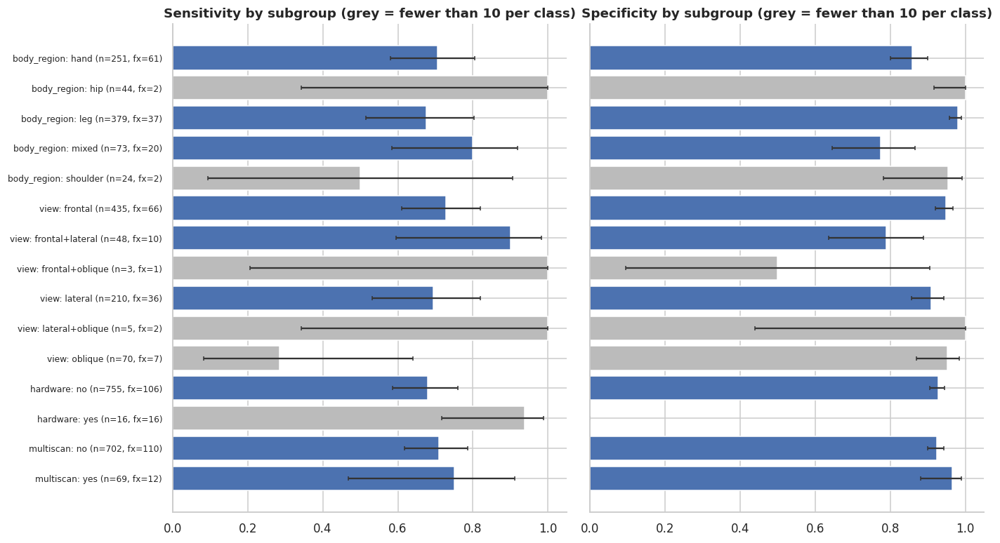

In [37]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  9.1  Calibration · confidence distribution · subgroups        ║
# ╚══════════════════════════════════════════════════════════════════╝

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2)); axes[0].plot([0, 1], [0, 1], 'k:', lw=1)
for k in KEYS:
    fr, mp = calibration_curve(yt, ens[k]['test'], n_bins=8, strategy='quantile'); axes[0].plot(mp, fr, 'o-', color=PAL[k], ms=4, lw=1.6, label=f'{nice(k)} (ECE {ece_score(yt, ens[k]["test"]):.3f})')
axes[0].set(xlabel='mean predicted probability', ylabel='observed fracture fraction', title='Reliability diagram (8 quantile bins)'); axes[0].legend(frameon=False, fontsize=7)
for c, col in [(0, '#2A9D8F'), (1, '#C45566')]: sns.histplot(ens[BEST]['test'][yt == c], bins=25, stat='density', color=col, alpha=.55, label=['No fracture', 'Fracture'][c], ax=axes[1])
axes[1].axvline(thr[BEST]['main'], color='k', ls='--', lw=1); axes[1].set(title=f'{nice(BEST)}: predicted probability (test)', xlabel='P(fracture)'); axes[1].legend(frameon=False)
cal = pd.DataFrame({'ECE': [ece_score(yt, ens[k]['test']) for k in KEYS], 'Brier': [brier_score_loss(yt, ens[k]['test']) for k in KEYS]}, index=[nice(k).replace('Ensemble (all models)', 'Ensemble') for k in KEYS])
cal.plot.bar(ax=axes[2], rot=30, color=['#4C72B0', '#DD8452']); axes[2].set(title='Calibration error (lower = better)'); finish(fig, 'X01_calibration_and_confidence')

te = parts['test'].copy(); te['p'] = ens[BEST]['test']; t_b = thr[BEST]['main']; rows = []
for var in ['body_region', 'view', 'hardware', 'multiscan']:
    if var not in te or te[var].isna().all(): continue
    for lvl, g in te.dropna(subset=[var]).groupby(var):
        y_, p_ = g.label.values, g.p.values; pos, neg = int(y_.sum()), int((y_ == 0).sum()); tp = int(((p_ >= t_b) & (y_ == 1)).sum()); tn = int(((p_ < t_b) & (y_ == 0)).sum()); sl, sh = wilson(tp, pos); pl, ph_ = wilson(tn, neg)
        rows.append(dict(variable=var, level=str(lvl), n=len(g), fractured=pos, healthy=neg, auroc=safe_auc(y_, p_) if min(pos, neg) >= 3 else np.nan, sensitivity=tp / pos if pos else np.nan, sens_lo=sl, sens_hi=sh,
                         specificity=tn / neg if neg else np.nan, spec_lo=pl, spec_hi=ph_, reliable=(pos >= 10 and neg >= 10)))
sub_df = pd.DataFrame(rows); sub_df.round(4).to_csv(OUT / 'tables' / 'subgroups_best_model.csv', index=False); print(f'Subgroup performance · {nice(BEST)} · test set'); display(sub_df.round(3))
if len(sub_df):
    fig, axes = plt.subplots(1, 2, figsize=(13, max(3.5, .38 * len(sub_df) + 1.5))); lab = [f'{r.variable}: {r.level} (n={r.n}, fx={r.fractured})' for r in sub_df.itertuples()]; yy = np.arange(len(sub_df))[::-1]
    for ax, (c, lo, hi, ttl) in zip(axes, [('sensitivity', 'sens_lo', 'sens_hi', 'Sensitivity'), ('specificity', 'spec_lo', 'spec_hi', 'Specificity')]):
        v = sub_df[c].values; ax.barh(yy, np.nan_to_num(v), color=['#4C72B0' if r else '#BBBBBB' for r in sub_df.reliable], xerr=errbars(v, sub_df[lo].values, sub_df[hi].values), capsize=2, ecolor='#333')
        ax.set_yticks(yy); ax.set_yticklabels(lab if c == 'sensitivity' else [''] * len(lab), fontsize=8); ax.set_xlim(0, 1.05); ax.set_title(f'{ttl} by subgroup (grey = fewer than 10 per class)')
    finish(fig, 'X02_subgroup_performance')

{'correct': 689, 'false positive': 47, 'false negative': 35}
High-confidence errors (confidence > 70 %): 38


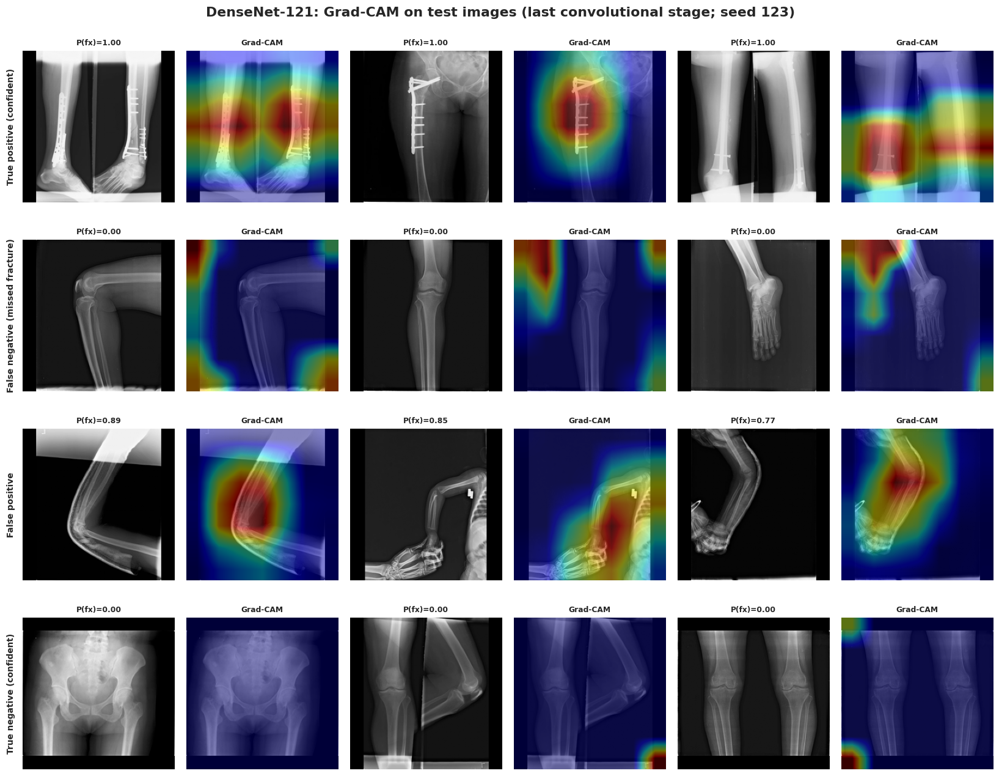

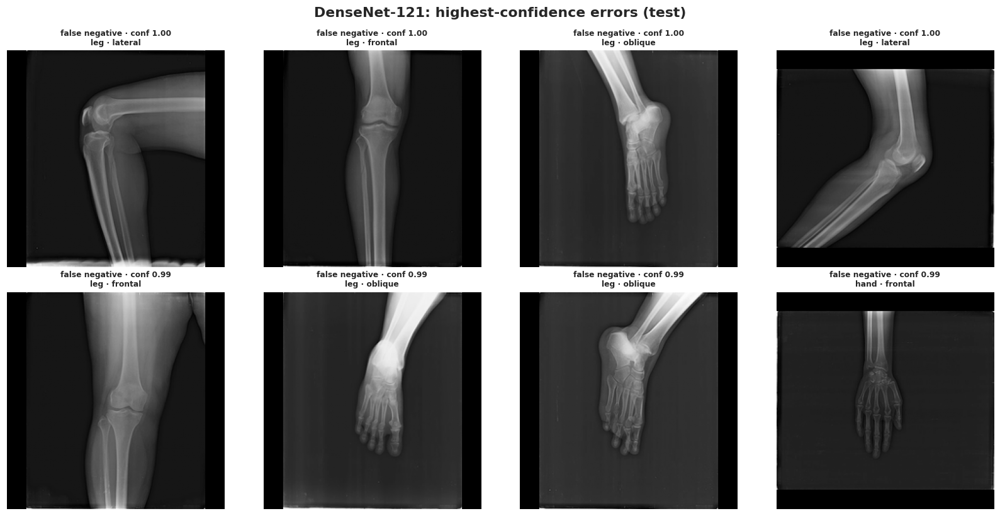

In [38]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  9.2  Error cases · high-confidence errors · Grad-CAM          ║
# ╚══════════════════════════════════════════════════════════════════╝

te['pred'] = (te.p >= t_b).astype(int); te['error'] = np.where((te.label == 1) & (te.pred == 0), 'false negative', np.where((te.label == 0) & (te.pred == 1), 'false positive', 'correct'))
te['confidence'] = np.where(te.pred == 1, te.p, 1 - te.p)
te.loc[te.error != 'correct', ['path', 'label', 'p', 'confidence', 'error'] + [c for c in ['body_region', 'view', 'hardware'] if c in te]].sort_values(['error', 'confidence'], ascending=[True, False]).to_csv(OUT / 'tables' / 'error_cases_best_model.csv', index=False)
print(te.error.value_counts().to_dict()); hard = te[(te.error != 'correct') & (te.confidence > 0.7)].sort_values('confidence', ascending=False); print(f'High-confidence errors (confidence > 70 %): {len(hard)}')

def grad_cam(model, x, layer):
    store = {}
    def fh(m, i, o): store['a'] = o; o.register_hook(lambda g_: store.__setitem__('g', g_))
    h = layer.register_forward_hook(fh); model.eval(); model.zero_grad(set_to_none=True); out = model(x.to(DEVICE)); out.sum().backward(); h.remove()
    w = store['g'].mean((2, 3), keepdim=True); cam = F.relu((w * store['a']).sum(1, keepdim=True)); cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0].detach().cpu()
    mn_, mx_ = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True); return ((cam - mn_) / (mx_ - mn_ + 1e-8)).numpy()

best_run = max(MODEL_RUNS[BEST], key=lambda r: safe_ap(yv, r['p_val']))
mdl, _ = build_model(BEST, pretrained=False); mdl.load_state_dict(torch.load(best_run['ckpt'], map_location=DEVICE)); layer = cam_target(mdl, BEST)
sel = {'True positive (confident)': te[(te.label == 1) & (te.pred == 1)].nlargest(3, 'p'), 'False negative (missed fracture)': te[te.error == 'false negative'].nsmallest(3, 'p'),
       'False positive': te[te.error == 'false positive'].nlargest(3, 'p'), 'True negative (confident)': te[(te.label == 0) & (te.pred == 0)].nsmallest(3, 'p')}
fig, axes = plt.subplots(len(sel), 6, figsize=(15, 2.9 * len(sel)), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ri, (title, d_) in enumerate(sel.items()):
    for c_, (_, r) in enumerate(d_.iterrows()):
        x = XrayDS(pd.DataFrame([r]))[0][0][None]; cam = grad_cam(mdl, x, layer); img = IMGS[r.path].numpy(); a1, a2 = axes[ri, 2 * c_], axes[ri, 2 * c_ + 1]
        a1.imshow(img, cmap='gray'); a2.imshow(img, cmap='gray'); a2.imshow(cam[0], cmap='jet', alpha=.45); a1.set_title(f'P(fx)={r.p:.2f}', fontsize=8); a2.set_title('Grad-CAM', fontsize=8)
    axes[ri, 0].text(-0.05, 0.5, title, transform=axes[ri, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9, fontweight='bold')
fig.suptitle(f'{nice(BEST)}: Grad-CAM on test images (last convolutional stage; seed {best_run["seed"]})', y=1.0, fontweight='bold'); finish(fig, 'X03_gradcam_best_model', svg=False)
if len(hard):
    sh = hard.head(8); fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), sh.iterrows()):
        ax.imshow(IMGS[r.path].numpy(), cmap='gray'); ax.set_title(f'{r.error} · conf {r.confidence:.2f}\n{r.get("body_region", "")} · {r.get("view", "")}', fontsize=8)
    fig.suptitle(f'{nice(BEST)}: highest-confidence errors (test)', fontweight='bold'); finish(fig, 'X04_high_confidence_errors', svg=False)
del mdl

### Error analysis: discussion template
After reading the figures above, summarise in the report: (1) which body regions, views or hardware cases have the lowest sensitivity (`X02`, `subgroups_best_model.csv`); (2) whether confident errors share a pattern, such as markers, casts, implants, very low contrast or unusual views (`X04`); (3) whether Grad-CAM highlights bone or borders and text (`X03`); (4) how calibration changes the usable threshold (`X01`); (5) which corruptions hurt most (`R02`–`R04`). Write only what the figures support.

# Section 10: Final Summary & Export

In [39]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  10  Final results summary · paper notes · export              ║
# ╚══════════════════════════════════════════════════════════════════╝

def md_table(df, index=True):
    d = df.reset_index() if index else df.copy(); cols = [str(c) for c in d.columns]
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in d.iterrows(): lines.append('| ' + ' | '.join(f'{v:.3f}' if isinstance(v, float) else str(v) for v in r.values) + ' |')
    return '\n'.join(lines)
def save_table(df, name, index=True):
    (OUT / 'tables' / f'{name}.md').write_text(md_table(df, index))
    try: (OUT / 'tables' / f'{name}.tex').write_text(df.to_latex(index=index, escape=True))
    except Exception as e: print(f'LaTeX export skipped for {name}: {type(e).__name__}')
save_table(tab1, 'table1_mean_sd_over_seeds'); save_table(tab2, 'table2_formatted')

print('=' * 100); print('FINAL CNN RESULTS SUMMARY'); print('=' * 100)
fin = pd.DataFrame([dict(Model=nice(n) + (' *' if n == BEST else ''), Params=f'{PM.loc["params", n]:.2f}M', TestAUROC=f'{ci_i.loc[nice(n), "auroc"]:.3f}', TestAUPRC=f'{ci_i.loc[nice(n), "auprc"]:.3f}', Sens=f'{ci_i.loc[nice(n), "sensitivity"]:.3f}',
                    Spec=f'{ci_i.loc[nice(n), "specificity"]:.3f}', F1=f'{ci_i.loc[nice(n), "f1"]:.3f}', BestEp=f'{PM.loc["best_epoch", n]:.1f}', TrainAUROC=f'{PM.loc["tr_auroc", n]:.3f}', ValAUROC=f'{PM.loc["va_auroc", n]:.3f}',
                    Robust=f'{summ.loc[nice(n), "mean_retention_pct"]:.1f}%', GPUms=(f'{eff_df.loc[n, "gpu_b1_ms_mean"]:.2f}' if 'gpu_b1_ms_mean' in eff_df else 'n/a'), CPUms=f'{eff_df.loc[n, "cpu_b1_ms_mean"]:.1f}') for n in ARCHS])
print(fin.to_string(index=False)); fin.to_csv(OUT / 'tables' / 'final_summary.csv', index=False)
print(f'\nBest model (highest mean validation AUPRC): {nice(BEST)}   * = selected on validation, never on test')

pred = parts['test'][['path', 'group_id', 'label']].copy()
for k in KEYS: pred[f'p_{nice(k)}'] = ens[k]['test']
pred.to_csv(OUT / 'tables' / 'test_predictions_seed_ensembles.csv', index=False)
ENV = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__, device=str(DEVICE), gpu=ENV_GPU, platform=platform.platform())
(OUT / 'run_config_training.json').write_text(json.dumps(dict(env=ENV, models=ARCHS, seeds=SEEDS, img_size=IMG_SIZE, epochs=EPOCHS, patience=PATIENCE, batch=BATCH, lr=LR, weight_decay=WD, loss=LOSS, aug=AUG,
    pretrained=PRETRAINED, pretrained_loaded=PRETRAINED_OK, threshold_rule=THRESHOLD_RULE, norm_mean=MEAN, norm_std=STD, n_boot=N_BOOT, selected_by_val_auprc=BEST, split=split_tab.reset_index().to_dict('records')), indent=2, default=str))
b = ci_i.loc[nice(BEST)]; ncorr = int(summ.shape[0])
notes = f"""# Paper notes (auto-generated from this run)

## Data and split
FracAtlas, cleaned: exact duplicates, label conflicts and COCO-box disagreements removed; near-duplicate images grouped into families and kept in one split (family-grouped, label-stratified 70/10/20). FracAtlas has no patient IDs, so the split is family-level, not patient-level.
{md_table(split_tab)}
External set: HBFMID originals (valid/test folders, X-ray inferred from filenames, no family overlap with FracAtlas); never used for training, thresholds or model selection.

## Training protocol
Models: {', '.join(nice(m) for m in ARCHS)} (torchvision, ImageNet weights loaded: {PRETRAINED_OK}); single-logit head; input {IMG_SIZE}x{IMG_SIZE}, letterboxed grayscale repeated to 3 channels, normalised with train mean/std ({MEAN:.4f}/{STD:.4f}).
Loss: {'binary cross-entropy' if LOSS == 'bce' else 'weighted binary cross-entropy'}. Augmentation ({'both classes, training only' if AUG == 'all' else 'none'}): rotation ±10°, scale ±8%, translation ±5%, horizontal flip, brightness ±5%, contrast ±10%, border-replicated fill.
AdamW (lr {LR}, weight decay {WD}), cosine annealing over {EPOCHS} epochs, batch {BATCH}, gradient clipping 1.0, mixed precision on GPU, early stopping on validation AUPRC (patience {PATIENCE}); seeds {SEEDS}.
Decision threshold chosen on validation ({THRESHOLD_RULE}); 95 % CIs from a cluster bootstrap over image families ({N_BOOT} resamples). Hardware: {ENV_GPU or 'CPU only'}; torch {ENV['torch']}.

## Main results (test set, seed-ensemble, 95 % CI)
{md_table(tab2)}

Mean ± SD over seeds:
{md_table(tab1)}

## Robustness (test AUROC retained, mean over severities)
{md_table(summ[['mean_retention_pct', 'mean_worst_drop']].round(3))}

## Efficiency
{md_table(eff_df[[c for c in ['params_M', 'GMACs', 'gpu_b1_ms_mean', 'cpu_b1_ms_mean', 'train_min'] if c in eff_df]].round(2).rename(index=nice))}

## Best model by validation AUPRC: {nice(BEST)}
Test AUROC {b.auroc:.3f} ({b.auroc_lo:.3f}-{b.auroc_hi:.3f}), AUPRC {b.auprc:.3f} ({b.auprc_lo:.3f}-{b.auprc_hi:.3f}) at prevalence {yt.mean():.3f}; sensitivity {b.sensitivity:.3f}, specificity {b.specificity:.3f}, F1 {b.f1:.3f}, MCC {b.mcc:.3f}, ECE {b.ece:.3f}.
Model pairs with a credible AUROC difference (95 % CI excludes 0): {n_sig} of {n_pairs}.

## Caveats to state
- Family-level, not patient-level split; {len(SEEDS)} seed(s); {int(yt.sum())} fractured test images, so intervals are wide.
- External set has {int((ye == 0).sum()) if len(ye) else 0} healthy images: only sensitivity is meaningful; domain shift (resolution, borders, contrast) is large.
- Corruption tests are synthetic; Grad-CAM is qualitative; test numbers are descriptive and were not used for any choice.
"""
(OUT / 'paper_notes.md').write_text(notes)
zp = shutil.make_archive(str(OUT.parent / 'bone_fracture_cnn_outputs'), 'zip', OUT)
print('\nOutputs :', OUT, '\nZip     :', zp, '\nWeights :', CKPT_DIR); print('Figures :', len(list((OUT / 'figures').glob('*.png'))), 'PNG |', 'Tables :', len(list((OUT / 'tables').glob('*.csv'))), 'CSV')

FINAL CNN RESULTS SUMMARY
            Model Params TestAUROC TestAUPRC  Sens  Spec    F1 BestEp TrainAUROC ValAUROC Robust GPUms CPUms
        ResNet-18 11.18M     0.900     0.772 0.730 0.928 0.690   11.0      0.990    0.915  90.0%  3.55  31.7
   DenseNet-121 *  6.95M     0.903     0.785 0.713 0.928 0.680    9.7      0.990    0.923  90.8% 15.30  88.3
  EfficientNet-B0  4.01M     0.892     0.738 0.738 0.891 0.636    8.0      0.992    0.916  89.5%  8.10  31.6
MobileNetV3-Large  4.20M     0.903     0.769 0.689 0.941 0.689   10.3      0.997    0.914  90.5%  6.30  23.1

Best model (highest mean validation AUPRC): DenseNet-121   * = selected on validation, never on test

Outputs : /kaggle/working/bone_fracture_cnn 
Zip     : /kaggle/working/bone_fracture_cnn_outputs.zip 
Weights : /kaggle/working/bone_fracture_cnn_checkpoints
Figures : 48 PNG | Tables : 24 CSV
